# Imports

In [488]:
import pandas as pd
import numpy as np
import sys
import os
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.linalg import pinv
from scipy.stats import pearsonr
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score


sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

# Variables

In [489]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_output = '../../../1_allele_collection/3_outputs'

In [490]:
scoring_conditions = ['LWH1', 'LWH10', 'LWH25']
aa_id = 0
rrs_id = 999999.0
max_score = 800
max_size = 1200
min_growth_score = 200
original_datafile_path = 'sqY2H_manual_automated_annotated_scores_size.csv'
tracking_dict = {}

# Single functions

In [491]:
def pull_numbers(df, verbose=False):
    df = pl.DataFrame(df)
    
    if 'per_well_integrated_intensity_gray' in df.columns:
        df = df.filter(pl.col('per_well_integrated_intensity_gray').is_not_null())
        df = df.filter(pl.col('per_well_integrated_intensity_gray').is_not_nan())
    
    if 'consensus_score' in df.columns:
        df = df.filter(pl.col('consensus_score').is_not_null())
        df = df.filter(pl.col('consensus_score').is_not_nan())
    
    dbs = df.select(pl.col('db_orf_id')).n_unique()
    ads = df.select(pl.col('ad_orf_id')).n_unique()
    
    df = df.with_columns(
        pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("edge_group"),
            pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group"),
    )
    
    muts = df.filter(pl.col('db_mut_id') != 0).select(pl.col('db_mut_id')).n_unique()
    
    if verbose:
        print('Number of rows:', df.height)
    
    return {'dbs': dbs, 'ads': ads, 'alleles': muts, 'edges': df.select(pl.col('edge_group')).n_unique(), 'ppis': df.select(pl.col('ppi_group')).n_unique()}

In [492]:
def load_original_dataframe(file_path, inputs_dir=inputs_dir, tracking_dict=tracking_dict):
    df = pd.read_csv(os.path.join(inputs_dir, file_path))
    
        
    # cast all to same format
    df['ad_orf_id'] = pd.to_numeric(df['ad_orf_id'], errors='coerce')
    df['db_orf_id'] = pd.to_numeric(df['db_orf_id'], errors='coerce')
    df['db_mut_id'] = pd.to_numeric(df['db_mut_id'], errors='coerce')


    return df, tracking_dict
    


In [493]:
orig_df, tracking_dict = load_original_dataframe(file_path=original_datafile_path)

In [494]:
pl.from_pandas(orig_df)

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count
str,str,str,str,str,str,f64,bool,f64,f64,f64,f64,str,str,str,str,f64,f64,i64,i64
"""VUSAPWT1B1r01_001""","""A01""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""",1.0,true,null,null,null,null,"""DB_hap_ctrl""","""A10""","""AD_hap_ctrl""","""A10""",490.572572,4.0,963,1
"""VUSAPWT1B1r01_001""","""A02""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""",1.0,true,null,null,null,null,"""DB_hap_ctrl""","""A10""","""AD_hap_ctrl""","""A10""",521.929437,4.0,1032,1
"""VUSAPWT1B1r01_001""","""A03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""",1.0,false,0.0,null,2651.0,0.0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A1_2_6""","""A01""",455.65623,4.0,899,1
"""VUSAPWT1B1r01_001""","""A04""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""",1.0,false,0.0,null,2651.0,0.0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A1_2_6""","""A01""",544.3046,4.0,1050,1
"""VUSAPWT1B1r01_001""","""A05""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""",1.0,false,0.0,null,7215.0,0.0,"""DisWTGDEh03""","""E01""","""CEGSint_Y8A1_2_6""","""A01""",505.925513,4.0,970,1
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_036""","""P20""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""",1.0,false,1.00069191e8,null,54308.0,218854.0,"""VUSMutY8Dh022""","""H09""","""CEGSint_Y8A_6""","""E11""",435.596088,2.0,962,2
"""VUSAPWT1B1r06_036""","""P21""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""",1.0,false,1.00069191e8,null,54308.0,218855.0,"""VUSMutY8Dh022""","""B10""","""CEGSint_Y8A_6""","""E11""",811.030089,2.0,1642,2
"""VUSAPWT1B1r06_036""","""P22""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""",1.0,false,1.00069191e8,null,54308.0,218855.0,"""VUSMutY8Dh022""","""B10""","""CEGSint_Y8A_6""","""E11""",830.430091,2.0,1637,3


In [495]:
# Remove unwanted columns from orig_df before creating assay files
cols_to_remove = ['ad_mut_id', 'db_source_plate', 'db_source_well', 'ad_source_plate', 'ad_source_well']

# Files for DACC, raw measurements, split by assay id
for assay_id in orig_df.assay_id.unique():
    assay_df = orig_df[(orig_df.assay_id == assay_id) & (orig_df.condition_name.isin(scoring_conditions + ['LW']))]
    
    # Drop unwanted columns
    assay_df = assay_df.drop(columns=cols_to_remove, errors='ignore')
    
    if assay_id == 6.0:
        assay_df.to_csv(os.path.join(outputs_dir, f'sqY2H_raw_measurements_assay_3.csv'), index=False)
    elif assay_id == assay_id:
        assay_df.to_csv(os.path.join(outputs_dir, f'sqY2H_raw_measurements_assay_{int(assay_id)}.csv'), index=False)

In [549]:
dacc_conditions = ['LW', 'LWH1', 'LWH10', 'LWH25']

# number of large plates (large_plate_name) per assay (assay_id)
orig_df[orig_df.condition_name.isin(dacc_conditions)].groupby(['assay_id', 'condition_name'])['large_plate_name'].nunique()

assay_id  condition_name
1.0       LW                14
          LWH1              14
          LWH10             14
          LWH25             14
2.0       LW                 4
          LWH1               4
          LWH10              4
          LWH25              4
6.0       LW                 5
          LWH1               5
          LWH10              5
          LWH25              5
Name: large_plate_name, dtype: int64

In [554]:
import numpy as np

# 1. Define Data
wt = np.array([585, 303])
variants = {
    "Var1": np.array([498, 248]),
    "Var2": np.array([35, np.nan]),
    "Var3": np.array([np.nan, 98])
}

n_edges = 2  # Total interactors (edges)

# 2. Calculate Distances
print(f"{'Variant':<10} | {'Norm. Dist':<15}")
print("-" * 25)

for name, var_data in variants.items():
    # Identify valid indices (exclude NaNs)
    # Note: WT has no NaNs here, but we check both for robustness
    mask = ~np.isnan(wt) & ~np.isnan(var_data)
    
    # Calculate squared differences on valid data
    # print(wt[mask], var_data[mask])
    sq_diff = (wt[mask] - var_data[mask]) ** 2
    # print(sq_diff)
    # Count valid pairs (m)
    m_valid = np.sum(mask)
    
    # Standard Euclidean with Missing Data Adjustment:
    # d_eucl = sqrt( (n_edges / m_valid) * sum(sq_diff) )
    d_eucl = np.sqrt((n_edges / m_valid) * np.sum(sq_diff))
    
    # Normalize by sqrt(n_edges) as requested
    # d_norm = d_eucl / sqrt(n_edges)
    d_norm = d_eucl / np.sqrt(n_edges)
    
    print(f"{name:<10} | {d_norm:<15.2f}")

Variant    | Norm. Dist     
-------------------------
Var1       | 72.78          
Var2       | 550.00         
Var3       | 205.00         


In [558]:
import numpy as np

# 1. Define Data
wt = np.array([585, 303])
variants = {
    "Var1": np.array([498, 248]),
    "Var2": np.array([35, 35]),
    "Var3": np.array([98, 98])
}

n_edges = 2  # Total interactors (edges)

# 2. Calculate Distances
print(f"{'Variant':<10} | {'Norm. Dist':<15}")
print("-" * 25)

for name, var_data in variants.items():
    # Identify valid indices (exclude NaNs)
    # Note: WT has no NaNs here, but we check both for robustness
    mask = ~np.isnan(wt) & ~np.isnan(var_data)
    
    # Calculate squared differences on valid data
    # print(wt[mask], var_data[mask])
    sq_diff = (wt[mask] - var_data[mask]) ** 2
    # print(sq_diff)
    # Count valid pairs (m)
    m_valid = np.sum(mask)
    
    # Standard Euclidean with Missing Data Adjustment:
    # d_eucl = sqrt( (n_edges / m_valid) * sum(sq_diff) )
    d_eucl = np.sqrt((n_edges / m_valid) * np.sum(sq_diff))
    
    # Normalize by sqrt(n_edges) as requested
    # d_norm = d_eucl / sqrt(n_edges)
    d_norm = d_eucl / np.sqrt(n_edges)
    
    print(f"{name:<10} | {d_norm:<15.2f}")

Variant    | Norm. Dist     
-------------------------
Var1       | 72.78          
Var2       | 432.62         
Var3       | 373.63         


In [496]:
def initial_qaqc_old(df, tracking_dict=tracking_dict):
    # Remove rows where manual_score_growth is NaN because those wells are flagged as contamination
    # do not drop but replace the automatic scores by nan
    
    df['contamination'] = df['manual_score_growth'].isna()
    df.loc[df['manual_score_growth'].isna(), 'per_well_integrated_intensity_gray'] = np.nan

    tracking_dict['1. Initial data'] = pull_numbers(df, verbose=False)
    
    # Remove wrongly mapped wells with abnormally high automated scores
    df['outlier_score'] = df['per_well_integrated_intensity_gray'] > max_score
    df['per_well_integrated_intensity_gray'] = df.apply(lambda row: np.nan if row['outlier_score'] else row['per_well_integrated_intensity_gray'], axis=1)
    
    # Remove wrongly mapped wells with abnormaylly high size
    df['outlier_size_score'] = df['total_colony_area'] > max_size
    df['per_well_integrated_intensity_gray'] = df.apply(lambda row: np.nan if row['outlier_size_score'] else row['per_well_integrated_intensity_gray'], axis=1)
    

    # size score calculation
    df['size_score_raw'] = df['per_well_integrated_intensity_gray'] * df['total_colony_area']
    
    # Size score normalization
    # Size of best growth (manual score 4) median
    max_size_score = df[df.manual_score_growth == 4].total_colony_area.median()
    df['size_score'] = (df['size_score_raw'] / max_size_score)
    
    tracking_dict['2. After intensity and size filtering'] = pull_numbers(df, verbose=False)
    
    
    return df, tracking_dict


In [497]:
def initial_qaqc(df, tracking_dict=tracking_dict):
    # 1. Contamination handling
    # Flag rows where manual_score is NaN (contamination)
    df['contamination'] = df['manual_score_growth'].isna()
    # Replace automated scores with NaN for contaminated wells
    df.loc[df['manual_score_growth'].isna(), 'per_well_integrated_intensity_gray'] = np.nan

    tracking_dict['1. Initial data'] = pull_numbers(df, verbose=False)
    
    # 2. Identify Individual Outliers
    # Identify abnormally high automated scores
    df['outlier_score'] = df['per_well_integrated_intensity_gray'] > max_score
    
    # Identify abnormally high size
    df['outlier_size_score'] = df['total_colony_area'] > max_size
    
    # 3. Create Group-Level Outlier Flag (The requested addition)
    # Define grouping columns
    group_cols = ['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']
    
    # Create a temporary boolean series: True if either score or size is wrong
    is_any_outlier = df['outlier_score'] | df['outlier_size_score']
    
    # Propagate True to all replicates if any single replicate is an outlier
    df['outlier_flag'] = df.groupby(group_cols)['outlier_score'].transform(
        lambda x: is_any_outlier.loc[x.index].any()
    )

    # 4. Masking (Vectorized)
    # Note: Currently masking based on individual outliers. 
    # If you want to mask ALL replicates based on the new flag, change condition to `df['outlier_flag']`
    mask_condition = df['outlier_score'] | df['outlier_size_score']
    df.loc[mask_condition, 'per_well_integrated_intensity_gray'] = np.nan

    # 5. Size score calculation
    # Only calculates where intensity is valid (not NaN)
    df['size_score_raw'] = df['per_well_integrated_intensity_gray'] * df['total_colony_area']
    
    # Size score normalization
    # Normalizing against the median area of best growth (manual score 4)
    # We ensure we only take the median of valid entries
    max_size_score = df.loc[df.manual_score_growth == 4, 'total_colony_area'].median()
    df['size_score'] = (df['size_score_raw'] / max_size_score)
    
    tracking_dict['2. After intensity and size filtering'] = pull_numbers(df, verbose=False)
    
    return df, tracking_dict

In [498]:
init_df, tracking_dict = initial_qaqc(orig_df, tracking_dict=tracking_dict)

init_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,contamination,outlier_score,outlier_size_score,outlier_flag,size_score_raw,size_score
0,VUSAPWT1B1r01_001,A01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,NaN,NaN,...,490.572572,4.0,963,1,False,False,False,NaN,472421.386937,438.645670
1,VUSAPWT1B1r01_001,A02,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,NaN,NaN,...,521.929437,4.0,1032,1,False,False,False,NaN,538631.178658,500.121800
2,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,455.656230,4.0,899,1,False,False,False,False,409634.951014,380.348144
3,VUSAPWT1B1r01_001,A04,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,544.304600,4.0,1050,1,False,False,False,False,571519.830157,530.659081
4,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,505.925513,4.0,970,1,False,False,False,False,490747.747580,455.661790
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
306426,VUSAPWT1B1r06_036,P20,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,435.596088,2.0,962,2,False,False,False,True,419043.436190,389.083970
306427,VUSAPWT1B1r06_036,P21,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,NaN,2.0,1642,2,False,True,True,True,NaN,NaN
306428,VUSAPWT1B1r06_036,P22,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,NaN,2.0,1637,3,False,True,True,True,NaN,NaN
306429,VUSAPWT1B1r06_036,P23,VUSAPWT1B1r06_031_032_033_034_035_036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,12,1,True,False,False,NaN,NaN,NaN


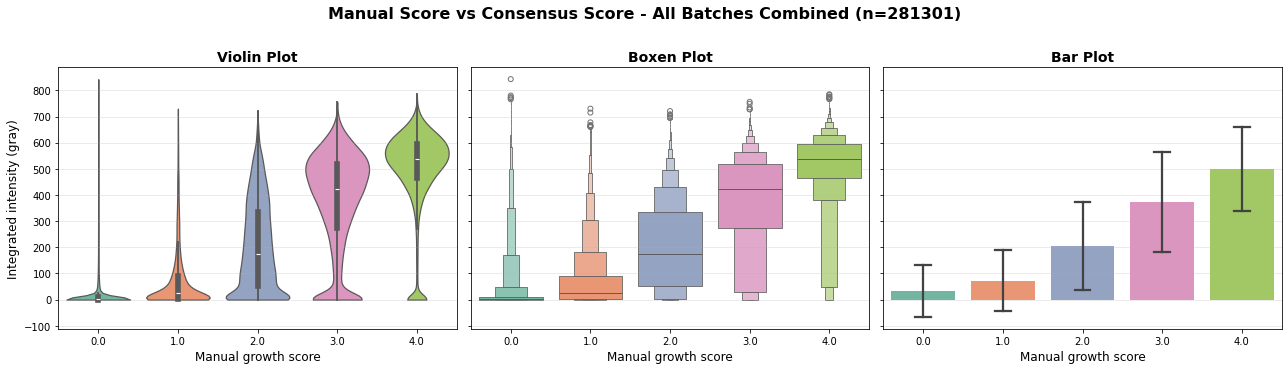

In [499]:
import os
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

scores_pd = init_df.dropna(subset=['manual_score_growth']).copy()

# Create figure with 3 subplots in one row
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# Violin plot
sns.violinplot(
    data=scores_pd,
    x='manual_score_growth',
    y='size_score',
    inner='box',         
    density_norm='width',
    cut=0,
    hue='manual_score_growth',
    palette='Set2',
    legend=False,
    ax=axes[0]
)
axes[0].set_xlabel('Manual growth score', fontsize=12)
axes[0].set_ylabel('Integrated intensity (gray)', fontsize=12)
axes[0].set_title('Violin Plot', fontsize=14, fontweight='bold')
axes[0].grid(alpha=0.3, axis='y')

# Boxen plot
sns.boxenplot(
    data=scores_pd,
    x='manual_score_growth',
    y='size_score',
    hue='manual_score_growth',
    palette='Set2',
    legend=False,
    ax=axes[1]
)
axes[1].set_xlabel('Manual growth score', fontsize=12)
axes[1].set_ylabel('Integrated intensity (gray)', fontsize=12)
axes[1].set_title('Boxen Plot', fontsize=14, fontweight='bold')
axes[1].grid(alpha=0.3, axis='y')

# Bar plot
sns.barplot(
    data=scores_pd,
    x='manual_score_growth',
    y='size_score',
    errorbar='sd',   
    capsize=0.2,
    hue='manual_score_growth',
    palette='Set2',
    legend=False,
    ax=axes[2]
)
axes[2].set_xlabel('Manual growth score', fontsize=12)
axes[2].set_ylabel('Mean integrated intensity (gray)', fontsize=12)
axes[2].set_title('Bar Plot', fontsize=14, fontweight='bold')
axes[2].grid(alpha=0.3, axis='y')

# --- Modification: Set y-ticks every 100 for all axes ---
for ax in axes:
    ax.yaxis.set_major_locator(ticker.MultipleLocator(100))

plt.suptitle(f'Manual Score vs Consensus Score - All Batches Combined (n={len(scores_pd)})', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [500]:
# Calculate percentile-based ranges from actual data
manual_ranges = {}
manual_centers = {}

for manual_score in [0, 1, 2, 3, 4]:
    data = init_df[init_df['manual_score_growth'] == manual_score]['size_score'].dropna()
    if len(data) > 0:
        lower = np.percentile(data, 25)   # 5th percentile as lower bound
        if manual_score == 4:
            upper = 750  # Fixed upper bound for score 4
        else:
            upper = np.percentile(data, 75)  # 95th percentile as upper bound (big box limit)
        center = np.median(data)
        
        manual_ranges[manual_score] = (lower, upper)
        manual_centers[manual_score] = center

print("Data-driven ranges:")
for score in [0, 1, 2, 3, 4]:
    if score in manual_ranges:
        print(f"  Manual {score}: {manual_ranges[score][0]:.1f} - {manual_ranges[score][1]:.1f}, center: {manual_centers[score]:.1f}")
        

Data-driven ranges:
  Manual 0: 0.0 - 10.3, center: 0.6
  Manual 1: 1.6 - 89.0, center: 23.6
  Manual 2: 52.2 - 335.5, center: 176.1
  Manual 3: 272.5 - 517.0, center: 424.2
  Manual 4: 465.4 - 750.0, center: 538.6


In [501]:
orig_df[(orig_df['db_orf_id'] == 52920.0) &
        (orig_df['db_mut_id'] == 2677) &
        (orig_df['ad_orf_id'] == 439.0)
        ][['ad_orf_id', 'db_mut_id','condition_name', 'manual_score_growth', 'per_well_integrated_intensity_gray']]

,ad_orf_id,db_mut_id,condition_name,manual_score_growth,per_well_integrated_intensity_gray
206817,439.0,2677.0,LW,3.0,0.000000
206818,439.0,2677.0,LW,3.0,465.901978
206865,439.0,2677.0,LW,NaN,NaN
206866,439.0,2677.0,LW,3.0,0.000000
217185,439.0,2677.0,LWA,4.0,542.657538
217186,439.0,2677.0,LWA,4.0,0.000000
217233,439.0,2677.0,LWA,0.0,496.962104
217234,439.0,2677.0,LWA,4.0,546.241849
227553,439.0,2677.0,LWH1,3.0,537.938584
227554,439.0,2677.0,LWH1,3.0,560.687604


In [502]:
orig_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,contamination,outlier_score,outlier_size_score,outlier_flag,size_score_raw,size_score
0,VUSAPWT1B1r01_001,A01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,NaN,NaN,...,490.572572,4.0,963,1,False,False,False,NaN,472421.386937,438.645670
1,VUSAPWT1B1r01_001,A02,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,NaN,NaN,...,521.929437,4.0,1032,1,False,False,False,NaN,538631.178658,500.121800
2,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,455.656230,4.0,899,1,False,False,False,False,409634.951014,380.348144
3,VUSAPWT1B1r01_001,A04,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,544.304600,4.0,1050,1,False,False,False,False,571519.830157,530.659081
4,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,505.925513,4.0,970,1,False,False,False,False,490747.747580,455.661790
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
306426,VUSAPWT1B1r06_036,P20,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,435.596088,2.0,962,2,False,False,False,True,419043.436190,389.083970
306427,VUSAPWT1B1r06_036,P21,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,NaN,2.0,1642,2,False,True,True,True,NaN,NaN
306428,VUSAPWT1B1r06_036,P22,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,NaN,2.0,1637,3,False,True,True,True,NaN,NaN
306429,VUSAPWT1B1r06_036,P23,VUSAPWT1B1r06_031_032_033_034_035_036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,12,1,True,False,False,NaN,NaN,NaN


In [503]:
init_df[(init_df['db_orf_id'] == 52920.0) &
        (init_df['db_mut_id'] == 2677) &
        (init_df['ad_orf_id'] == 439.0)
        ][['ad_orf_id', 'db_mut_id','condition_name', 'manual_score_growth', 'per_well_integrated_intensity_gray', 'size_score', 'outlier_flag']]

,ad_orf_id,db_mut_id,condition_name,manual_score_growth,per_well_integrated_intensity_gray,size_score,outlier_flag
206817,439.0,2677.0,LW,3.0,0.000000,0.000000,False
206818,439.0,2677.0,LW,3.0,465.901978,395.389423,False
206865,439.0,2677.0,LW,NaN,NaN,NaN,False
206866,439.0,2677.0,LW,3.0,0.000000,0.000000,False
217185,439.0,2677.0,LWA,4.0,542.657538,542.153677,False
217186,439.0,2677.0,LWA,4.0,0.000000,0.000000,False
217233,439.0,2677.0,LWA,0.0,496.962104,484.042013,False
217234,439.0,2677.0,LWA,4.0,546.241849,565.007818,False
227553,439.0,2677.0,LWH1,3.0,537.938584,523.953180,False
227554,439.0,2677.0,LWH1,3.0,560.687604,549.234376,False


## Consensus

In [504]:
def consensus_score_calculation_old(df, tracking_dict=tracking_dict, use_median=False):
    """
    Calculate consensus scores from replicates with outlier correction.
    
    Parameters:
    -----------
    df : pd.DataFrame
        Input dataframe with replicate measurements
    tracking_dict : dict
        Dictionary to track processing steps
    use_median : bool
        If True, use median instead of mean for consensus scores (default: False)
    
    Returns:
    --------
    tuple : (df, tracking_dict)
    """
    
    def correct_scores_by_manual(scores, manual_scores, central_value):
        """Keep scores that align with manual scoring pattern."""
        scores = np.array(scores)
        manual_scores = np.array(manual_scores)
        
        manual_mean = np.mean(manual_scores)
        expect_high = manual_mean > 2
        expect_middle = manual_mean == 2
        
        if expect_high:
            mask = scores >= central_value
        elif expect_middle:
            tolerance = 0.50 * min_growth_score
            mask = (scores >= (min_growth_score - tolerance)) & (scores <= (min_growth_score + tolerance))
        else:
            mask = scores <= central_value
        
        corrected_scores = scores[mask].tolist()
        return corrected_scores

    mads = []
    mads_dict = {}

    # STEP 1: Build dictionary with initial corrections
    for group, group_df in df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
        manual_scores = group_df['manual_score_growth'].dropna().values.tolist()
        scores = group_df['size_score'].dropna().values.tolist()
        median = np.median(scores)
        mean = np.mean(scores)
        mad = np.median(np.abs(scores - median))
        
        # Choose central tendency measure
        central_value = median if use_median else mean
        
        # Handle groups with <4 replicates AND mad == 0
        if len(scores) < 4 and len(scores) > 1 and mad == 0:
            max_diff = np.max(np.abs(np.array(scores)[:, None] - np.array(scores)))
            
            if max_diff > min_growth_score:
                corrected_scores = correct_scores_by_manual(scores, manual_scores, central_value)
                if corrected_scores:
                    corrected_central = np.median(corrected_scores) if use_median else np.mean(corrected_scores)
                else:
                    corrected_central = np.nan
            else:
                corrected_central = central_value
                
            mads_dict[group] = {
                'MAD': mad, 
                'scores': scores,
                'mean': mean,
                'median': median,
                'corrected_mean': corrected_central,  # Name kept for compatibility
                'manual_scores': manual_scores,
                'already_corrected': True
            }
        else:
            # All other groups
            mads.append(mad)
            mads_dict[group] = {
                'MAD': mad, 
                'scores': scores,
                'mean': mean,
                'median': median,
                'corrected_mean': None,
                'manual_scores': manual_scores,
                'already_corrected': False
            }

    # STEP 2: Calculate MAD threshold
    mads_no_nan = [mad for mad in mads if not np.isnan(mad)]
    mad_95 = np.percentile(mads_no_nan, 95) if mads_no_nan else np.inf
    # print(f"95th percentile of MADs: {mad_95}")
    # print(f"Using {'median' if use_median else 'mean'} for consensus scores")
    
    # STEP 3: Apply corrections to high-MAD groups (skip already corrected)
    for group, values in mads_dict.items():
        if values['already_corrected']:
            continue
        
        mad_value = values['MAD']
        scores = values['scores']
        mean = values['mean']
        median = values['median']
        manual_scores = values['manual_scores']
        
        # Choose central tendency measure
        central_value = median if use_median else mean
        
        if mad_value > mad_95:
            corrected_scores = correct_scores_by_manual(scores, manual_scores, central_value)
            if corrected_scores:
                values['corrected_mean'] = np.median(corrected_scores) if use_median else np.mean(corrected_scores)
            else:
                values['corrected_mean'] = np.nan
        else:
            values['corrected_mean'] = central_value

    # STEP 4: Convert to DataFrame
    corrected_df = pd.DataFrame([
        {
            'ad_orf_id': group[0],
            'db_orf_id': group[1],
            'db_mut_id': group[2],
            'condition_name': group[3],
            'retest_batch': group[4],
            'corrected_mean': values['corrected_mean']
        }
        for group, values in mads_dict.items()
        if values['corrected_mean'] is not None and not np.isnan(values['corrected_mean'])
    ])

    # STEP 5: Merge and finalize
    df = df.merge(
        corrected_df,
        on=['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch'],
        how='left',
        suffixes=('', '_corrected')
    )

    df['consensus_score'] = df['corrected_mean'].fillna(np.nan)
    df.drop('corrected_mean', axis=1, inplace=True)
    
    df = df.drop_duplicates(subset=['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']).reset_index(drop=True)
    
    tracking_dict['3. After consensus score calculation'] = pull_numbers(df, verbose=False)
    
    return df, tracking_dict

In [590]:
def consensus_score_calculation(df, tracking_dict=tracking_dict, use_median=True, verbose=False, drop_outliers=False):
    """
    Calculate consensus scores from replicates with outlier correction.
    Prioritizes Outlier Flags -> Small Group Logic -> High MAD Logic.
    
    Args:
        drop_outliers (bool): If True, groups with ANY 'outlier_flag' are skipped entirely (consensus = NaN).
    """
    
    # --- PREP: Calculate percentile-based ranges from actual data ---
    manual_ranges = {}
    manual_centers = {}

    for manual_score in [0, 1, 2, 3, 4]:
        data = df[df['manual_score_growth'] == manual_score]['size_score'].dropna()
        if len(data) > 0:
            lower = np.percentile(data, 25)
            if manual_score == 4:
                upper = 750
            else:
                upper = np.percentile(data, 75)
            center = np.median(data)
            manual_ranges[manual_score] = (lower, upper)
            manual_centers[manual_score] = center

    # --- HELPER: Correction Function ---
    def correct_scores_by_manual(scores, manual_scores, central_value, group_id=None):
        if verbose:
            print(f"\n--- Correction for {group_id} ---")
            print(f"Scores: {scores}, Manual: {manual_scores}")

        scores = np.array(scores)
        manual_scores = np.array(manual_scores)
        manual_mean = np.mean(manual_scores)
        manual_int = int(round(manual_mean))
        
        # Fallback if manual score logic is missing
        if manual_int not in manual_ranges:
            mask = scores >= central_value if manual_mean > 2 else scores <= central_value
            return scores[mask].tolist()

        # Selection Logic
        if manual_mean > 2:
            mask = scores >= central_value
        elif manual_mean == 2:
            # Ensure min_growth_score is available; fallback to 0.1 if global missing
            local_min_growth = min_growth_score if 'min_growth_score' in globals() else 0.1
            tolerance = 0.50 * local_min_growth
            mask = (scores >= (local_min_growth - tolerance)) & (scores <= (local_min_growth + tolerance))
        else:
            mask = scores <= central_value

        selected = scores[mask]
        
        # Validation Logic
        if len(selected) > 0:
            lower, upper = manual_ranges[manual_int]
            within_range = (selected >= lower) & (selected <= upper)
            if np.any(within_range):
                return selected[within_range].tolist()
        
        # Imputation Logic (if all fail)
        return [manual_centers[manual_int]]

    mads_for_threshold = []
    results_dict = {}

    # --- MAIN LOOP ---
    for group, group_df in df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
        manual_scores = group_df['manual_score_growth'].dropna().values.tolist()
        scores = group_df['size_score'].dropna().values.tolist()
        
        # Basic Stats
        median = np.median(scores) if scores else np.nan
        mean = np.mean(scores) if scores else np.nan
        mad = np.median(np.abs(scores - median)) if scores else np.nan
        central_value = median if use_median else mean
        
        group_id = f"{group[0]}-{group[1]}-{group[2]}-{group[3]}"
        is_outlier = group_df['outlier_flag'].any() if 'outlier_flag' in group_df.columns else False

        # ---------------------------------------------------------
        # PRIORITY 1: OUTLIER FLAGS
        # ---------------------------------------------------------
        if is_outlier:
            # === DROP OUTLIERS LOGIC ===
            if drop_outliers:
                if verbose: print(f"Dropping Outlier Group: {group_id}")
                # Skipping this iteration means no entry in results_dict.
                # Consequently, consensus_score will be NaN for this group.
                continue
            
            if verbose: print(f"Processing Outlier: {group_id}")
            
            # Case A: No manual scores -> Cannot fix -> NaN
            if not manual_scores:
                corrected_val = np.nan
            # Case B: All scores NaN (nulled by QAQC) -> Impute from Manual Center
            elif not scores:
                m_int = int(round(np.mean(manual_scores)))
                corrected_val = manual_centers.get(m_int, np.nan)
            # Case C: Valid scores exist -> Run Correction Logic
            else:
                c_scores = correct_scores_by_manual(scores, manual_scores, central_value, group_id)
                corrected_val = np.median(c_scores) if use_median and c_scores else np.mean(c_scores) if c_scores else np.nan
            
            results_dict[group] = {'corrected_mean': corrected_val}
            continue # Skip to next group

        # ---------------------------------------------------------
        # PRIORITY 2: SMALL GROUPS (<4 Reps, MAD=0)
        # ---------------------------------------------------------
        # Only enters here if NOT an outlier
        if len(scores) < 4 and len(scores) > 1 and mad == 0:
            max_diff = np.max(np.abs(np.array(scores)[:, None] - np.array(scores)))
            
            local_min_growth = min_growth_score if 'min_growth_score' in globals() else 0.1
            
            if max_diff > local_min_growth:
                if verbose: print(f"Processing Small Group (Diff): {group_id}")
                if manual_scores:
                    c_scores = correct_scores_by_manual(scores, manual_scores, central_value, group_id)
                    corrected_val = np.median(c_scores) if use_median and c_scores else np.mean(c_scores) if c_scores else np.nan
                else:
                    corrected_val = np.nan
            else:
                corrected_val = central_value
            
            results_dict[group] = {'corrected_mean': corrected_val}
            continue # Skip to next group

        # ---------------------------------------------------------
        # PRIORITY 3: STANDARD GROUPS (Calculate MAD for Thresholding)
        # ---------------------------------------------------------
        # If we are here, it's a standard group to be evaluated for High MAD later
        mads_for_threshold.append(mad)
        results_dict[group] = {
            'MAD': mad, 
            'scores': scores, 
            'mean': mean, 
            'median': median, 
            'manual_scores': manual_scores,
            'pending_mad_check': True # Mark for step 2
        }

    # --- POST-LOOP: MAD THRESHOLDING ---
    mads_clean = [m for m in mads_for_threshold if not np.isnan(m)]
    mad_95 = np.percentile(mads_clean, 95) if mads_clean else np.inf
    
    if verbose: print(f"MAD 95th Percentile: {mad_95}")

    # Process pending groups
    for group, data in results_dict.items():
        if not data.get('pending_mad_check'):
            continue # Already handled (Outlier or Small Group)
            
        mad_val = data['MAD']
        scores = data['scores']
        manual_scores = data['manual_scores']
        central_val = data['median'] if use_median else data['mean']
        
        if mad_val > mad_95:
            if verbose: print(f"Processing High MAD ({mad_val:.2f}): {group}")
            c_scores = correct_scores_by_manual(scores, manual_scores, central_val, group)
            if c_scores:
                final_val = np.median(c_scores) if use_median else np.mean(c_scores)
            else:
                final_val = np.nan
        else:
            final_val = central_val
            
        # Update the dict to just hold the result like the others
        results_dict[group] = {'corrected_mean': final_val}

    # --- FINALIZE: Merge Data ---
    corrected_df = pd.DataFrame([
        {
            'ad_orf_id': group[0],
            'db_orf_id': group[1],
            'db_mut_id': group[2],
            'condition_name': group[3],
            'retest_batch': group[4],
            'corrected_mean': values['corrected_mean']
        }
        for group, values in results_dict.items()
        if values.get('corrected_mean') is not None and not np.isnan(values.get('corrected_mean'))
    ])

    if not corrected_df.empty:
        df = df.merge(
            corrected_df,
            on=['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch'],
            how='left',
            suffixes=('', '_corrected')
        )
        df['consensus_score'] = df['corrected_mean'].fillna(np.nan)
        df.drop('corrected_mean', axis=1, inplace=True)
    else:
         df['consensus_score'] = np.nan

    # Deduplicate to one row per group
    df = df.drop_duplicates(subset=['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']).reset_index(drop=True)
    
    # Optional: Hard removal of outlier rows if desired
    # if drop_outliers and 'outlier_flag' in df.columns:
    #     df = df[~df['outlier_flag']].reset_index(drop=True)
    
    tracking_dict['3. After consensus score calculation'] = pull_numbers(df, verbose=False)
    
    # Returning results_dict as well since you highlighted it previously
    return df, tracking_dict, results_dict

In [591]:
cons_df, tracking_dict, mads_dict = consensus_score_calculation(init_df, tracking_dict=tracking_dict, use_median=True, verbose=True, drop_outliers=False)

Processing Outlier: 0.0-115.0-999999.0-LW

--- Correction for 0.0-115.0-999999.0-LW ---
Scores: [510.32276300467487, 445.4148292679308, 498.370289746793], Manual: [3.0, 3.0, 3.0, 3.0]
Processing Outlier: 0.0-138.0-999999.0-LWH10

--- Correction for 0.0-138.0-999999.0-LWH10 ---
Scores: [5.981175066036767, 0.0, 0.0], Manual: [0.0, 0.0, 0.0, 0.0]
Processing Outlier: 0.0-143.0-0.0-LWH1

--- Correction for 0.0-143.0-0.0-LWH1 ---
Scores: [272.27060918254, 0.0], Manual: [0.0, 0.0, 0.0]
Processing Outlier: 0.0-143.0-213583.0-LW

--- Correction for 0.0-143.0-213583.0-LW ---
Scores: [508.64604378521386, 494.63971908344877, 445.2364452721737], Manual: [4.0, 4.0, 4.0, 4.0]
Processing Outlier: 0.0-145.0-0.0-LW

--- Correction for 0.0-145.0-0.0-LW ---
Scores: [195.72157832772618, 493.9689038746758, 425.08723034491777], Manual: [4.0, 4.0, 4.0, 4.0]
Processing Outlier: 0.0-145.0-0.0-LWAH1

--- Correction for 0.0-145.0-0.0-LWAH1 ---
Scores: [554.1700805238307, 0.0, 0.0], Manual: [0.0, 0.0, 0.0, 0.0]
Pr

In [678]:
cons_df.consensus_score.nunique()

55255

In [508]:
mads_dict[(439.0, 52920.0, 2677, 'LWH10', 'VUSAPWT6B1')]

{'corrected_mean': 424.2359655689839}

In [509]:
cons_df[(cons_df['db_orf_id'] == 52920.0) &
        (cons_df['db_mut_id'] == 2677) &
        (cons_df['ad_orf_id'] == 439.0)
        ][['ad_orf_id', 'db_mut_id','condition_name', 'retest_batch', 'manual_score_growth', 'per_well_integrated_intensity_gray', 'size_score', 'outlier_flag', 'consensus_score']]

,ad_orf_id,db_mut_id,condition_name,retest_batch,manual_score_growth,per_well_integrated_intensity_gray,size_score,outlier_flag,consensus_score
48439,439.0,2677.0,LW,VUSAPWT6B1,3.0,0.000000,0.000000,False,395.389423
50809,439.0,2677.0,LWA,VUSAPWT6B1,4.0,542.657538,542.153677,False,513.097845
53179,439.0,2677.0,LWH1,VUSAPWT6B1,3.0,537.938584,523.953180,False,490.071372
55549,439.0,2677.0,LWH10,VUSAPWT6B1,3.0,NaN,NaN,True,424.235966
57919,439.0,2677.0,LWH25,VUSAPWT6B1,2.0,349.287590,246.803952,False,235.819391
60289,439.0,2677.0,LWAH1,VUSAPWT6B1,4.0,557.534662,547.698860,False,515.419159


## Metadata

In [510]:

def metadata_mapping_old(df, meta_output=meta_output, inputs_dir=inputs_dir, map_ad_symbol=True):
    """
    Map AD symbols and merge with metadata for the dataframe.
    
    Parameters:
    -----------
    df : pd.DataFrame or pl.DataFrame
        Input dataframe with ad_orf_id, db_orf_id, db_mut_id columns
    meta_output : str
        Path to metadata output directory
    inputs_dir : str
        Path to inputs directory containing mapping file
        
    Returns:
    --------
    pd.DataFrame or pl.DataFrame
        DataFrame with added ad_symbol and metadata columns (same type as input)
    """
    # Track input type to return the same type
    input_is_polars = isinstance(df, pl.DataFrame)
    
    # Convert to polars for efficient processing
    df_pl = pl.DataFrame(df) if not input_is_polars else df
    
    # Store original dtypes for db_orf_id and db_mut_id
    original_db_orf_dtype = df_pl["db_orf_id"].dtype
    original_db_mut_dtype = df_pl["db_mut_id"].dtype
    
    if map_ad_symbol:
        # Load AD ORF ID to symbol mapping
        mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
        mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
        mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()
        
        # Map AD ORF IDs to symbols
        df_pl = df_pl.with_columns(
            pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
        )
    
    # Cast join keys to string for mapping (always cast to string for consistent joining)
    df_pl = df_pl.with_columns([
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.String),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.String)
    ])
    
    # Load metadata
    metadata_path = f"{meta_output}/VarChAMP_Allele_Collection_1Perc_ClinVar_dbNSFP_pLDDT_RSA_G2P_OMIM_MOI_SpliceAI.tsv"
    metadata = pl.read_csv(
        metadata_path, 
        separator="\t", 
        infer_schema_length=None
    ).rename({
        "orf_id": "db_orf_id",
        "mut_id": "db_mut_id"
    }).with_columns([
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.String),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.String)
    ])
    
    # Merge with metadata
    df_pl = df_pl.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
    
    # Restore original dtypes for db_orf_id and db_mut_id
    df_pl = df_pl.with_columns([
        pl.col("db_orf_id").cast(original_db_orf_dtype),
        pl.col("db_mut_id").cast(original_db_mut_dtype)
    ])
    

    
    # Convert back to pandas if input was pandas
    if input_is_polars:
        return df_pl
    else:
        return df_pl.to_pandas()

In [511]:
def metadata_mapping(df, meta_output=meta_output, inputs_dir=inputs_dir, map_ad_symbol=True):
    """
    Map AD symbols and merge with metadata for the dataframe.
    
    Parameters:
    -----------
    df : pd.DataFrame or pl.DataFrame
        Input dataframe with ad_orf_id, db_orf_id, db_mut_id columns
    meta_output : str
        Path to metadata output directory
    inputs_dir : str
        Path to inputs directory containing mapping file
        
    Returns:
    --------
    pd.DataFrame or pl.DataFrame
        DataFrame with added ad_symbol and metadata columns (same type as input)
    """
    # Track input type to return the same type
    input_is_polars = isinstance(df, pl.DataFrame)
    
    # Convert to polars for efficient processing
    df_pl = pl.DataFrame(df) if not input_is_polars else df
    
    # Store original dtypes for db_orf_id and db_mut_id
    original_db_orf_dtype = df_pl["db_orf_id"].dtype
    original_db_mut_dtype = df_pl["db_mut_id"].dtype
    
    if map_ad_symbol:
        # Load AD ORF ID to symbol mapping
        mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
        mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
        mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()
        
        # Map AD ORF IDs to symbols
        df_pl = df_pl.with_columns(
            pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
        )
    
    # Cast as int then string for joining
    df_pl = df_pl.with_columns([
        pl.col("db_orf_id").cast(pl.Float64),
        pl.col("db_mut_id").cast(pl.Float64)
    ])
    
    # Separate WT and variant rows
    df_wt = df_pl.filter(pl.col("db_mut_id") == 0)
    df_variants = df_pl.filter(pl.col("db_mut_id") != 0)
    
    # Load metadata
    metadata_path = f"{meta_output}/VarChAMP_Allele_Collection_1Perc_ClinVar_dbNSFP_pLDDT_RSA_G2P_OMIM_MOI_SpliceAI.tsv"
    metadata = pl.read_csv(
        metadata_path, 
        separator="\t", 
        infer_schema_length=None
    ).rename({
        "orf_id": "db_orf_id",
        "mut_id": "db_mut_id"
    })
    
    # For variants: full join on both db_orf_id and db_mut_id
    if df_variants.height > 0:
        df_variants = df_variants.with_columns([
            pl.col("db_orf_id").cast(pl.Int64).cast(pl.String),
            pl.col("db_mut_id").cast(pl.Int64).cast(pl.String)
        ])
        
        metadata_variants = metadata.with_columns([
            pl.col("db_orf_id").cast(pl.Int64).cast(pl.String),
            pl.col("db_mut_id").cast(pl.Int64).cast(pl.String)
        ])
        
        df_variants = df_variants.join(metadata_variants, on=["db_orf_id", "db_mut_id"], how="left")
        
        df_variants = df_variants.with_columns([
            pl.col("db_orf_id").cast(original_db_orf_dtype),
            pl.col("db_mut_id").cast(original_db_mut_dtype)
        ])
    
    # For WT: join only on db_orf_id to get symbol and other gene-level info
    if df_wt.height > 0:
        df_wt = df_wt.with_columns(
            pl.col("db_orf_id").cast(pl.Int64).cast(pl.String)
        )
        
        # Get unique gene-level metadata
        metadata_wt = metadata.select([
            "db_orf_id", "symbol"
        ]).unique(subset=["db_orf_id"]).with_columns(
            pl.col("db_orf_id").cast(pl.Int64).cast(pl.String)
        )
        
        df_wt = df_wt.join(metadata_wt, on="db_orf_id", how="left")
        
        df_wt = df_wt.with_columns(
            pl.col("db_orf_id").cast(original_db_orf_dtype)
        )
    
    # Combine WT and variant rows back together
    if df_wt.height > 0 and df_variants.height > 0:
        df_pl = pl.concat([df_wt, df_variants], how="diagonal")
    elif df_variants.height > 0:
        df_pl = df_variants
    else:
        df_pl = df_wt
    
    # Consolidate clinvar_clnsig_clean_pp_strict column
    df_pl = df_pl.with_columns(
        pl.when(
            (pl.col("clinvar_clnsig_clean_pp_strict") == pl.lit("Benign")) | 
            (pl.col("clinvar_clnsig_clean_pp_strict") == pl.lit("Likely benign"))
        ).then(pl.lit("Benign"))
        .when(
            (pl.col("clinvar_clnsig_clean_pp_strict") == pl.lit("Pathogenic")) | 
            (pl.col("clinvar_clnsig_clean_pp_strict") == pl.lit("Likely pathogenic"))
        ).then(pl.lit("Pathogenic"))
        .otherwise(pl.col("clinvar_clnsig_clean_pp_strict"))
        .alias("clinvar_clnsig_clean")
    )
    
    # Only add assay_id and group columns if retest_batch exists
    if "retest_batch" in df_pl.columns:
        df_pl = df_pl.with_columns(
            pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
        )
        
        df_pl = df_pl.with_columns(
            pl.concat_str([
                    pl.col('db_orf_id').cast(pl.String),
                    pl.col('db_mut_id').cast(pl.String),
                    pl.col('retest_batch').cast(pl.String)
            ], separator="_").alias("db_group"),
            pl.concat_str([
                    pl.col('db_orf_id').cast(pl.String),
                    pl.col('db_mut_id').cast(pl.String),
                    pl.col('condition_name').cast(pl.String),
                    pl.col('retest_batch').cast(pl.String)
            ], separator="_").alias("db_condition_group"),
            pl.concat_str([
                    pl.col('ad_orf_id').cast(pl.String),
                    pl.col('db_orf_id').cast(pl.String),
                    pl.col('db_mut_id').cast(pl.String),
                    pl.col('retest_batch').cast(pl.String)
            ], separator="_").alias("ppi_group"),
            pl.concat_str([
                    pl.col('ad_orf_id').cast(pl.String),
                    pl.col('db_orf_id').cast(pl.String),
                    pl.col('retest_batch').cast(pl.String)
            ], separator="_").alias("edge_group")
        )
    
    # Convert back to pandas if input was pandas
    if input_is_polars:
        return df_pl
    else:
        return df_pl.to_pandas()

In [512]:
meta_df = metadata_mapping(cons_df, meta_output=meta_output, inputs_dir=inputs_dir)

## Splicing

In [513]:
def remove_splicing_variants(df):
    """
    Remove splicing variants and Met1xxx from the dataframe.
    
    Parameters:
    -----------
    df : pd.DataFrame or pl.DataFrame
        Input dataframe containing splicing_variant column
        
    Returns:
    --------
    pd.DataFrame or pl.DataFrame
        Filtered dataframe (same type as input)
    """
    # Track input type to return the same type
    input_is_polars = isinstance(df, pl.DataFrame)
    
    # Convert to polars for filtering
    if input_is_polars:
        df_pl = df
    else:
        df_pl = pl.DataFrame(df)
    
    # Filter out splicing variants
    df_pl = df_pl.filter(
        (pl.col('splicing_variant') == False) | 
        (pl.col('splicing_variant').is_null())
    )
    
    # Filter out Met1xxx variants (e.g., Met1Ala, Met1Val, etc.)
    # Keep rows where aa_change is null OR doesn't match the pattern
    df_pl = df_pl.filter(
        pl.col('aa_change').is_null() | 
        ~pl.col('aa_change').str.contains(r'^Met1[A-Z][a-z]{2}$')
    )
    
    # Convert back to pandas if input was pandas
    if input_is_polars:
        return df_pl
    else:
        return df_pl.to_pandas()

In [514]:
meta_df = remove_splicing_variants(meta_df)
meta_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,db_group,db_condition_group,ppi_group,edge_group
0,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,0.0,NaN,...,None,None,None,NaN,None,None,2651.0_0.0_VUSAPWT1B1,2651.0_0.0_LW_VUSAPWT1B1,0.0_2651.0_0.0_VUSAPWT1B1,0.0_2651.0_VUSAPWT1B1
1,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,0.0,NaN,...,None,None,None,NaN,None,None,7215.0_0.0_VUSAPWT1B1,7215.0_0.0_LW_VUSAPWT1B1,0.0_7215.0_0.0_VUSAPWT1B1,0.0_7215.0_VUSAPWT1B1
2,VUSAPWT1B1r01_001,A09,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,0.0,NaN,...,None,None,None,NaN,None,None,100016069.0_0.0_VUSAPWT1B1,100016069.0_0.0_LW_VUSAPWT1B1,0.0_100016069.0_0.0_VUSAPWT1B1,0.0_100016069.0_VUSAPWT1B1
3,VUSAPWT1B1r01_001,A11,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,15066.0,NaN,...,None,None,None,NaN,None,None,2713.0_0.0_VUSAPWT1B1,2713.0_0.0_LW_VUSAPWT1B1,15066.0_2713.0_0.0_VUSAPWT1B1,15066.0_2713.0_VUSAPWT1B1
4,VUSAPWT1B1r01_001,A13,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1,False,0.0,NaN,...,None,None,None,NaN,None,None,54308.0_0.0_VUSAPWT1B1,54308.0_0.0_LW_VUSAPWT1B1,0.0_54308.0_0.0_VUSAPWT1B1,0.0_54308.0_VUSAPWT1B1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72919,VUSAPWT1B1r06_036,O17,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,53212.0,NaN,...,autosomal dominant,OMIM,Rare genetic cardiac disease; Laminopathy,2.0,"ARRHYTHMOGENIC RIGHT VENTRICULAR DYSPLASIA, FA...",False,54308.0_218853.0_VUSAPWT1B1,54308.0_218853.0_LWAH1_VUSAPWT1B1,53212.0_54308.0_218853.0_VUSAPWT1B1,53212.0_54308.0_VUSAPWT1B1
72920,VUSAPWT1B1r06_036,O19,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,100069191.0,NaN,...,None,None,Rare genetic cardiac disease; Laminopathy,2.0,None,False,54308.0_218854.0_VUSAPWT1B1,54308.0_218854.0_LWAH1_VUSAPWT1B1,100069191.0_54308.0_218854.0_VUSAPWT1B1,100069191.0_54308.0_VUSAPWT1B1
72921,VUSAPWT1B1r06_036,O19,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,100069191.0,NaN,...,None,None,Rare genetic cardiac disease; Laminopathy,2.0,None,False,54308.0_218854.0_VUSAPWT1B1,54308.0_218854.0_LWAH1_VUSAPWT1B1,100069191.0_54308.0_218854.0_VUSAPWT1B1,100069191.0_54308.0_VUSAPWT1B1
72922,VUSAPWT1B1r06_036,O21,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1,False,100069191.0,NaN,...,autosomal dominant,OMIM,Rare genetic cardiac disease; Laminopathy,2.0,"ARRHYTHMOGENIC RIGHT VENTRICULAR DYSPLASIA, FA...",False,54308.0_218855.0_VUSAPWT1B1,54308.0_218855.0_LWAH1_VUSAPWT1B1,100069191.0_54308.0_218855.0_VUSAPWT1B1,100069191.0_54308.0_VUSAPWT1B1


In [541]:
# for yeast pics
meta_df.to_csv(f"{outputs_dir}/2_consensus_before_qaqc.tsv", sep="\t", index=False)

## Seq

In [516]:
def sequencing_filtering(df, tracking_dict=tracking_dict, meta_output=meta_output, inputs_dir=inputs_dir):
    scores = df.copy()

    scores = scores[scores['media_control'] == False]
    
    # Fix data types before converting to polars
    scores['db_orf_id'] = pd.to_numeric(scores['db_orf_id'], errors='coerce')
    scores['db_mut_id'] = pd.to_numeric(scores['db_mut_id'], errors='coerce')
    scores['ad_orf_id'] = pd.to_numeric(scores['ad_orf_id'], errors='coerce')
    scores['ad_mut_id'] = pd.to_numeric(scores['ad_mut_id'], errors='coerce')
    scores['consensus_score'] = pd.to_numeric(scores['consensus_score'], errors='coerce')

    # add IDs for groups used for filtering
    scores = pl.DataFrame(scores)

    ## placed in metadata mapping step
    # scores = scores.with_columns(
    #     pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
    # )

    # scores = scores.with_columns(
    #     pl.concat_str([
    #             pl.col('db_orf_id').cast(pl.String),
    #             pl.col('db_mut_id').cast(pl.String),
    #             pl.col('retest_batch').cast(pl.String)
    #     ], separator="_").alias("db_group"),
    #     pl.concat_str([
    #             pl.col('db_orf_id').cast(pl.String),
    #             pl.col('db_mut_id').cast(pl.String),
    #             pl.col('condition_name').cast(pl.String),
    #             pl.col('retest_batch').cast(pl.String)
    #     ], separator="_").alias("db_condition_group"),
    #     pl.concat_str([
    #             pl.col('ad_orf_id').cast(pl.String),
    #             pl.col('db_orf_id').cast(pl.String),
    #             pl.col('db_mut_id').cast(pl.String),
    #             pl.col('retest_batch').cast(pl.String)
    #     ], separator="_").alias("ppi_group"),
    #     pl.concat_str([
    #             pl.col('ad_orf_id').cast(pl.String),
    #             pl.col('db_orf_id').cast(pl.String),
    #             pl.col('retest_batch').cast(pl.String)
    #     ], separator="_").alias("edge_group")
    # )
        
    # read in sequence confirmation files
    ad_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_ad_interactors.csv").rename({
        "swim_seq_validated": "seq_ad"
    }).select([
        "ad_orf_id", "assay_id", "seq_ad"
    ])

    db_var_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_db_alleles.csv").rename({
        "orf_id": "db_orf_id",
        "mut_id": "db_mut_id",
        "swim_seq_validated": "seq_db"
    }).select(["db_orf_id", "db_mut_id", "seq_db"])

    db_ref_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/wt_disease_nodes_summary.csv").rename({
        "disease_orf_id": "db_orf_id",
        "swim_seq_validated": "seq_db"
    }).select(["db_orf_id", "seq_db"]).with_columns(
        pl.lit(0).cast(pl.Int64).alias("db_mut_id")
    ).select(["db_orf_id", "db_mut_id", "seq_db"])

    db_seq = pl.concat([db_var_seq, db_ref_seq])


    # cast all to same format
    scores = scores.with_columns(
        pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
        pl.col("assay_id").cast(pl.String).alias("assay_id"),
    )

    db_seq = db_seq.with_columns(
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
        pl.col("seq_db").cast(pl.String).alias("seq_db")
    )

    ad_seq = ad_seq.with_columns(
        pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
        pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
        pl.col("assay_id").cast(pl.String).alias("assay_id"),
    )

    scores = scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
    scores = scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")

    final_sequencing_df = pd.read_csv(f"{meta_output}/VarChampSeqConfirmationResult_final_call.tsv", sep="\t").rename({'mut_id': 'db_mut_id', 'orf_id': 'db_orf_id'}, axis=1)


    # Convert final_sequencing_df to polars and ensure matching data types
    final_sequencing_pl = pl.DataFrame(final_sequencing_df).with_columns(
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id")
    ).select(["db_orf_id", "db_mut_id", "db_seq_final"])

    # Join the db_seq_final column onto scores
    scores = scores.join(final_sequencing_pl, on=["db_orf_id", "db_mut_id"], how="left")

    scores_aa_rrs = scores.filter(
        (pl.col("ad_orf_id") == aa_id) | 
        (pl.col("db_mut_id") == rrs_id)
    )

    scores = scores.filter(
        (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1") & 
        (
            (pl.col("db_mut_id") == 0) |  # WT is always good
            (pl.col("db_seq_final") == "Y")  # Use the final Y/N decision from sequence confirmation
        )
    )

    scores = pl.concat([scores, scores_aa_rrs])
    
    tracking_dict['4. After sequencing'] = pull_numbers(scores, verbose=False)


    return scores, tracking_dict

In [517]:
seq_df, tracking_dict = sequencing_filtering(meta_df, tracking_dict=tracking_dict, meta_output=meta_output, inputs_dir=inputs_dir)

In [ ]:
seq_df.filter((pl.col('symbol') == 'LITAF') &
              (pl.col('aa_change') == 'Val144Met') &
              (pl.col('condition_name') == 'LWH1') &
              (pl.col('ad_symbol') == 'RASSF3')
              )

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,contamination,outlier_score,outlier_size_score,outlier_flag,size_score_raw,size_score,consensus_score,ad_symbol,symbol,aa_change,gene_variant,spdi,nt_change,chr_num,nuc_loc,ref_allele,alt_allele,…,g2p_Psi angle (degrees)*,g2p_Region (UniProt),g2p_Regulatory sites,g2p_Repeat (UniProt),g2p_SNP-associated PTMs,g2p_SUMOylation,g2p_Secondary structure (DSSP 3-state)*,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final_right
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,i64,i64,bool,bool,bool,bool,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,str,…,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,f64,str,bool,str,str,str,str,str,str,str
"""VUSAPWT6B1r03_011""","""G19""","""VUSAPWT6B1r03_007_008_009_010_…","""VUSAPWT6B1""","""r15""","""LWH1""","""6""",false,70054,null,52920,2665,"""VUSMutY8Dh006""","""C11""","""CEGSint_Y8A6_1""","""D04""",371.150339,3.0,741,1,false,false,false,false,275022.401558,255.359704,390.784236,"""RASSF3""","""LITAF""","""Val144Met""","""LITAF_Val144Met""","""NC_000016.10:11549693:C:T""","""430G>A""",16.0,1.1549693e7,"""C""","""T""",…,113.9,null,null,null,null,null,"""B (undefined)""","""E (parallel sheets)""",null,null,null,null,null,null,null,null,null,null,null,92.64,0.0,""">90""","""<10""","""601098""","""autosomal dominant""","""OMIM""","""Rare genetic neurological diso…",1.0,"""CHARCOT-MARIE-TOOTH DISEASE, D…",false,"""52920.0_2665.0_VUSAPWT6B1""","""52920.0_2665.0_LWH1_VUSAPWT6B1""","""70054.0_52920.0_2665.0_VUSAPWT…","""70054.0_52920.0_VUSAPWT6B1""","""1""","""1""","""Y"""


## QAQC

In [580]:
def qa_qc_filtering(df, tracking_dict=tracking_dict, min_growth_score=min_growth_score):

    scores = df
    
    # Filter CDR1 as an interactor because it's not defined as a coding gene
    scores = scores.filter(pl.col("db_orf_id") != 851)

    # Ensure consistent data types for join keys
    scores = scores.with_columns([
        pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64),
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64),
    ])

    # Remove all db groups with the same allele if there was an autoactivation mating failure
    aa_db_group_mating_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                                .filter(pl.col("condition_name") == "LW")
                                .filter(pl.col("consensus_score") <= min_growth_score)
                                .select("db_group")
                                .to_series().unique().to_list())
    scores = scores.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))


    # Remove all db-condition groups with the same allele if there was an autoactivation mating failure
    aa_db_group_tech_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                                    .filter(pl.col("consensus_score").is_nan())
                                    .select("db_condition_group")
                                    .to_series().unique().to_list())
    scores = scores.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))


    tracking_dict['5. Autoactivation mating filtering'] = pull_numbers(scores, verbose=False)
    
    # Remove mating failures - condition LW with low/null consensus score
    mating_failures = (scores.filter(
                            (pl.col("condition_name") == "LW") & 
                            ((pl.col("consensus_score") <= min_growth_score) | pl.col("consensus_score").is_null())
                        )
                        .select("ppi_group")
                        .to_series()
                        .unique()
                        .to_list())
    scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures))

    tracking_dict['6. Mating filtering'] = pull_numbers(scores, verbose=False)

    # Calculate aa_score per condition as the mean of the aa scores in that condition
    aa_scores = scores.filter(pl.col("ad_orf_id") == aa_id).select([
        "db_condition_group", "consensus_score"
    ]).group_by("db_condition_group").agg(
        pl.col("consensus_score").mean().alias("aa_score")  # or .first() if you want the first value
    )

    # Add the aa_score to the dataframe, merged on the condition-specific db allele
    scores = scores.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group", how="left")

    # Remove autoactivation by checking empty-AD scores
    scores = scores.filter(
        (pl.col("condition_name") == "LW") |          # keep all LW
        pl.col("aa_score").is_null() |                # or no AA score
        (pl.col("aa_score") <= min_growth_score)       # or AA score acceptable
    )
    
    # Keep only scores that aren't RRS pairs
    scores = scores.filter(pl.col('db_mut_id') != rrs_id)

    scores = scores.with_columns(
        pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
    )


    tracking_dict['7. Autoactivation filtering'] = pull_numbers(scores, verbose=False)
    

    # Remove all WT and variants from an edge if the WT failed to grow substantially in the LWH1 condition
    wt_failures = (scores.filter(pl.col("condition_name") == "LWH1")
                                .filter(pl.col("db_mut_id") == 0)
                                .filter(
                                    (pl.col("consensus_score") <= min_growth_score) | 
                                    pl.col("consensus_score").is_null()
                                )
                                .select('edge_group')
                                .to_series().unique().to_list())
    
    scores = scores.filter(~pl.col("edge_group").is_in(wt_failures))
    
        
    manual_scores = pl.read_csv(f"{outputs_dir}/3_normalized_qaqc_consensus_scores.csv")

    manual_scores = manual_scores.with_columns(
        pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
        pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id"),
        pl.col("consensus_score").alias("consensus_manual_score_growth")
    )

    # join to scores
    scores = scores.join(manual_scores.select([
        "ad_orf_id", "db_orf_id", "db_mut_id", "assay_id", "condition_name", "consensus_manual_score_growth"
    ]), on=["ad_orf_id", "db_orf_id", "db_mut_id", "assay_id", "condition_name"], how="left")

    tracking_dict['8. After WT filtering'] = pull_numbers(scores, verbose=False)


    return scores, tracking_dict

In [519]:
consensus_qaqc_df, tracking_dict = qa_qc_filtering(seq_df, tracking_dict=tracking_dict)

In [520]:
consensus_qaqc_df.write_csv(f"{outputs_dir}/4_final_filtered_consensus_scores.csv")

## Select best media

In [521]:
def select_best_media_old(df, scoring_conditions=scoring_conditions, min_growth_score=min_growth_score, verbose=False, tracking_dict=tracking_dict):

    scores_pd = df.to_pandas()

    # retain only scoring conditions
    scores_pd = scores_pd[scores_pd.condition_name.isin(scoring_conditions)]

    scores_pd = scores_pd[scores_pd.consensus_score == scores_pd.consensus_score]  # remove NaNs

    # First, build WT media dict as fallback
    wt_media_dict = {} 

    for edge, df in scores_pd[scores_pd.db_mut_id == 0].groupby("edge_group"):
        for media in scoring_conditions:
            media_scores = df[df.condition_name == media]
            if not media_scores.empty and media_scores.consensus_score.values[0] >= min_growth_score:
                wt_media_dict[edge] = media

    # Now build benign media dict
    benign_media_dict = {}

    for edge, df in scores_pd[scores_pd.clinvar_clnsig_clean == "Benign"].groupby("edge_group"):
        var_dict = {}
        for ppi, ppi_df in df.groupby("ppi_group"):
            var_dict[ppi] = []
            for media in scoring_conditions:
                media_scores = ppi_df[ppi_df.condition_name == media]
                if not media_scores.empty and media_scores.consensus_score.values[0] >= min_growth_score:
                    var_dict[ppi].append(media)
                    
        if len(var_dict) == 1:
            # only one variant for this edge, take the last media where it grew
            for ppi, media_list in var_dict.items():
                if media_list:
                    benign_media_dict[edge] = media_list[-1]
        elif len(var_dict) > 1:
            # multiple benign variants. Take the last media of the most sensible variant (the one that grew in the least media)
            sorted_variants = sorted(var_dict.items(), key=lambda x: len(x[1]))
            for ppi, media_list in sorted_variants:
                if media_list:
                    benign_media_dict[edge] = media_list[-1]
                    break        

    # Combine benign and WT media dicts with benign taking priority
    combined_media_dict = {}
    for edge in set(list(benign_media_dict.keys()) + list(wt_media_dict.keys())):
        if edge in benign_media_dict:
            combined_media_dict[edge] = benign_media_dict[edge]
            # print(f"Edge {edge}: Using benign methodology -> {benign_media_dict[edge]}")
        elif edge in wt_media_dict:
            combined_media_dict[edge] = wt_media_dict[edge]
            # print(f"Edge {edge}: Fallback to WT methodology -> {wt_media_dict[edge]}")
        # If edge is in neither dict, it will be skipped
    
    if verbose:
        print(f"Total edges with benign variants: {len(benign_media_dict)}")
        print(f"Total edges with WT fallback: {len(wt_media_dict) - len(benign_media_dict)}")
        print(f"Total edges covered: {len(combined_media_dict)}")


                
    # Now filter all scores to only include the best medium per edge
    filtered_scores = []
    for edge, df in scores_pd.groupby("edge_group"):
        if edge in combined_media_dict:
            valid_media = combined_media_dict[edge]
            filtered_df = df[df.condition_name == valid_media]
            filtered_scores.append(filtered_df)
            
    if filtered_scores:
        filtered_scores = pd.concat(filtered_scores, ignore_index=True)
        if verbose:
            print(f"Filtered scores shape: {filtered_scores.shape}")
    
    # filter for edges with at least a variant and a WT
    if verbose:
        print(f"Total unique ppis before filtering: {filtered_scores['ppi_group'].nunique()}")
    valid_edges = filtered_scores.groupby("edge_group").filter(lambda x: (x.db_mut_id == 0).any() and (x.db_mut_id != 0).any())
    if verbose:
        print(f"Valid ppis after filtering: {valid_edges['ppi_group'].nunique()}")
        
    # Drop duplicates cause by different collections added in mapping
    valid_edges = valid_edges.drop_duplicates(subset=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"])
        

    valid_edges_pl = pl.from_pandas(valid_edges)

    # add wt_consensus_score column to compute log2fc

    wt_scores = valid_edges_pl.filter(pl.col("db_mut_id") == 0).select(
            [
                "edge_group", "consensus_score"
            ]
        ).rename({"consensus_score": "wt_consensus_score"})

    valid_edges_pl = valid_edges_pl.join(
        wt_scores,
        on=["edge_group"],
        how="left"
    )

    # Compute log2fc
    valid_edges_pl = valid_edges_pl.with_columns(
        np.log2(((pl.col("consensus_score") + 1) / (pl.col("wt_consensus_score") + 1)).alias("log2fc")
    ))
    
    tracking_dict['9. Best media selection'] = pull_numbers(valid_edges_pl, verbose=False)

    return valid_edges_pl, tracking_dict

In [522]:
def select_best_media(df, scoring_conditions=scoring_conditions, 
                      min_growth_score=min_growth_score, 
                      verbose=False, 
                      tracking_dict=tracking_dict,
                      benign_filter=True,
                      wt_growth_score=200):

    scores_pd = df.to_pandas()

    # retain only scoring conditions
    scores_pd = scores_pd[scores_pd.condition_name.isin(scoring_conditions)]
    scores_pd = scores_pd[scores_pd.consensus_score == scores_pd.consensus_score]  # remove NaNs

    # 1. CREATE RANK MAP (0 = Least Stringent, N = Most Stringent)
    # This allows us to compare stringencies numerically
    condition_rank = {cond: i for i, cond in enumerate(scoring_conditions)}
    
    # Helper to get name back from rank
    rank_to_condition = {i: cond for cond, i in condition_rank.items()}
    
    # ---------------------------------------------------------
    # NEW STEP: Build WT Score Lookup for fast access
    # We need to check WT score for specific (edge, media) pairs quickly
    # ---------------------------------------------------------
    wt_df = scores_pd[scores_pd.db_mut_id == 0]
    # Dict mapping (edge_group, condition_name) -> consensus_score
    wt_score_map = wt_df.set_index(['edge_group', 'condition_name'])['consensus_score'].to_dict()

    # ---------------------------------------------------------
    # 2. WT FALLBACK (Highest Valid Scan)
    # ---------------------------------------------------------
    wt_media_dict = {} 
    for edge, df_edge in wt_df.groupby("edge_group"):
        # Iterate reversed (High -> Low)
        for media in reversed(scoring_conditions):
            media_scores = df_edge[df_edge.condition_name == media]
            if not media_scores.empty and media_scores.consensus_score.values[0] >= wt_growth_score:
                wt_media_dict[edge] = media
                break # Stop at highest working media

    # ---------------------------------------------------------
    # 3. BENIGN VARIANTS (Most Sensible Logic)
    # ---------------------------------------------------------
    benign_media_dict = {}
    
    if benign_filter:
        for edge, df_edge in scores_pd[scores_pd.clinvar_clnsig_clean == "Benign"].groupby("edge_group"):
            variant_max_ranks = []
            
            # Check each Benign variant individually
            for ppi, ppi_df in df_edge.groupby("ppi_group"):
                # Find the highest rank THIS variant grows on
                for media in reversed(scoring_conditions):
                    media_scores = ppi_df[ppi_df.condition_name == media]
                    
                    if not media_scores.empty:
                        benign_score = media_scores.consensus_score.values[0]
                        # Lookup WT score for this same edge/media
                        wt_score = wt_score_map.get((edge, media), 0.0)
                        
                        # CHECK: Benign must grow AND WT must be robust (>= 200)
                        if (benign_score >= min_growth_score) and (wt_score >= wt_growth_score):
                            variant_max_ranks.append(condition_rank[media])
                            break # Found valid max rank for this variant
            
            if variant_max_ranks:
                # "Most Sensible" = The variant that stopped growing earliest (Lowest Max Rank)
                # We take the MIN of the max ranks.
                most_sensible_rank = min(variant_max_ranks)
                benign_media_dict[edge] = rank_to_condition[most_sensible_rank]

    # ---------------------------------------------------------
    # 4. COMBINE (Benign Priority)
    # ---------------------------------------------------------
    combined_media_dict = {}
    all_edges = set(list(benign_media_dict.keys()) + list(wt_media_dict.keys()))
    
    for edge in all_edges:
        if edge in benign_media_dict:
            combined_media_dict[edge] = benign_media_dict[edge]
        elif edge in wt_media_dict:
            combined_media_dict[edge] = wt_media_dict[edge]
    
    if verbose:
        print(f"Total edges with benign variants: {len(benign_media_dict)}")
        print(f"Total edges with WT fallback: {len(wt_media_dict) - len(benign_media_dict)}")
        print(f"Total edges covered: {len(combined_media_dict)}")


    # Now filter all scores to only include the best medium per edge
    filtered_scores = []
    for edge, df in scores_pd.groupby("edge_group"):
        if edge in combined_media_dict:
            valid_media = combined_media_dict[edge]
            filtered_df = df[df.condition_name == valid_media]
            filtered_scores.append(filtered_df)

    if filtered_scores:
        filtered_scores = pd.concat(filtered_scores, ignore_index=True)
        if verbose:
            print(f"Filtered scores shape: {filtered_scores.shape}")
    
    # filter for edges with at least a variant and a WT
    if verbose:
        print(f"Total unique ppis before filtering: {filtered_scores['ppi_group'].nunique()}")
    valid_edges = filtered_scores.groupby("edge_group").filter(lambda x: (x.db_mut_id == 0).any() and (x.db_mut_id != 0).any())
    if verbose:
        print(f"Valid ppis after filtering: {valid_edges['ppi_group'].nunique()}")
        
    # Drop duplicates cause by different collections added in mapping
    valid_edges = valid_edges.drop_duplicates(subset=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"])
        

    valid_edges_pl = pl.from_pandas(valid_edges)

    # add wt_consensus_score column to compute log2fc

    wt_scores = valid_edges_pl.filter(pl.col("db_mut_id") == 0).select(
            [
                "edge_group", "consensus_score"
            ]
        ).rename({"consensus_score": "wt_consensus_score"})

    valid_edges_pl = valid_edges_pl.join(
        wt_scores,
        on=["edge_group"],
        how="left"
    )

    # Compute log2fc
    valid_edges_pl = valid_edges_pl.with_columns(
        np.log2(((pl.col("consensus_score") + 1) / (pl.col("wt_consensus_score") + 1)).alias("log2fc")
    ))
    
    tracking_dict['9. Best media selection'] = pull_numbers(valid_edges_pl, verbose=False)

    return valid_edges_pl, tracking_dict

In [523]:
wt_growth_score = 200

df, tracking_dict = select_best_media(consensus_qaqc_df, verbose=True, tracking_dict=tracking_dict, benign_filter=True, wt_growth_score=wt_growth_score)

Total edges with benign variants: 71
Total edges with WT fallback: 871
Total edges covered: 942
Filtered scores shape: (3005, 1048)
Total unique ppis before filtering: 2872
Valid ppis after filtering: 2233


In [ ]:
df_pd = df.to_pandas()

df_pd[df_pd.ad_symbol == '']

,db_orf_id,db_mut_id,num_edges,clinvar_clnsig_clean,euclid_distance,nan_euclid_distance,mean_signed_difference,mean_log2fc,max_perturbation,std_perturbation,...,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,ppi_hit
0,1668,214082,2,Pathogenic,0.374755,0.374755,0.215843,1.836916,0.369571,0.153728,...,70-90,10-90,602629,autosomal dominant,OMIM,Rare genetic neurological disorder,1,"DYSTONIA 6, TORSION",False,False
1,1668,214086,2,VUS,0.238263,0.238263,-0.056319,-0.190419,0.215104,0.158785,...,<=50,≥90,602629,autosomal dominant,OMIM,Rare genetic neurological disorder,1,"DYSTONIA 6, TORSION",False,False


In [524]:
# old logic results
# Total edges with benign variants: 73
# Total edges with WT fallback: 755
# Total edges covered: 835
# Filtered scores shape: (2705, 1046)
# Total unique ppis before filtering: 2579
# Valid ppis after filtering: 1998

## Plot

In [525]:
def plot_patho_benign(scores=None, metric="normalized_euclid_distance_normalized", num_edge_filter=1, title=None, threshold=None, fixed_threshold=None, log_treshold=False, clinvar_col="clinvar_clnsig_clean"):
    """
    Plot pathogenic vs benign distribution with optional threshold.
    
    Parameters:
    -----------
    scores : pl.DataFrame, optional
        DataFrame with scores and ClinVar annotations
    metric : str
        Column name containing the metric to plot
    num_edge_filter : int
        Minimum number of edges for filtering
    title : str, optional
        Plot title
    threshold : bool or float, optional
        Whether to calculate or use a threshold
    fixed_threshold : float, optional
        Fixed threshold value to use
    log_treshold : bool
        Whether to use log-scale threshold logic
    clinvar_col : str
        Column to use for ClinVar classification ('clinvar_clnsig_clean' or 'clinvar_clnsig_clean_pp_strict')
    """
    
    # Select appropriate palette based on clinvar column
    if clinvar_col == "clinvar_clnsig_clean_pp_strict":
        palette_dict = {
            'Pathogenic': "#CA7682",
            'Likely pathogenic': "#E6B1B8",
            'Benign': "#1D7AAB",
            'Likely benign': "#7DB8D9",
            'Conflicting': "#505050",
            'VUS': "#A0A0A0",
            'Others': "#E0E0E0"
        }
        pathogenic_categories = ['Pathogenic', 'Likely pathogenic']
        benign_categories = ['Benign', 'Likely benign']
    else:
        palette_dict = {
            'Pathogenic': "#CA7682",
            'Benign': "#1D7AAB",
            'Conflicting': "#505050",
            'VUS': "#A0A0A0",
            'Others': "#E0E0E0"
        }
        pathogenic_categories = ['Pathogenic']
        benign_categories = ['Benign']
    
    if scores is None:
        scores = orf_distances  # This will use the current state of orf_distances
    
    # Filter for pathogenic and benign variants
    path_filter = pl.col(clinvar_col).is_in(pathogenic_categories)
    benign_filter = pl.col(clinvar_col).is_in(benign_categories)
    
    print(f"Plotting {metric} distribution for Pathogenic and Benign variants")
    print("Total variants:", scores.shape[0])
    print("Total unique db_orf_id:", scores.select(pl.col("db_orf_id").n_unique()).item())
    print(f"Total Pathogenic variants: {scores.filter(path_filter).shape[0]}")
    print(f"Total Benign variants: {scores.filter(benign_filter).shape[0]}")
    
    # Calculate threshold if requested
    if threshold:
        path_thres = scores.filter(benign_filter)[metric].max() + 0.016
        print('path_thres:', path_thres)
        if log_treshold:
            path_thres = scores.filter(benign_filter)[metric].min() - 0.016
            print('path_thres:', path_thres)
        elif type(threshold) == float or type(threshold) == int:
            path_thres = threshold
            print('path_thres:', path_thres)
    
    if fixed_threshold:
        path_thres = fixed_threshold
        print('fixed_threshold:', path_thres)
    
    # Create plots
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    
    # KDE plot
    sns.kdeplot(
        data=scores.filter(path_filter)[metric].to_numpy(), 
        label='Pathogenic' if clinvar_col == "clinvar_clnsig_clean" else 'Pathogenic/Likely pathogenic',
        color=palette_dict['Pathogenic'], 
        fill=True, 
        ax=axes[0]
    )
    sns.kdeplot(
        data=scores.filter(benign_filter)[metric].to_numpy(), 
        label='Benign' if clinvar_col == "clinvar_clnsig_clean" else 'Benign/Likely benign',
        color=palette_dict['Benign'], 
        fill=True, 
        ax=axes[0]
    )
    
    if threshold or fixed_threshold:
        axes[0].axvline(x=path_thres, color=palette_dict['Pathogenic'], linestyle='--', label='Threshold')
    axes[0].legend()
    
    # Histogram plot
    sns.histplot(
        scores.filter(path_filter)[metric].to_numpy(), 
        label='Pathogenic' if clinvar_col == "clinvar_clnsig_clean" else 'Pathogenic/Likely pathogenic',
        color=palette_dict['Pathogenic'], 
        kde=True, 
        ax=axes[1]
    )
    sns.histplot(
        scores.filter(benign_filter)[metric].to_numpy(), 
        label='Benign' if clinvar_col == "clinvar_clnsig_clean" else 'Benign/Likely benign',
        color=palette_dict['Benign'], 
        kde=True, 
        ax=axes[1]
    )
    
    if threshold or fixed_threshold:
        axes[1].axvline(x=path_thres, color=palette_dict['Pathogenic'], linestyle='--', label='Threshold')
    
    plt.subplots_adjust(hspace=.05)
    if title is not None:
        plt.suptitle(title)
    else:
        plt.suptitle(f"Distribution of {metric} scores")
    plt.show()
    
    # Filter by number of edges if needed
    if num_edge_filter > 1:
        benign_scores = scores.filter(benign_filter).filter(pl.col("num_edges") >= num_edge_filter)
        path_scores = scores.filter(path_filter).filter(pl.col("num_edges") >= num_edge_filter)
        vus_scores = scores.filter(pl.col(clinvar_col) == "VUS").filter(pl.col("num_edges") >= num_edge_filter)
        conf_scores = scores.filter(pl.col(clinvar_col) == "Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
    else:
        benign_scores = scores.filter(benign_filter)
        path_scores = scores.filter(path_filter)
        vus_scores = scores.filter(pl.col(clinvar_col) == "VUS")
        conf_scores = scores.filter(pl.col(clinvar_col) == "Conflicting")
    
    # Print threshold statistics
    if threshold or fixed_threshold:
        if log_treshold:
            print(f"Benign: {benign_scores.filter(pl.col(metric) < path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) < path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
            print(f"Pathogenic: {path_scores.filter(pl.col(metric) < path_thres).shape[0]} ({path_scores.filter(pl.col(metric) < path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
            print(f"VUS: {vus_scores.filter(pl.col(metric) < path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) < path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
            print(f"Conflicting: {conf_scores.filter(pl.col(metric) < path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) < path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")
        else:
            print(f"Benign: {benign_scores.filter(pl.col(metric) >= path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) >= path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
            print(f"Pathogenic: {path_scores.filter(pl.col(metric) >= path_thres).shape[0]} ({path_scores.filter(pl.col(metric) >= path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
            print(f"VUS: {vus_scores.filter(pl.col(metric) >= path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) >= path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
            print(f"Conflicting: {conf_scores.filter(pl.col(metric) >= path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) >= path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")

Plotting log2fc distribution for Pathogenic and Benign variants
Total variants: 2233
Total unique db_orf_id: 75
Total Pathogenic variants: 945
Total Benign variants: 124


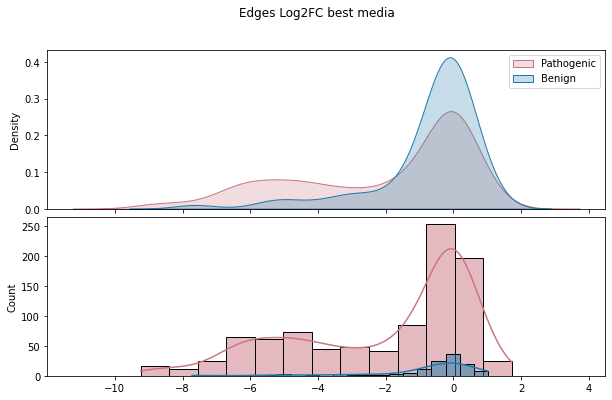

In [526]:
plot_patho_benign(scores=df, metric="log2fc", title="Edges Log2FC best media")

## AUROC AUPRC

In [527]:
def evaluate_classification_performance(scores_df, metric_col, title=None, filter_edges=None, 
                                       verbose=False, show_plots=True, balance_dataset=False,
                                       clinvar_col='clinvar_clnsig_clean'):
    """
    Calculate AUROC and Precision-Recall metrics for benign vs pathogenic classification.
    
    Parameters:
    -----------
    scores_df : polars.DataFrame
        DataFrame containing scores and clinical significance
    metric_col : str
        Name of the column containing the metric to evaluate (e.g., 'log2fc')
    title : str, optional
        Title for the plots
    filter_edges : int, optional
        Minimum number of edges required to include a variant
    balance_dataset : bool, optional
        If True, balance the dataset to have equal benign and pathogenic counts (50/50 priors)
    clinvar_col : str
        Column to use for ClinVar classification ('clinvar_clnsig_clean' or 'clinvar_clnsig_clean_pp_strict')
    
    Returns:
    --------
    dict : Dictionary containing AUROC, AUPRC, and other metrics
    """
    
    # Define pathogenic and benign categories based on clinvar column
    if clinvar_col == "clinvar_clnsig_clean_pp_strict":
        pathogenic_categories = ['Pathogenic', 'Likely pathogenic']
        benign_categories = ['Benign', 'Likely benign']
    else:
        pathogenic_categories = ['Pathogenic']
        benign_categories = ['Benign']
    
    # Convert to pandas for sklearn compatibility
    scores_pd = scores_df.to_pandas()
    
    # Filter by number of edges if specified
    if filter_edges is not None and 'num_edges' in scores_pd.columns:
        scores_pd = scores_pd[scores_pd['num_edges'] >= filter_edges]
    
    # Filter to only benign and pathogenic (including likely variants if using pp_strict)
    all_categories = pathogenic_categories + benign_categories
    filtered = scores_pd[scores_pd[clinvar_col].isin(all_categories)].copy()
    
    # Remove NaN values in metric column
    filtered = filtered[filtered[metric_col].notna()]
    
    if len(filtered) < 10:
        print(f"Warning: Only {len(filtered)} variants available for evaluation")
        return None
    
    # Balance dataset if requested
    if balance_dataset:
        n_pathogenic = filtered[clinvar_col].isin(pathogenic_categories).sum()
        n_benign = filtered[clinvar_col].isin(benign_categories).sum()
        
        if n_pathogenic > n_benign:
            # Oversample benign to match pathogenic
            benign_samples = filtered[filtered[clinvar_col].isin(benign_categories)]
            pathogenic_samples = filtered[filtered[clinvar_col].isin(pathogenic_categories)]
            
            # Repeat benign samples to match pathogenic count
            n_repeats = n_pathogenic // n_benign
            n_remainder = n_pathogenic % n_benign
            
            balanced_benign = pd.concat([benign_samples] * n_repeats + 
                                       [benign_samples.sample(n=n_remainder, random_state=42)], 
                                       ignore_index=True)
            filtered = pd.concat([pathogenic_samples, balanced_benign], ignore_index=True)
            
        elif n_benign > n_pathogenic:
            # Oversample pathogenic to match benign
            benign_samples = filtered[filtered[clinvar_col].isin(benign_categories)]
            pathogenic_samples = filtered[filtered[clinvar_col].isin(pathogenic_categories)]
            
            # Repeat pathogenic samples to match benign count
            n_repeats = n_benign // n_pathogenic
            n_remainder = n_benign % n_pathogenic
            
            balanced_pathogenic = pd.concat([pathogenic_samples] * n_repeats + 
                                           [pathogenic_samples.sample(n=n_remainder, random_state=42)], 
                                           ignore_index=True)
            filtered = pd.concat([benign_samples, balanced_pathogenic], ignore_index=True)
        
        if verbose:
            n_path_final = filtered[clinvar_col].isin(pathogenic_categories).sum()
            n_ben_final = filtered[clinvar_col].isin(benign_categories).sum()
            print(f"Dataset balanced: {n_path_final} pathogenic, {n_ben_final} benign")
    
    # Create binary labels (1 = Pathogenic, 0 = Benign)
    y_true = filtered[clinvar_col].isin(pathogenic_categories).astype(int)
    y_scores = filtered[metric_col].values
    
    # For log2fc, more negative = more pathogenic, so we negate for ROC
    # Adjust this based on your metric interpretation
    if metric_col == "log2fc":
        y_scores_roc = -y_scores  # Negative log2fc indicates loss of function (pathogenic)
    else:
        y_scores_roc = y_scores  # Adjust as needed for other metrics
    
    # Calculate ROC curve and AUROC
    fpr, tpr, roc_thresholds = roc_curve(y_true, y_scores_roc)
    roc_auc = auc(fpr, tpr)
    
    # Calculate Precision-Recall curve and AUPRC
    precision, recall, pr_thresholds = precision_recall_curve(y_true, y_scores_roc)
    auprc = average_precision_score(y_true, y_scores_roc)
    
    # Calculate optimal threshold (Youden's index for ROC)
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold_roc = -roc_thresholds[optimal_idx]  # Convert back to original scale
    
    if show_plots:    
        # Create plots
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # ROC Curve
        axes[0].plot(fpr, tpr, color='royalblue', lw=2, 
                    label=f'ROC curve (AUC = {roc_auc:.3f})')
        axes[0].plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--', label='Random')
        axes[0].set_xlim([0.0, 1.0])
        axes[0].set_ylim([0.0, 1.05])
        axes[0].set_xlabel('False Positive Rate')
        axes[0].set_ylabel('True Positive Rate')
        axes[0].set_title('ROC Curve')
        axes[0].legend(loc="lower right")
        axes[0].grid(alpha=0.3)
        
        # Precision-Recall Curve
        axes[1].plot(recall, precision, color='royalblue', lw=2,
                    label=f'PR curve (AP = {auprc:.3f})')
        axes[1].axhline(y=y_true.mean(), color='grey', linestyle='--', lw=2,
                        label=f'Random (prevalence = {y_true.mean():.3f})')
        axes[1].set_xlim([0.0, 1.0])
        # axes[1].set_ylim([0.0, 1.05])
        axes[1].set_xlabel('Recall (Sensitivity)')
        axes[1].set_ylabel('Precision (PPV)')
        axes[1].set_title('Precision-Recall Curve')
        axes[1].legend(loc="lower left")
        axes[1].grid(alpha=0.3)
        
        if title:
            fig.suptitle(title, fontsize=14, y=1.02)
        
        plt.tight_layout()
        plt.show()
    
    # Calculate additional metrics at optimal threshold
    y_pred_optimal = (y_scores_roc >= roc_thresholds[optimal_idx]).astype(int)
    
    tp = np.sum((y_pred_optimal == 1) & (y_true == 1))
    fp = np.sum((y_pred_optimal == 1) & (y_true == 0))
    tn = np.sum((y_pred_optimal == 0) & (y_true == 0))
    fn = np.sum((y_pred_optimal == 0) & (y_true == 1))
    
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    # Print summary
    if verbose:
        print(f"\n{'='*60}")
        print(f"Classification Performance: {title if title else metric_col}")
        print(f"{'='*60}")
        print(f"Dataset: {len(filtered)} variants ({y_true.sum()} pathogenic, {len(y_true) - y_true.sum()} benign)")
        if clinvar_col == "clinvar_clnsig_clean_pp_strict":
            print(f"  (Including Likely pathogenic and Likely benign)")
        print(f"\nArea Under ROC Curve (AUROC): {roc_auc:.4f}")
        print(f"Area Under PR Curve (AUPRC):  {auprc:.4f}")
        print(f"\nOptimal Threshold (Youden): {optimal_threshold_roc:.4f}")
        print(f"\nPerformance at Optimal Threshold:")
        print(f"  Sensitivity (Recall):  {sensitivity:.4f}")
        print(f"  Specificity:           {specificity:.4f}")
        print(f"  Precision (PPV):       {ppv:.4f}")
        print(f"  Negative Pred. Value:  {npv:.4f}")
        print(f"  Accuracy:              {accuracy:.4f}")
        print(f"{'='*60}\n")
    
    # Return metrics dictionary
    return {
        'auroc': roc_auc,
        'auprc': auprc,
        'optimal_threshold': optimal_threshold_roc,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'precision': ppv,
        'npv': npv,
        'accuracy': accuracy,
        'n_variants': len(filtered),
        'n_pathogenic': y_true.sum(),
        'n_benign': len(y_true) - y_true.sum(),
        'fpr': fpr,
        'tpr': tpr,
        'roc_thresholds': roc_thresholds,
        'precision_curve': precision,
        'recall_curve': recall,
        'pr_thresholds': pr_thresholds,
        'clinvar_col': clinvar_col
    }

Dataset balanced: 945 pathogenic, 945 benign


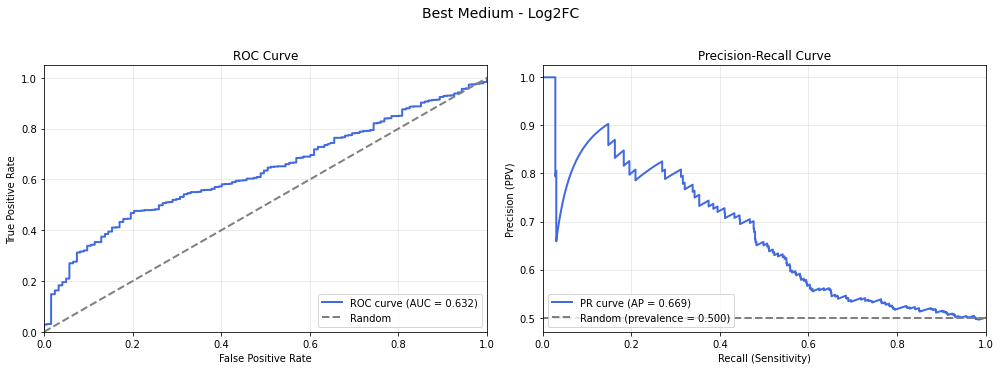


Classification Performance: Best Medium - Log2FC
Dataset: 1890 variants (945 pathogenic, 945 benign)
  (Including Likely pathogenic and Likely benign)

Area Under ROC Curve (AUROC): 0.6321
Area Under PR Curve (AUPRC):  0.6691

Optimal Threshold (Youden): -1.0440

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.4762
  Specificity:           0.7968
  Precision (PPV):       0.7009
  Negative Pred. Value:  0.6034
  Accuracy:              0.6365



In [528]:
perf = evaluate_classification_performance(
    df.filter(pl.col("db_mut_id") != 0),
    metric_col='log2fc',
    title='Best Medium - Log2FC',
    verbose=True,
    balance_dataset=True,
    clinvar_col='clinvar_clnsig_clean_pp_strict'
)

Dataset balanced: 945 pathogenic, 945 benign


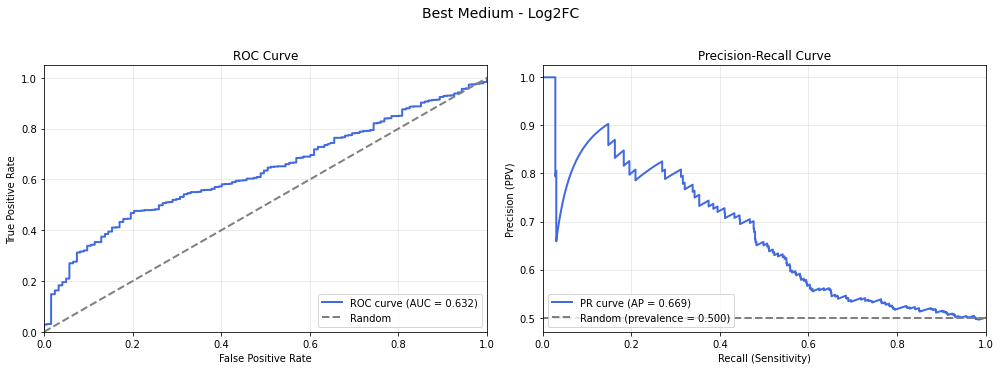


Classification Performance: Best Medium - Log2FC
Dataset: 1890 variants (945 pathogenic, 945 benign)
  (Including Likely pathogenic and Likely benign)

Area Under ROC Curve (AUROC): 0.6321
Area Under PR Curve (AUPRC):  0.6691

Optimal Threshold (Youden): -1.0440

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.4762
  Specificity:           0.7968
  Precision (PPV):       0.7009
  Negative Pred. Value:  0.6034
  Accuracy:              0.6365



In [529]:
perf = evaluate_classification_performance(
    df.filter(pl.col("db_mut_id") != 0),
    metric_col='log2fc',
    title='Best Medium - Log2FC',
    verbose=True,
    balance_dataset=True,
    clinvar_col='clinvar_clnsig_clean_pp_strict'
)

## Orf distances

In [607]:
def compute_orf_distances_old(df):
    
    # normalize consensus score based on max score
    
    consensus_max = df.select(pl.col("consensus_score").max()).item()
    
    df = df.with_columns(
        (pl.col("consensus_score") / consensus_max).alias("consensus_score_normalized"),
        (pl.col("wt_consensus_score") / consensus_max).alias("wt_consensus_score_normalized"),
    )
    
    # Create profiles for each profiled gene
    
    genes = df.select("db_orf_id").to_series().unique().to_list()
    profiles = dict()
    shape_summary = []
    
    for gene in genes:
        gene_scores = df.filter(pl.col("db_orf_id") == gene)
        profile = gene_scores.pivot(
                    values="consensus_score_normalized",
                    index="ad_orf_id",
                    on="db_mut_id"
                )
        
        profiles[gene] = profile

        shape_summary.append({
            "gene": gene,
            "n_interactors": profile.height,
            "n_alleles": profile.width
        })

    shape_summary = pl.DataFrame(shape_summary)
        
    zero_col = "0"

    orf_distances = []


    for orf, profile in profiles.items():
            
        columns = [col for col in profile.columns if col != "ad_orf_id"]

        # "impute" missing values as the mean for that variant
        profile_filled = profile.with_columns([
            pl.when(pl.col(col).is_null())
            .then(pl.col(col).mean())
            .otherwise(pl.col(col))
            .alias(col)
            for col in columns
        ])
        
        # compute distances
        distance_rows = []
        for col in columns:
            if col == zero_col:
                continue
            
            # Euclidean distance
            diff_squared = (profile_filled[col] - profile_filled[zero_col]) ** 2
            distances = np.sqrt(diff_squared.sum())
            

            distance_rows.append({
                "db_orf_id": orf,
                "db_mut_id": int(col),
                "euclid_distance": distances,
                "num_edges": profile.shape[0],
            })


        result_profile = pl.DataFrame(distance_rows)
        orf_distances.append(result_profile)

    # concatentate and normalize wrt dimensionality
    orf_distances = pl.concat(orf_distances, how="vertical_relaxed")
    orf_distances = orf_distances.with_columns(
        (pl.col("euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_euclid_distance"),
        pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
        pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    )

    orf_distances = orf_distances.with_columns(
        (pl.col("normalized_euclid_distance") / pl.col("normalized_euclid_distance").max()).alias("normalized_euclid_distance_normalized"),
    )
    
    orf_distances = metadata_mapping(orf_distances, inputs_dir=inputs_dir, map_ad_symbol=False)
    
    orf_distances = orf_distances.unique(subset=["db_orf_id", "db_mut_id"])
    
    # cast db_orf_id and db_mut_id back to Int64
    orf_distances = orf_distances.with_columns(
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    )
    
    # Drop alleles that were tested multiple times, keep only one (the one with the highest db_mut_id, which should be the most recent)
    orf_distances = orf_distances.sort("db_mut_id", descending=True).unique(subset=["gene_variant"], keep="first")
    
    return orf_distances, profiles

In [632]:
import polars as pl
import numpy as np
from sklearn.metrics.pairwise import nan_euclidean_distances

def compute_orf_distances(df):
    
    # --- 1. PRE-PROCESSING & NORMALIZATION ---
    # Normalize consensus score based on global max score
    consensus_max = df.select(pl.col("consensus_score").max()).item()
    
    df = df.with_columns(
        (pl.col("consensus_score") / consensus_max).alias("consensus_score_normalized"),
        (pl.col("wt_consensus_score") / consensus_max).alias("wt_consensus_score_normalized"),
    )
    
    # Create a lookup for ClinVar status (to ensure it persists through pivoting)
    clinvar_lookup = dict(
        df.select(["db_mut_id", "clinvar_clnsig_clean"])
        .unique(subset=["db_mut_id"], keep="first")
        .iter_rows()
    )
    
    # --- 2. PROFILE GENERATION ---
    genes = df.select("db_orf_id").to_series().unique().to_list()
    profiles = dict()
    profiles_raw = dict() # For Log2FC (needs un-normalized scores)
    
    shape_summary = []
    
    for gene in genes:
        gene_scores = df.filter(pl.col("db_orf_id") == gene)
        
        # Profile A: Normalized (0-1) for Euclidean & Signed Mean
        profile = gene_scores.pivot(
                    values="consensus_score_normalized",
                    index="ad_orf_id",
                    on="db_mut_id"
                )
        profiles[gene] = profile
        
        # Profile B: Raw Scores (for Log2 Fold Change)
        # We need raw counts to calculate meaningful Fold Changes
        profile_raw = gene_scores.pivot(
                    values="consensus_score",
                    index="ad_orf_id",
                    on="db_mut_id"
                )
        profiles_raw[gene] = profile_raw

        shape_summary.append({
            "gene": gene,
            "n_interactors": profile.height,
            "n_alleles": profile.width
        })

    shape_summary = pl.DataFrame(shape_summary)
    
    zero_col = "0" # Represents Wild Type
    orf_distances = []

    # --- 3. DISTANCE CALCULATION LOOP ---
    for orf in profiles.keys():
        profile = profiles[orf]
        profile_raw = profiles_raw[orf]
            
        columns = [col for col in profile.columns if col != "ad_orf_id"]
        
        # Check if Wild Type exists for this gene
        if zero_col not in columns:
            continue

        # A. ORIGINAL IMPUTATION (For your Legacy Metric)
        # "impute" missing values as the mean for that variant
        profile_filled = profile.with_columns([
            pl.when(pl.col(col).is_null())
            .then(pl.col(col).mean())
            .otherwise(pl.col(col))
            .alias(col)
            for col in columns
        ])
        
        # B. PREPARE VECTORS (Using numpy for performance)
        # WT Vectors
        wt_vec = profile.select(zero_col).to_series().to_numpy().reshape(1, -1)
        wt_vec_raw = profile_raw.select(zero_col).to_series().to_numpy().reshape(1, -1)
        
        # Pseudo-count for Log2FC to handle zeros (e.g. log2(0) is undefined)
        epsilon = 1.0 
        
        distance_rows = []
        for col in columns:
            if col == zero_col:
                continue
            
            # --- Metric 1: Original Euclidean (Imputed) ---
            diff_squared = (profile_filled[col] - profile_filled[zero_col]) ** 2
            distances = np.sqrt(diff_squared.sum())
            
            # --- Robust Metrics Prep ---
            var_vec = profile.select(col).to_series().to_numpy().reshape(1, -1)
            var_vec_raw = profile_raw.select(col).to_series().to_numpy().reshape(1, -1)
            
            # Metric 2: NanEuclidean (Magnitude)
            # Scales for missing data automatically
            nan_dist = nan_euclidean_distances(var_vec, wt_vec)[0][0]
            
            # Metric 3: Mean Signed Difference (Directional LOF)
            # (Var - WT). Negative = Loss of Function.
            diff_vec = var_vec - wt_vec
            mean_signed_diff = np.nanmean(diff_vec)
            mean_signed_diff = -mean_signed_diff  # Flip sign: Positive = LOF
            
            
            # Metric 4: Mean Log2 Fold Change (Best Predictor)
            # Log2((Var+eps) / (WT+eps))
            # Captures proportional changes, dampens high-intensity noise.
            log_var = np.log2(var_vec_raw + epsilon)
            log_wt = np.log2(wt_vec_raw + epsilon)
            log2fc_vec = log_var - log_wt
            mean_log2fc = np.nanmean(log2fc_vec)
            mean_log2fc = -mean_log2fc  # Flip sign: Positive = LOF
            
            # Metric 5: Max Perturbation (Chebyshev)
            max_pert = np.nanmax(np.abs(diff_vec))
            
            # Safety checks for NaNs (if variant has NO shared data with WT)
            if np.isnan(mean_signed_diff): mean_signed_diff = 0.0
            if np.isnan(mean_log2fc): mean_log2fc = 0.0
            if np.isnan(max_pert): max_pert = 0.0
            

            # --- Current metrics (for reference) ---
            max_pert = np.nanmax(np.abs(diff_vec))
            mean_signed_diff = np.nanmean(diff_vec)

            # --- NEW EDGETIC METRICS ---

            # 1. VARIANCE/SPREAD METRICS
            std_perturbation = np.nanstd(diff_vec)  # Standard deviation
            median_abs_deviation = np.nanmedian(np.abs(diff_vec - np.nanmedian(diff_vec)))  # MAD

            # 2. EDGE DISRUPTION COUNTS
            # Proportion of edges with significant perturbation (e.g., >50% loss)
            threshold = 0.5 * wt_vec.mean()  # Define your threshold
            edges_disrupted_count = np.sum(np.abs(diff_vec) > threshold)
            edges_disrupted_percent = np.nanmean(np.abs(diff_vec) > threshold) * 100

            # 3. SELECTIVITY METRICS
            # Coefficient of Variation (CV): high CV = selective disruption
            cv = std_perturbation / np.abs(mean_signed_diff) if mean_signed_diff != 0 else 0

            # Gini coefficient: measures inequality (0=all equal, 1=one edge takes all damage)
            abs_diffs = np.abs(diff_vec[~np.isnan(diff_vec)])
            if len(abs_diffs) > 1:
                sorted_diffs = np.sort(abs_diffs)
                n = len(sorted_diffs)
                index = np.arange(1, n + 1)
                gini = (2 * np.sum(index * sorted_diffs)) / (n * np.sum(sorted_diffs)) - (n + 1) / n
            else:
                gini = 0

            # 4. RATIO METRICS
            # Max/Mean ratio: high value = few edges dominate the signal
            max_to_mean_ratio = max_pert / np.abs(mean_signed_diff) if mean_signed_diff != 0 else 0

            # Top 3 edges' contribution
            top3_contribution = np.sum(np.sort(np.abs(diff_vec[~np.isnan(diff_vec)]))[-3:])
            total_perturbation = np.sum(np.abs(diff_vec[~np.isnan(diff_vec)]))
            top3_percent = (top3_contribution / total_perturbation * 100) if total_perturbation > 0 else 0
            
            # Reflip after other metrics
            mean_signed_diff = -mean_signed_diff  # Flip sign: Positive = LOF
            

            distance_rows.append({
                "db_orf_id": orf,
                "db_mut_id": int(col),
                "num_edges": profile.shape[0],
                "clinvar_clnsig_clean": clinvar_lookup.get(int(col), None),
                
                "euclid_distance": distances,             # Original
                "nan_euclid_distance": nan_dist,          # Robust Distance
                "mean_signed_difference": mean_signed_diff, # LOF signal (Linear)
                "mean_log2fc": mean_log2fc,               # LOF signal (Logarithmic)
                "max_perturbation": max_pert,             # Single worst defect
                
                
                # NEW: Edgetic analysis metrics
                "std_perturbation": std_perturbation,
                "cv_perturbation": cv,
                "gini_coefficient": gini,
                "edges_disrupted_pct": edges_disrupted_percent,
                "max_to_mean_ratio": max_to_mean_ratio,
                "top3_edges_contribution_pct": top3_percent,
                "median_abs_deviation": median_abs_deviation
            
            })

        if len(distance_rows) > 0:
            result_profile = pl.DataFrame(distance_rows)
            orf_distances.append(result_profile)

    # --- 4. AGGREGATION & FINAL NORMALIZATION ---
    if not orf_distances:
        return pl.DataFrame(), profiles

    orf_distances = pl.concat(orf_distances, how="vertical_relaxed")
    
    # A. Dimensionality Normalization (Divide by sqrt(N))
    # Applies only to Sum-of-Squares metrics (Euclidean)
    orf_distances = orf_distances.with_columns(
        (pl.col("euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_euclid_distance"),
        (pl.col("nan_euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_nan_euclid_distance"),
        pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
        pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    )

    # B. Global 0-1 Normalization
    # We normalize the POSITIVE distance metrics to 0-1 for easy visualization.
    # We DO NOT normalize Signed/Log metrics to 0-1 because we want to preserve the sign (+/-).
    # Instead, we just divide by max magnitude to keep them in a relatable range [-1, 1].
    
    max_signed = orf_distances.select(pl.col("mean_signed_difference").abs().max()).item()
    max_log = orf_distances.select(pl.col("mean_log2fc").abs().max()).item()
    
    orf_distances = orf_distances.with_columns(
        (pl.col("normalized_euclid_distance") / pl.col("normalized_euclid_distance").max()).alias("normalized_euclid_distance_normalized"),
        (pl.col("normalized_nan_euclid_distance") / pl.col("normalized_nan_euclid_distance").max()).alias("normalized_nan_euclid_distance_normalized"),
        (pl.col("max_perturbation") / pl.col("max_perturbation").max()).alias("max_perturbation_normalized"),
        
        # Scaling signed metrics by absolute max (Preserves Sign!)
        # (pl.col("mean_signed_difference") / max_signed).alias("mean_signed_difference_scaled"),
        # (pl.col("mean_log2fc") / max_log).alias("mean_log2fc_scaled")
    )
    
    # Metadata Mapping (Your custom function)
    orf_distances = metadata_mapping(orf_distances, inputs_dir=inputs_dir, map_ad_symbol=False)
    
    # orf_distances = orf_distances.unique(subset=["db_orf_id", "db_mut_id"])
    
    # Casting IDs back to Int
    orf_distances = orf_distances.with_columns(
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    )
    
    # Deduplication (Keep most recent/highest db_mut_id per variant)
    orf_distances = orf_distances.sort("db_mut_id", descending=True).unique(subset=["gene_variant"], keep="first")
    
    return orf_distances, profiles

In [656]:
import polars as pl
import numpy as np
from sklearn.metrics.pairwise import nan_euclidean_distances

def compute_orf_distances(df, inputs_dir=None):
    
    # --- 1. PRE-PROCESSING ---
    consensus_max = df.select(pl.col("consensus_score").max()).item()
    
    df = df.with_columns(
        (pl.col("consensus_score") / consensus_max).alias("consensus_score_normalized"),
        (pl.col("wt_consensus_score") / consensus_max).alias("wt_consensus_score_normalized"),
    )
    
    clinvar_lookup = dict(
        df.select(["db_mut_id", "clinvar_clnsig_clean"])
        .unique(subset=["db_mut_id"], keep="first")
        .iter_rows()
    )
    
    # --- 2. PROFILE GENERATION ---
    genes = df.select("db_orf_id").to_series().unique().to_list()
    profiles = dict()
    profiles_raw = dict()
    
    for gene in genes:
        gene_scores = df.filter(pl.col("db_orf_id") == gene)
        
        # Ensure unique keys for pivot to prevent errors
        # If duplicates exist, we take the mean
        if gene_scores.select(["ad_orf_id", "db_mut_id"]).is_duplicated().any():
             gene_scores = gene_scores.group_by(["ad_orf_id", "db_mut_id"]).agg(pl.col("consensus_score_normalized").mean(), pl.col("consensus_score").mean())

        profiles[gene] = gene_scores.pivot(
                    values="consensus_score_normalized",
                    index="ad_orf_id",
                    on="db_mut_id"
                )
        
        profiles_raw[gene] = gene_scores.pivot(
                    values="consensus_score",
                    index="ad_orf_id",
                    on="db_mut_id"
                )
    
    zero_col = "0"
    orf_distances = []

    # --- 3. DISTANCE CALCULATION LOOP ---
    for orf in profiles.keys():
        profile = profiles[orf]
        profile_raw = profiles_raw[orf]
        
        columns = [col for col in profile.columns if col != "ad_orf_id"]
        
        if zero_col not in columns:
            continue

        # ==============================================================================
        # BLOCK A: LEGACY CALCULATION (EXACT REPLICATION)
        # ==============================================================================
        # We assume your legacy logic: Fill ALL columns (inc. WT) with their own mean.
        
        profile_filled = profile.with_columns([
            pl.when(pl.col(col).is_null())
            .then(pl.col(col).mean())
            .otherwise(pl.col(col))
            .alias(col)
            for col in columns
        ])
        
        # Pre-calculate Legacy Distances using Polars arithmetic
        # This handles Nulls/NaNs exactly as your old function did.
        legacy_distances_map = {}
        for col in columns:
            if col == zero_col:
                continue
            
            # (Filled_Var - Filled_WT)^2 -> Sum -> Sqrt
            # Polars sum() treats Nulls as 0.0 contribution.
            diff_sq = (profile_filled.get_column(col) - profile_filled.get_column(zero_col)) ** 2
            dist = np.sqrt(diff_sq.sum())
            legacy_distances_map[col] = dist

        # ==============================================================================
        # BLOCK B: ROBUST/NEW METRICS (NUMPY)
        # ==============================================================================
        
        # For Robust metrics, we need NumPy arrays
        row_means_series = profile.select(pl.exclude("ad_orf_id")).mean_horizontal().fill_null(0)
        row_means = row_means_series.to_numpy()

        wt_vec = profile.select(zero_col).to_series().to_numpy()
        wt_vec_raw = profile_raw.select(zero_col).to_series().to_numpy()
        
        # For "WT Impute" metric, we simulate the "filled WT" 
        wt_mask_nan = np.isnan(wt_vec)
        wt_mean = np.nanmean(wt_vec) if not np.all(wt_mask_nan) else 0.0
        wt_vec_filled = wt_vec.copy()
        wt_vec_filled[wt_mask_nan] = wt_mean

        epsilon = 1.0 
        
        distance_rows = []
        for col in columns:
            if col == zero_col:
                continue
            
            # 1. RETRIEVE LEGACY DISTANCE
            dist_legacy = legacy_distances_map.get(col, 0.0)

            # 2. COMPUTE NEW METRICS
            var_vec = profile.select(col).to_series().to_numpy()
            var_vec_raw = profile_raw.select(col).to_series().to_numpy()
            mask_nan = np.isnan(var_vec)
            var_is_empty = np.all(mask_nan)
            
            # Imputation: Interactor Mean
            vec_row_imp = var_vec.copy()
            safe_row_means = np.nan_to_num(row_means, nan=0.0)
            vec_row_imp[mask_nan] = safe_row_means[mask_nan]
            dist_row_imp = np.linalg.norm(vec_row_imp - np.nan_to_num(wt_vec_filled, nan=0.0))
            
            # Imputation: WT Impute
            vec_wt_imp = var_vec.copy()
            wt_fill_vals = np.nan_to_num(wt_vec, nan=0.0)
            vec_wt_imp[mask_nan] = wt_fill_vals[mask_nan]
            dist_wt_imp = np.linalg.norm(vec_wt_imp - np.nan_to_num(wt_vec, nan=0.0))
            
            # Robust RMS
            if var_is_empty or np.all(np.isnan(wt_vec)):
                 d_nan_eucl = 0.0
            else:
                 d_nan_eucl = nan_euclidean_distances(var_vec.reshape(1, -1), wt_vec.reshape(1, -1))[0][0]
            
            # Signed & Log Metrics
            log_var = np.log2(var_vec_raw + epsilon)
            log_wt = np.log2(wt_vec_raw + epsilon)
            mean_log2fc = -np.nanmean(log_var - log_wt)
            mean_signed_diff = -np.nanmean(var_vec - wt_vec)
            
            diff_vec = var_vec - wt_vec
            max_pert = np.nanmax(np.abs(diff_vec))
            
            if np.isnan(mean_signed_diff): mean_signed_diff = 0.0
            if np.isnan(mean_log2fc): mean_log2fc = 0.0
            if np.isnan(max_pert): max_pert = 0.0

            distance_rows.append({
                "db_orf_id": orf,
                "db_mut_id": int(col),
                "num_edges": profile.shape[0],
                "clinvar_clnsig_clean": clinvar_lookup.get(int(col), None),
                
                "euclid_dist_legacy": dist_legacy,       # MATCHES OLD EXACTLY
                "euclid_dist_interactor": dist_row_imp,
                "euclid_dist_wt_imp": dist_wt_imp,
                "nan_euclid_dist_rms": d_nan_eucl,
                
                "mean_signed_difference": mean_signed_diff,
                "mean_log2fc": mean_log2fc,
                "max_perturbation": max_pert,
            })

        if len(distance_rows) > 0:
            result_profile = pl.DataFrame(distance_rows)
            orf_distances.append(result_profile)

    # --- 4. AGGREGATION ---
    if not orf_distances:
        return pl.DataFrame(), profiles

    orf_distances = pl.concat(orf_distances, how="vertical_relaxed")
    
    # Normalize by sqrt(N)
    sqrt_edges = pl.col("num_edges").cast(pl.Float64).sqrt()
    
    orf_distances = orf_distances.with_columns(
        (pl.col("euclid_dist_legacy") / sqrt_edges).alias("norm_dist_legacy"),
        (pl.col("euclid_dist_interactor") / sqrt_edges).alias("norm_dist_interactor"),
        (pl.col("euclid_dist_wt_imp") / sqrt_edges).alias("norm_dist_wt_imp"),
        (pl.col("nan_euclid_dist_rms") / sqrt_edges).alias("norm_dist_rms"),
        
        pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
        pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    )

    # Scale 0-1
    orf_distances = orf_distances.with_columns(
        (pl.col("norm_dist_legacy") / pl.col("norm_dist_legacy").max()).alias("norm_dist_legacy_scaled"),
        (pl.col("norm_dist_rms") / pl.col("norm_dist_rms").max()).alias("norm_dist_rms_scaled"),
        (pl.col("max_perturbation") / pl.col("max_perturbation").max()).alias("max_perturbation_normalized"),
    )
    
    # --- 5. METADATA ---
    
    orf_distances = metadata_mapping(orf_distances, inputs_dir=inputs_dir, map_ad_symbol=False)
    
    orf_distances = orf_distances.with_columns(
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    )
    
    if "gene_variant" in orf_distances.columns:
        orf_distances = orf_distances.sort("db_mut_id", descending=True).unique(subset=["gene_variant"], keep="first")
    else:
        orf_distances = orf_distances.sort("db_mut_id", descending=True).unique(subset=["db_orf_id", "db_mut_id"], keep="first")
    
    return orf_distances, profiles

In [639]:
orf_distances, profiles = compute_orf_distances(df)
orf_distances

db_orf_id,db_mut_id,num_edges,clinvar_clnsig_clean,euclid_dist_legacy,euclid_dist_interactor,euclid_dist_wt_imp,nan_euclid_dist_rms,mean_signed_difference,mean_log2fc,max_perturbation,norm_dist_legacy,norm_dist_interactor,norm_dist_wt_imp,norm_dist_rms,norm_dist_legacy_scaled,norm_dist_rms_scaled,max_perturbation_normalized
i64,i64,i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
4870,215273,4,"""Others""",0.471907,0.471907,0.471907,0.471907,0.22692,1.106919,0.303322,0.235953,0.235953,0.235953,0.235953,0.267839,0.267839,0.344312
70497,3888,1,"""Conflicting""",0.44455,0.44455,0.44455,0.44455,0.44455,3.455352,0.44455,0.44455,0.44455,0.44455,0.44455,0.504625,0.504625,0.504625
7675,202590,3,"""Pathogenic""",0.465626,0.465626,0.465626,0.465626,0.209462,0.630328,0.43831,0.268829,0.268829,0.268829,0.268829,0.305158,0.305158,0.497541
2920,214409,5,"""Conflicting""",0.782468,0.782468,0.782468,0.782468,0.210813,2.11788,0.699522,0.34993,0.34993,0.34993,0.34993,0.397219,0.397219,0.794052
2803,200927,1,"""Pathogenic""",0.570561,0.570561,0.570561,0.570561,0.570561,1.647045,0.570561,0.570561,0.570561,0.570561,0.570561,0.647664,0.647664,0.647664
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
54308,3069,1,"""Conflicting""",0.581529,0.581529,0.581529,0.581529,0.581529,8.580849,0.581529,0.581529,0.581529,0.581529,0.581529,0.660114,0.660114,0.660114
5066,201831,15,"""Pathogenic""",1.149933,1.146936,1.140241,1.274828,0.214981,1.532482,0.566394,0.296912,0.296137,0.294409,0.329159,0.337035,0.37364,0.642934
8151,202844,2,"""VUS""",0.237843,0.237843,0.237843,0.237843,0.140487,0.306861,0.232943,0.16818,0.16818,0.16818,0.16818,0.190907,0.190907,0.264421


In [535]:
orf_distances.write_csv(f"{outputs_dir}/orf_distances_enhanced_metrics.csv")
df.write_csv(f"{outputs_dir}/all_variant_scores_enhanced_metrics.csv")

In [536]:
from scipy import stats as scipy_stats

data1 = orf_distances.filter(pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", 'Likely pathogenic']))["normalized_euclid_distance_normalized"].to_list()
data2 = orf_distances.filter(pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Benign", "Likely benign"]))["normalized_euclid_distance_normalized"].to_list()

statistic, p_value = scipy_stats.mannwhitneyu(data1, data2, alternative='greater')

print(f"Mann-Whitney U test between Pathogenic and Benign:")
print(f"Statistic: {statistic:.4f}, P-value: {p_value:.4e}")

Mann-Whitney U test between Pathogenic and Benign:
Statistic: 5031.0000, P-value: 3.8926e-03


In [537]:
stop

NameError: name 'stop' is not defined

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 508
Total unique db_orf_id: 75
Total Pathogenic variants: 251
Total Benign variants: 31


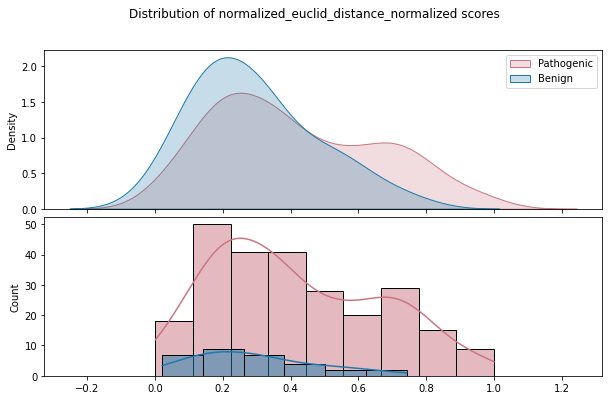

In [538]:
plot_patho_benign(scores=orf_distances)

Plotting mean_signed_difference distribution for Pathogenic and Benign variants
Total variants: 505
Total unique db_orf_id: 75
Total Pathogenic variants: 249
Total Benign variants: 31


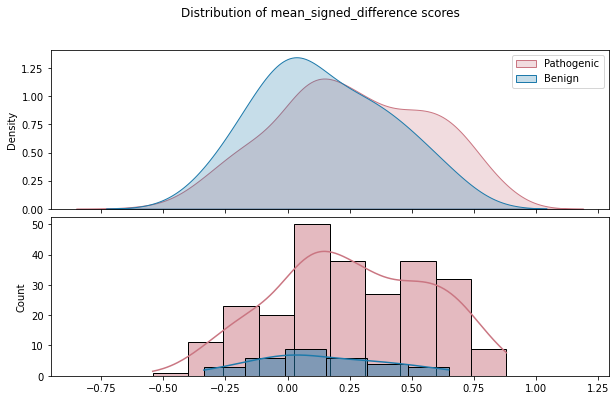

In [ ]:
plot_patho_benign(scores=orf_distances, metric='mean_signed_difference')#, threshold=LLR_threshold)

Plotting mean_log2fc distribution for Pathogenic and Benign variants
Total variants: 494
Total unique db_orf_id: 73
Total Pathogenic variants: 243
Total Benign variants: 31


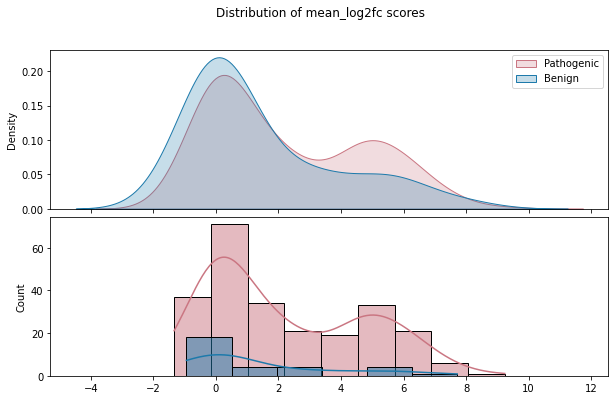

In [ ]:
plot_patho_benign(scores=orf_distances, metric='mean_log2fc')#, threshold=LLR_threshold)

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 494
Total unique db_orf_id: 73
Total Pathogenic variants: 243
Total Benign variants: 31


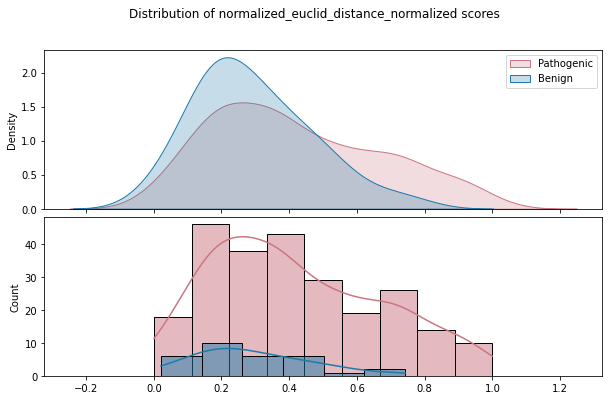

In [ ]:
plot_patho_benign(scores=orf_distances)#, threshold=LLR_threshold)

## Stats function

ValueError: Could not interpret value `normalized_euclid_distance_normalized` for `y`. An entry with this name does not appear in `data`.

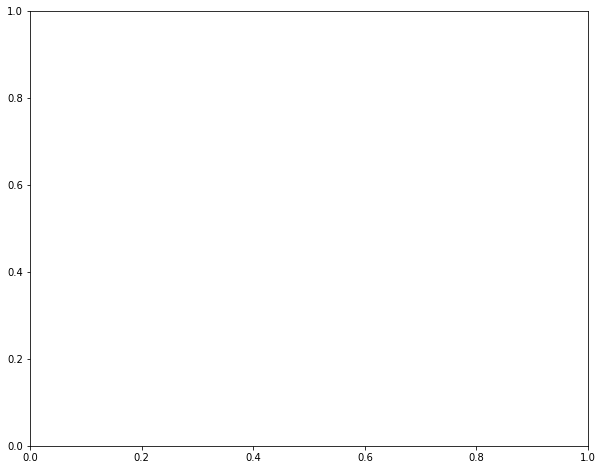

In [659]:
def add_statistical_annotations(ax, data, x_col, y_col, order=None, test='mannwhitneyu', 
                                comparisons='all_significant', y_offset_factor=0.05, 
                                fontsize=10, alpha=0.05, fdr_correction=True, fdr_method='fdr_bh'):
    """
    Add statistical significance annotations to a plot.
    
    Parameters:
    -----------
    ax : matplotlib.axes.Axes
        The axes object to add annotations to
    data : pl.DataFrame or pd.DataFrame
        DataFrame containing the data
    x_col : str
        Column name for x-axis categories
    y_col : str
        Column name for y-axis values
    order : list, optional
        Order of categories on x-axis
    test : str
        Statistical test to use ('mannwhitneyu', 'ttest', 'kruskal')
    comparisons : str or list of tuples
        'all_significant' to test all pairs and show only significant ones
        'adjacent' for adjacent pairs only
        Or list of specific pairs: [('Pathogenic', 'Benign'), ...]
    y_offset_factor : float
        Vertical offset for annotation bars as fraction of y-range
    fontsize : int
        Font size for significance stars
    alpha : float
        Significance level threshold (default: 0.05)
    fdr_correction : bool
        Whether to apply FDR correction for multiple testing (default: True)
    fdr_method : str
        FDR correction method ('fdr_bh' for Benjamini-Hochberg, 'fdr_by' for Benjamini-Yekutieli)
        
    Returns:
    --------
    dict : Dictionary with test results for each comparison
    """
    from scipy import stats as scipy_stats
    from statsmodels.stats.multitest import multipletests
    import pandas as pd
    import numpy as np
    from itertools import combinations
    
    # Convert to pandas if needed
    if hasattr(data, 'to_pandas'):
        df = data.to_pandas()
    else:
        df = data.copy()
    
    # Get order if not specified
    if order is None:
        order = df[x_col].unique().tolist()
    
    # Filter data for categories in order
    df = df[df[x_col].isin(order)].copy()
    
    # Set up comparisons
    if comparisons == 'all_significant':
        # Test all possible pairs
        all_pairs = list(combinations(order, 2))
    elif comparisons == 'adjacent':
        all_pairs = [(order[i], order[i+1]) for i in range(len(order)-1)]
    else:
        all_pairs = comparisons
    
    # Store all results
    all_results = {}
    
    # Perform tests on all pairs
    for cat1, cat2 in all_pairs:
        # Get data for each category
        data1 = df[df[x_col] == cat1][y_col].dropna()
        data2 = df[df[x_col] == cat2][y_col].dropna()
        
        if len(data1) < 2 or len(data2) < 2:
            continue
        
        # Perform statistical test
        if test == 'mannwhitneyu':
            statistic, p_value = scipy_stats.mannwhitneyu(data1, data2, alternative='greater')
            test_name = 'Mann-Whitney U'
        elif test == 'ttest':
            statistic, p_value = scipy_stats.ttest_ind(data1, data2)
            test_name = 't-test'
        elif test == 'kruskal':
            statistic, p_value = scipy_stats.kruskal(data1, data2)
            test_name = 'Kruskal-Wallis'
        
        # Store results
        all_results[f"{cat1}_vs_{cat2}"] = {
            'statistic': statistic,
            'p_value': p_value,
            'test': test_name,
            'n1': len(data1),
            'n2': len(data2),
            'mean1': data1.mean(),
            'mean2': data2.mean(),
            'median1': data1.median(),
            'median2': data2.median(),
            'cat1': cat1,
            'cat2': cat2
        }
    
    # Apply FDR correction if requested
    if fdr_correction and all_results:
        p_values = [v['p_value'] for v in all_results.values()]
        reject, p_adjusted, _, _ = multipletests(p_values, alpha=alpha, method=fdr_method)
        
        # Add adjusted p-values to results
        for (key, result), p_adj, is_reject in zip(all_results.items(), p_adjusted, reject):
            result['p_value_adjusted'] = p_adj
            result['reject_null_fdr'] = is_reject
    
    # Filter for significant results
    if comparisons == 'all_significant':
        if fdr_correction:
            significant_results = {k: v for k, v in all_results.items() 
                                 if v.get('reject_null_fdr', False)}
        else:
            significant_results = {k: v for k, v in all_results.items() 
                                 if v['p_value'] < alpha}
    else:
        significant_results = all_results
    
    if not significant_results:
        correction_text = " (FDR-corrected)" if fdr_correction else ""
        print(f"No significant comparisons found at alpha={alpha}{correction_text}")
        return all_results
    
    # Get y-axis limits for positioning
    y_min, y_max = ax.get_ylim()
    y_range = y_max - y_min
    y_offset = y_range * y_offset_factor
    
    # Calculate max y value for starting position
    # Use the current plot top limit to ensure we clear violin tips
    current_y = y_max + y_offset
    
    # Sort comparisons by adjusted p-value if FDR, else by p-value
    sort_key = 'p_value_adjusted' if fdr_correction else 'p_value'
    sorted_comparisons = sorted(significant_results.items(), 
                               key=lambda x: x[1].get(sort_key, x[1]['p_value']))
    
    # Add annotations for significant results
    for comparison_name, stats in sorted_comparisons:
        cat1 = stats['cat1']
        cat2 = stats['cat2']
        
        # Use adjusted p-value if FDR correction is applied
        p_value = stats.get('p_value_adjusted', stats['p_value']) if fdr_correction else stats['p_value']
        
        # Determine significance stars
        if p_value < 0.001:
            sig_text = '***'
        elif p_value < 0.01:
            sig_text = f'p = {p_value:.3f}\n**'
        elif p_value < 0.05:
            sig_text = f'p = {p_value:.3f}\n*'
        else:
            continue  # Skip non-significant
        
        # Get x positions
        x1 = order.index(cat1)
        x2 = order.index(cat2)
        
        # Draw horizontal line
        ax.plot([x1, x2], [current_y, current_y], 'k-', lw=1.5)
        
        # Draw vertical ticks
        tick_height = y_offset * 0.2
        ax.plot([x1, x1], [current_y, current_y - tick_height], 'k-', lw=1.5)
        ax.plot([x2, x2], [current_y, current_y - tick_height], 'k-', lw=1.5)
        
        # Add significance text
        ax.text((x1 + x2) / 2, current_y + y_offset * 0.1, sig_text,
               ha='center', va='bottom', fontsize=fontsize, fontweight='bold')
        
        # Update y position for next comparison
        current_y += y_offset * 1.5
    
    # Adjust y-axis limit to accommodate annotations
    if sorted_comparisons:
        ax.set_ylim(y_min, current_y + y_offset * 0.5)
        
    return all_results

def print_statistical_summary(results, verbose=True, alpha=0.05, show_all=False, use_fdr=True):
    """
    Print summary of statistical test results.
    
    Parameters:
    -----------
    results : dict
        Dictionary returned by add_statistical_annotations
    verbose : bool
        Whether to print detailed output
    alpha : float
        Significance threshold for highlighting
    show_all : bool
        If True, show all comparisons; if False, show only significant ones
    use_fdr : bool
        Whether to use FDR-adjusted p-values for filtering (if available)
    """
    if not verbose:
        return
    
    # Check if FDR correction was applied
    has_fdr = any('p_value_adjusted' in v for v in results.values())
    
    # Filter results if requested
    if show_all:
        display_results = results
        title = "All Statistical Test Results"
    else:
        if has_fdr and use_fdr:
            display_results = {k: v for k, v in results.items() 
                             if v.get('reject_null_fdr', False)}
            title = f"Significant Statistical Test Results (FDR-corrected, alpha={alpha})"
        else:
            display_results = {k: v for k, v in results.items() 
                             if v['p_value'] < alpha}
            title = f"Significant Statistical Test Results (p < {alpha})"
    
    if not display_results:
        fdr_text = " (FDR-corrected)" if (has_fdr and use_fdr) else ""
        print(f"\nNo {'significant ' if not show_all else ''}results to display{fdr_text}")
        return
    
    print(f"\n{'='*80}")
    print(title)
    print(f"{'='*80}")
    print(f"Total comparisons: {len(results)}")
    
    if has_fdr:
        print(f"Significant comparisons (FDR): {sum(1 for v in results.values() if v.get('reject_null_fdr', False))}")
    print(f"Significant comparisons (unadjusted): {sum(1 for v in results.values() if v['p_value'] < alpha)}")
    print(f"{'='*80}")
    
    # Sort by adjusted p-value if available, else by p-value
    sort_key = 'p_value_adjusted' if (has_fdr and use_fdr) else 'p_value'
    sorted_results = sorted(display_results.items(), 
                           key=lambda x: x[1].get(sort_key, x[1]['p_value']))
    
    for comparison, stats in sorted_results:
        cat1, cat2 = comparison.replace('_vs_', ' vs ').split(' vs ')
        print(f"\n{cat1} vs {cat2}:")
        print(f"  Test: {stats['test']}")
        print(f"  Statistic: {stats['statistic']:.4f}")
        print(f"  P-value: {stats['p_value']:.4e}")
        
        if has_fdr:
            print(f"  P-value (FDR-adjusted): {stats['p_value_adjusted']:.4e}")
            print(f"  Reject null (FDR): {stats['reject_null_fdr']}")
        
        print(f"  N1: {stats['n1']}, N2: {stats['n2']}")
        print(f"  Mean1: {stats['mean1']:.4f}, Mean2: {stats['mean2']:.4f}")
        print(f"  Median1: {stats['median1']:.4f}, Median2: {stats['median2']:.4f}")
        print(f"  Mean difference: {stats['mean1'] - stats['mean2']:.4f}")
        
        # Use adjusted p-value for significance markers if FDR is applied
        p_val = stats.get('p_value_adjusted', stats['p_value']) if (has_fdr and use_fdr) else stats['p_value']
        
        if p_val < 0.001:
            sig = "*** (highly significant)"
        elif p_val < 0.01:
            sig = "** (very significant)"
        elif p_val < 0.05:
            sig = "* (significant)"
        else:
            sig = "ns (not significant)"
        print(f"  Significance: {sig}")
    
    print(f"{'='*80}\n")
import matplotlib.pyplot as plt
import seaborn as sns

def plot_clinvar_distances(
    data,
    palette_map,
    x_col="clinvar_clnsig_clean",
    y_col="normalized_euclid_distance_normalized",
    order=None,
    threshold=0.65,
    threshold_label='LLR Threshold (0.678)'
):
    """
    Plots a boxenplot of distances by ClinVar significance with statistical annotations.

    Parameters:
    - data: DataFrame containing the data.
    - palette_map: Dictionary mapping x_col categories to colors.
    - x_col: Column name for the x-axis (categorical).
    - y_col: Column name for the y-axis (numerical).
    - order: List specifying the order of categories on x-axis.
    - threshold: Y-value for the horizontal reference line.
    
    Returns:
    - ax: The matplotlib axes object.
    - results: The results from the statistical annotation function.
    """
    
    # Set default order if not provided
    if order is None:
        order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

    fig, ax = plt.subplots(figsize=(10, 8))

    # Plotting
    sns.boxenplot(
        data=data,
        x=x_col,
        y=y_col,
        order=order,
        palette=palette_map,
        ax=ax
    )

    # Statistical Annotations
    results = add_statistical_annotations(
        ax=ax,
        data=data,
        x_col=x_col,
        y_col=y_col,
        order=order,
        test='mannwhitneyu',
        comparisons='all_significant',
        alpha=0.05,
        fdr_correction=False,
        y_offset_factor=0.05
    )

    # Aesthetics
    ax.grid(alpha=0.3, axis='y')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)
    ax.set_ylabel("Euclidean Distance normalized", fontsize=15)
    ax.set_xlabel("ClinVar Clinical Significance", fontsize=15)
    
    # Threshold Line
    if threshold is not None:
        ax.axhline(y=threshold, color='red', linestyle='--', label=threshold_label)

    plt.tight_layout()
    plt.show()
    
    return ax, results

# --- Usage Example ---

# You can now call it with just the dataframe and the specific palette dictionary
ax, stats_results = plot_clinvar_distances(
    data=orf_distances, 
    palette_map=palette_dict["clinvar_clnsig_clean"]
)

# Run full pipeline to get final scores

In [635]:
min_growth_score = 200
scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']

def run_full_pipeline(min_growth_score=min_growth_score,
                      scoring_conditions=scoring_conditions,
                      use_median=True, 
                      benign_filter=True,
                      drop_outliers=False,
                      plot_col='normalized_euclid_distance_normalized'):
    """
    Run the complete sqY2H analysis pipeline.
    
    Parameters:
    -----------
    min_growth_score : int
        Minimum growth score threshold for filtering
    scoring_conditions : list
        List of scoring conditions to use for best media selection
        
    Returns:
    --------
    tuple : (df, orf_distances, perf, tracking_dict)
        - df: Polars DataFrame with filtered edge-level scores
        - orf_distances: Polars DataFrame with variant-level distance metrics
        - perf: Dictionary with classification performance metrics
        - tracking_dict: Dictionary tracking data at each pipeline step
    """
    # Initialize tracking
    tracking_dict = {}
    
    # Load original dataframe
    df, tracking_dict = load_original_dataframe(
        file_path=original_datafile_path,
        tracking_dict=tracking_dict
    )
    
    # Initial QA/QC
    df, tracking_dict = initial_qaqc(df, tracking_dict=tracking_dict)
    
    # Calculate consensus scores
    df, tracking_dict, dico = consensus_score_calculation(df, tracking_dict=tracking_dict, use_median=use_median, drop_outliers=drop_outliers)
    
    # Map metadata
    df = metadata_mapping(df, meta_output=meta_output, inputs_dir=inputs_dir)
    
    # Remove splicing variants
    df = remove_splicing_variants(df)
    
    
    # Sequencing filtering
    df, tracking_dict = sequencing_filtering(
        df,
        tracking_dict=tracking_dict,
        meta_output=meta_output,
        inputs_dir=inputs_dir
    )
    
    # QA/QC filtering
    df, tracking_dict = qa_qc_filtering(
        df,
        tracking_dict=tracking_dict,
        min_growth_score=min_growth_score
    )
    
    # Select best media
    df, tracking_dict = select_best_media(
        df,
        scoring_conditions=scoring_conditions,
        min_growth_score=min_growth_score,
        verbose=False,
        tracking_dict=tracking_dict,
        benign_filter=benign_filter
    )
    
    # Evaluate classification performance
    # perf = evaluate_classification_performance(
    #     df.filter(pl.col("db_mut_id") != 0),
    #     metric_col='log2fc',
    #     title='PPIs - Log2FC',
    #     verbose=True,
    #     balance_dataset=True
    # )
    
    # Compute ORF distances
    orf_distances, profiles = compute_orf_distances(df)
    
    # Plot distribution
    plot_patho_benign(
        scores=orf_distances,
        metric=plot_col,
        title="ORF Distances - Normalized Euclidean Distance"
    )
    
    # Evaluate classification performance
    # perf = evaluate_classification_performance(
    #     orf_distances.filter(pl.col("db_mut_id") != 0),
    #     metric_col='normalized_euclid_distance_normalized',
    #     title='ORF Distances - Normalized Euclidean Distance',
    #     verbose=True,
    #     balance_dataset=True
    # )
    
    ax, stats_results = plot_clinvar_distances(
    data=orf_distances, 
    palette_map=palette_dict["clinvar_clnsig_clean"],
    y_col=plot_col,
    )
    
    return df, orf_distances, perf, tracking_dict

## No LWA

Plotting norm_dist_legacy_scaled distribution for Pathogenic and Benign variants
Total variants: 508
Total unique db_orf_id: 75
Total Pathogenic variants: 251
Total Benign variants: 31


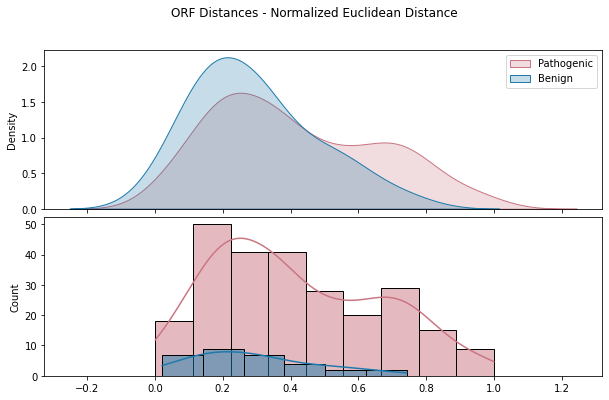

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3519548966.py:311: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3519548966.py:336: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3519548966.py:337: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)


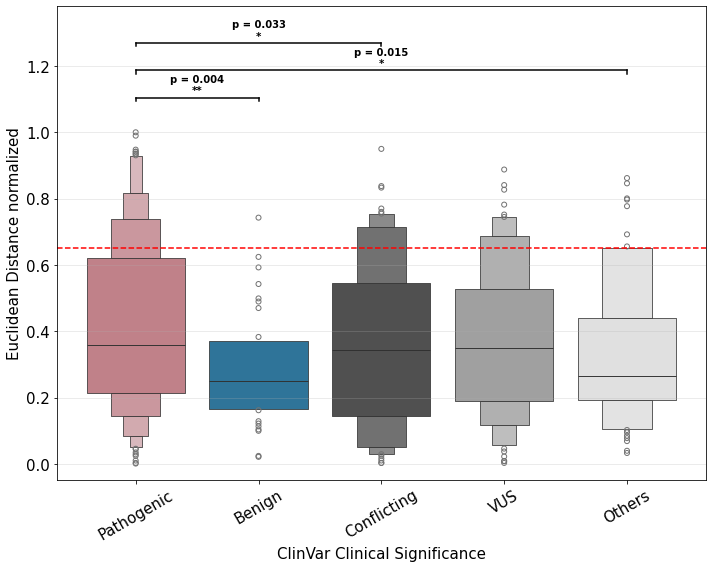

In [661]:
min_growth_score = 200
scoring_conditions = ['LWH1', 'LWH10', 'LWH25']

df, orf_distances, perf, tracking_dict = run_full_pipeline(min_growth_score=min_growth_score,
                                                           scoring_conditions=scoring_conditions,
                                                           use_median=True,
                                                           benign_filter=True,
                                                           plot_col='norm_dist_legacy_scaled',
                                                        #    plot_col='normalized_euclid_distance_normalized'
                                                           )

Dataset balanced: 250 pathogenic, 250 benign


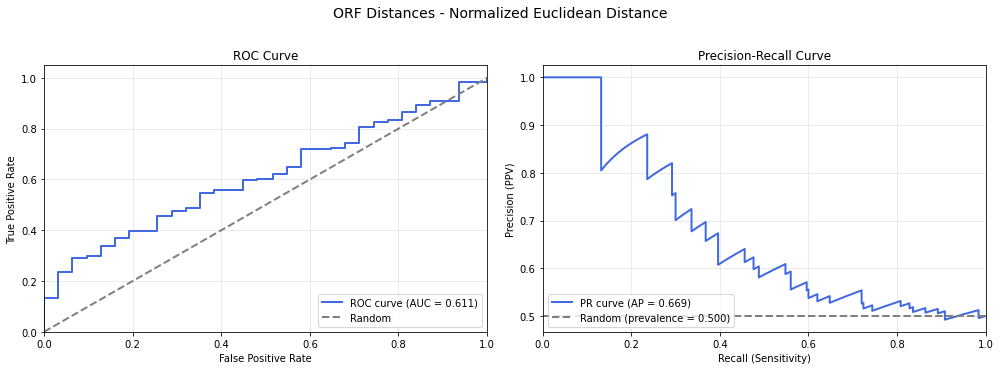


Classification Performance: ORF Distances - Normalized Euclidean Distance
Dataset: 500 variants (250 pathogenic, 250 benign)

Area Under ROC Curve (AUROC): 0.6110
Area Under PR Curve (AUPRC):  0.6690

Optimal Threshold (Youden): -0.5479

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.2920
  Specificity:           0.9360
  Precision (PPV):       0.8202
  Negative Pred. Value:  0.5693
  Accuracy:              0.6140



In [658]:
perf = evaluate_classification_performance(
    orf_distances.filter(pl.col("db_mut_id") != 0),
    metric_col='norm_dist_rms_scaled',
    title='ORF Distances - Normalized Euclidean Distance',
    verbose=True,
    balance_dataset=True
)

In [655]:
df_pd = df.to_pandas()
df_pd[df_pd.log2fc > 1]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final_right,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc
177,VUSAPWT1B2r05_040,C01,VUSAPWT1B2r05_037_038_039_040_041_042,VUSAPWT1B2,r11,LWH25,1,False,100070143,NaN,...,13320.0_204010.0_LWH25_VUSAPWT1B2,100070143.0_13320.0_204010.0_VUSAPWT1B2,100070143.0_13320.0_VUSAPWT1B2,1,1,Y,8.344039,3.0,265.921426,1.029297
214,VUSAPWT2B1r05_010,A17,VUSAPWT2B1r05_007_008_009_010_011_012,VUSAPWT2B1,r17,LWH25,2,False,10064,NaN,...,52920.0_2684.0_LWH25_VUSAPWT2B1,10064.0_52920.0_2684.0_VUSAPWT2B1,10064.0_52920.0_VUSAPWT2B1,1,1,Y,4.347717,2.0,262.652372,1.209841
216,VUSAPWT2B1r05_010,A21,VUSAPWT2B1r05_007_008_009_010_011_012,VUSAPWT2B1,r17,LWH25,2,False,10064,NaN,...,52920.0_2666.0_LWH25_VUSAPWT2B1,10064.0_52920.0_2666.0_VUSAPWT2B1,10064.0_52920.0_VUSAPWT2B1,1,1,Y,6.151786,2.0,262.652372,1.134009
220,VUSAPWT2B1r05_010,C21,VUSAPWT2B1r05_007_008_009_010_011_012,VUSAPWT2B1,r17,LWH25,2,False,10064,NaN,...,52920.0_2677.0_LWH25_VUSAPWT2B1,10064.0_52920.0_2677.0_VUSAPWT2B1,10064.0_52920.0_VUSAPWT2B1,1,1,Y,9.553852,3.0,262.652372,1.345587
263,VUSAPWT1B1r05_040,C05,VUSAPWT1B1r05_037_038_039_040_041_042,VUSAPWT1B1,r11,LWH25,1,False,10556,NaN,...,3535.0_6171.0_LWH25_VUSAPWT1B1,10556.0_3535.0_6171.0_VUSAPWT1B1,10556.0_3535.0_VUSAPWT1B1,1,1,Y,2.597968,3.0,223.788644,1.096241
264,VUSAPWT1B1r05_040,I09,VUSAPWT1B1r05_037_038_039_040_041_042,VUSAPWT1B1,r11,LWH25,1,False,10556,NaN,...,3535.0_6172.0_LWH25_VUSAPWT1B1,10556.0_3535.0_6172.0_VUSAPWT1B1,10556.0_3535.0_VUSAPWT1B1,1,1,Y,4.174257,3.0,223.788644,1.060324
470,VUSAPWT2B1r03_005,C15,VUSAPWT2B1r03_001_002_003_004_005_006,VUSAPWT2B1,r15,LWH1,2,False,12920,NaN,...,7323.0_216369.0_LWH1_VUSAPWT2B1,12920.0_7323.0_216369.0_VUSAPWT2B1,12920.0_7323.0_VUSAPWT2B1,1,1,Y,62.076903,NaN,210.019004,1.090032
722,VUSAPWT6B1r05_001,A19,VUSAPWT6B1r05_001_002_003_004_005_006,VUSAPWT6B1,r17,LWH25,6,False,156,NaN,...,71191.0_205705.0_LWH25_VUSAPWT6B1,156.0_71191.0_205705.0_VUSAPWT6B1,156.0_71191.0_VUSAPWT6B1,1,1,Y,9.139435,3.0,248.597492,1.048826
752,VUSAPWT1B1r05_039,C23,VUSAPWT1B1r05_037_038_039_040_041_042,VUSAPWT1B1,r11,LWH25,1,False,1769,NaN,...,3535.0_6161.0_LWH25_VUSAPWT1B1,1769.0_3535.0_6161.0_VUSAPWT1B1,1769.0_3535.0_VUSAPWT1B1,1,1,Y,5.238282,3.0,261.538673,1.035383
952,VUSAPWT1B2r04_024,C21,VUSAPWT1B2r04_019_020_021_022_023_024,VUSAPWT1B2,r10,LWH10,1,False,2767,NaN,...,2767.0_214357.0_LWH10_VUSAPWT1B2,2767.0_2767.0_214357.0_VUSAPWT1B2,2767.0_2767.0_VUSAPWT1B2,1,1,Y,3.377395,3.0,206.817320,1.163244


Plotting norm_dist_rms_scaled distribution for Pathogenic and Benign variants
Total variants: 507
Total unique db_orf_id: 75
Total Pathogenic variants: 250
Total Benign variants: 31


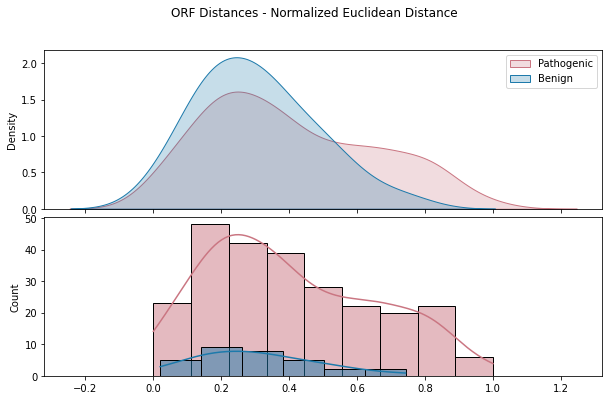

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3519548966.py:311: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3519548966.py:336: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3519548966.py:337: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)


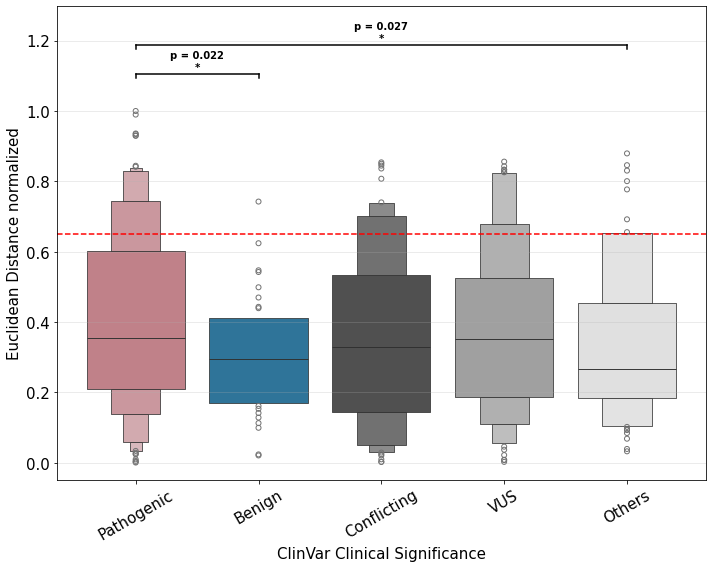

In [660]:
min_growth_score = 200
scoring_conditions = ['LWH1', 'LWH10', 'LWH25']

df, orf_distances, perf, tracking_dict = run_full_pipeline(min_growth_score=min_growth_score,
                                                           scoring_conditions=scoring_conditions,
                                                           use_median=True,
                                                           benign_filter=False,
                                                           drop_outliers=False,
                                                           plot_col='norm_dist_rms_scaled',
                                                           )

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3319417295.py:311: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3319417295.py:336: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3319417295.py:337: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)


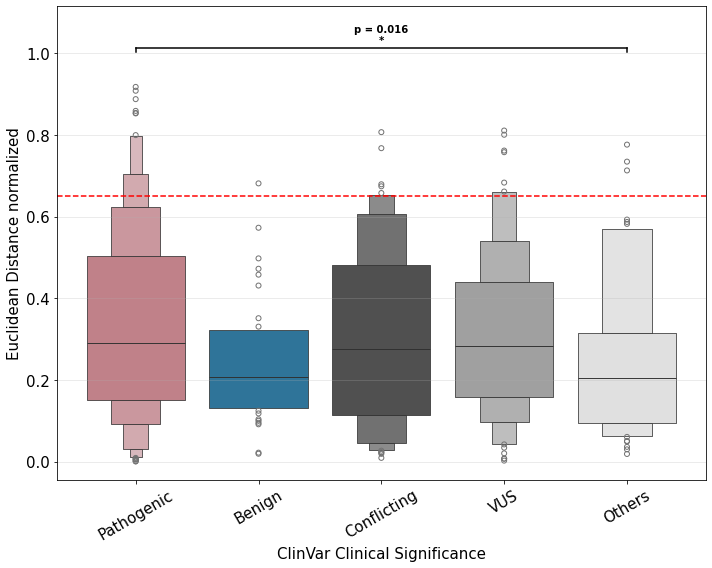

In [647]:
ax, stats_results = plot_clinvar_distances(
data=orf_distances, 
palette_map=palette_dict["clinvar_clnsig_clean"],
y_col="norm_dist_wt_imp"
)

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 445
Total unique db_orf_id: 70
Total Pathogenic variants: 207
Total Benign variants: 30


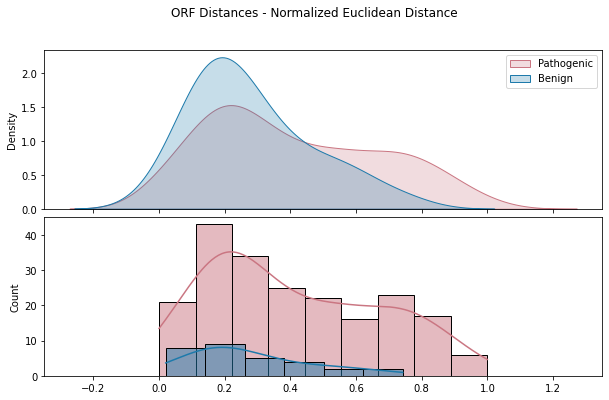

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3319417295.py:311: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3319417295.py:336: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3319417295.py:337: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)


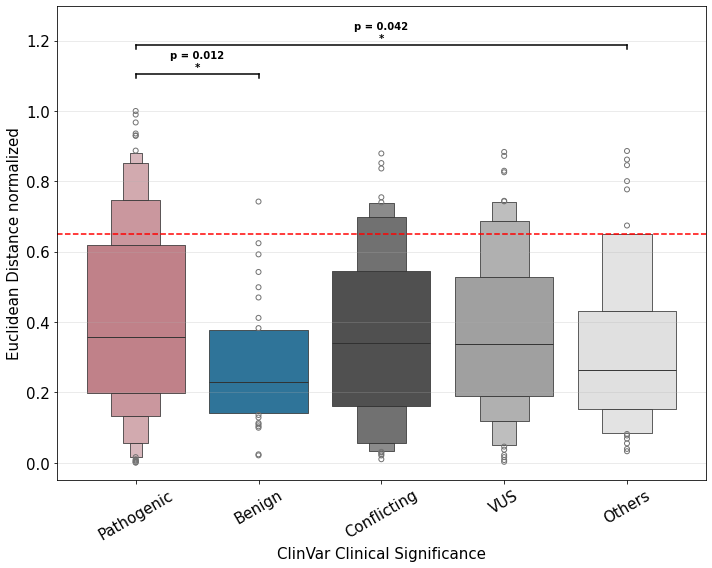

In [592]:
min_growth_score = 200
scoring_conditions = ['LWH1', 'LWH10', 'LWH25']

df, orf_distances, perf, tracking_dict = run_full_pipeline(min_growth_score=min_growth_score,
                                                           scoring_conditions=scoring_conditions,
                                                           use_median=True,
                                                           benign_filter=True,
                                                           drop_outliers=True)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3319417295.py:311: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3319417295.py:336: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3319417295.py:337: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)


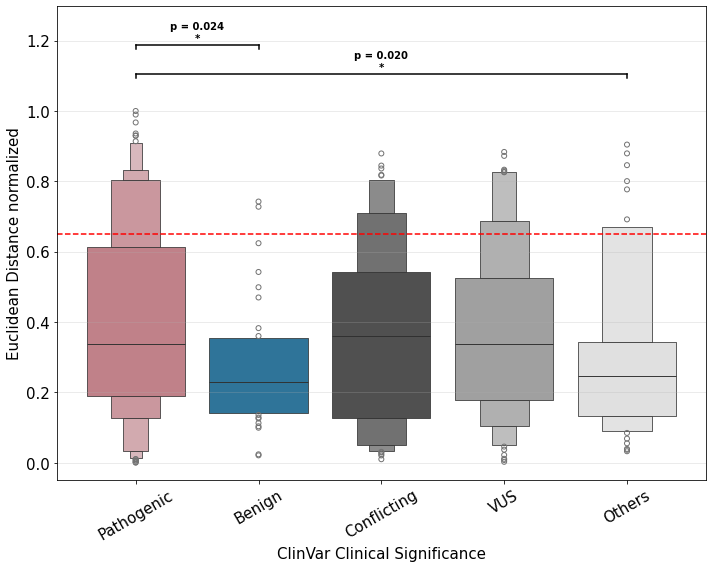

In [595]:
ax, stats_results = plot_clinvar_distances(
data=orf_distances, 
palette_map=palette_dict["clinvar_clnsig_clean"],
y_col="normalized_nan_euclid_distance_normalized"
)

## tables for Leo

In [575]:
df

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,contamination,outlier_score,outlier_size_score,outlier_flag,size_score_raw,size_score,consensus_score,ad_symbol,symbol,aa_change,gene_variant,spdi,nt_change,chr_num,nuc_loc,ref_allele,alt_allele,…,g2p_SNP-associated PTMs,g2p_SUMOylation,g2p_Secondary structure (DSSP 3-state)*,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final_right,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,i64,i64,bool,bool,bool,bool,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,str,…,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,f64,str,bool,str,str,str,str,str,str,str,f64,f64,f64,f64
"""VUSAPWT6B1r05_009""","""K23""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""","""6""",false,100000046,null,7323,0,"""DisWTY8Dh02""","""D09""","""CEGSint_Y8A6_1""","""H03""",0.0,3.0,0,0,false,false,false,false,0.0,0.0,503.182724,"""CLDN5""","""PMP22""",null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""7323.0_0.0_VUSAPWT6B1""","""7323.0_0.0_LWH25_VUSAPWT6B1""","""100000046.0_7323.0_0.0_VUSAPWT…","""100000046.0_7323.0_VUSAPWT6B1""","""1""","""1""",null,8.030579,3.0,503.182724,0.0
"""VUSAPWT6B1r05_010""","""A01""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""","""6""",false,100000046,null,7323,216370,"""VUSMutY8Dh020""","""B07""","""CEGSint_Y8A6_1""","""H03""",616.734667,3.0,1115,1,false,false,false,false,687659.15331,638.495036,626.486022,"""CLDN5""","""PMP22""","""Gly150Cys""","""PMP22_Gly150Cys""","""NC_000017.11:15230952:C:A""","""448G>T""",17.0,1.5230952e7,"""C""","""A""",…,"""dbSNP: rs104894624; Variant ty…",null,"""H (helix)""","""H (α-helix)""",null,null,null,null,null,null,null,null,"""Helical""",null,null,96.78,0.0,""">90""","""<10""",null,null,null,"""Genetic otorhinolaryngologic d…",3.0,null,false,"""7323.0_216370.0_VUSAPWT6B1""","""7323.0_216370.0_LWH25_VUSAPWT6…","""100000046.0_7323.0_216370.0_VU…","""100000046.0_7323.0_VUSAPWT6B1""","""1""","""1""","""Y""",12.196559,3.0,503.182724,0.315637
"""VUSAPWT6B1r05_010""","""C01""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17""","""LWH25""","""6""",false,100000046,null,7323,216369,"""VUSMutY8Dh020""","""A07""","""CEGSint_Y8A6_1""","""H03""",568.916362,3.0,1105,1,false,false,false,false,628652.579634,583.707131,424.235966,"""CLDN5""","""PMP22""","""Asp37Val""","""PMP22_Asp37Val""","""NC_000017.11:15259162:T:A""","""110A>T""",17.0,1.5259162e7,"""T""","""A""",…,null,null,"""C (loop/coil)""","""S (bend)""",null,null,null,null,null,null,"""Extracellular""",null,null,null,null,77.82,3.6809816,"""70-90""","""<10""",null,null,null,"""Genetic otorhinolaryngologic d…",3.0,null,false,"""7323.0_216369.0_VUSAPWT6B1""","""7323.0_216369.0_LWH25_VUSAPWT6…","""100000046.0_7323.0_216369.0_VU…","""100000046.0_7323.0_VUSAPWT6B1""","""1""","""1""","""Y""",22.235584,3.0,503.182724,-0.245683
"""VUSAPWT6B1r05_010""","""E01""","""VUSAPWT6B1r05_007_008_009_010_…","""VUSAPWT6B1""","""r17"""

In [576]:
orf_distances

db_orf_id,db_mut_id,num_edges,clinvar_clnsig_clean,euclid_distance,nan_euclid_distance,mean_signed_difference,mean_log2fc,max_perturbation,std_perturbation,cv_perturbation,gini_coefficient,edges_disrupted_pct,max_to_mean_ratio,top3_edges_contribution_pct,median_abs_deviation,normalized_euclid_distance,normalized_nan_euclid_distance,normalized_euclid_distance_normalized,normalized_nan_euclid_distance_normalized,max_perturbation_normalized,symbol,aa_change,gene_variant,spdi,nt_change,chr_num,nuc_loc,ref_allele,alt_allele,Chrom,ensembl_gene_id,ccsb_mutation_id,ccsb_allele_id,ensembl_protein_id,collection,entry_plate_orig,…,g2p_O-GalNAc,g2p_O-GlcNAc,g2p_Peptide (UniProt),g2p_Phi angle (degrees)*,g2p_Phosphorylation,g2p_Pocket number (fpocket)*,g2p_Propeptide (UniProt),g2p_Psi angle (degrees)*,g2p_Region (UniProt),g2p_Regulatory sites,g2p_Repeat (UniProt),g2p_SNP-associated PTMs,g2p_SUMOylation,g2p_Secondary structure (DSSP 3-state)*,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant
i64,i64,i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,i64,i64,str,str,str,str,str,str,str,str,str,…,str,str,str,f64,str,str,str,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,i64,str,bool
14966,218513,5,"""Others""",0.500308,0.500308,0.109527,0.447007,0.391326,0.195104,1.781329,0.284375,20.0,3.572877,77.827583,0.234499,0.223744,0.223744,0.25398,0.25398,0.444209,"""KRT8""","""Gly53Val""","""KRT8_Gly53Val""","""NC_000012.12:52904824:C:A""","""158G>T""",12,52904824,"""C""","""A""","""12""","""ENSG00000170421""","""CCSBVarC004263""","""ALE00004263""","""ENSP00000509398.1""","""CEGS2""","""CegsMutGDEh1037""",…,null,null,null,133.4,null,null,null,172.7,"""Head""",null,null,"""dbSNP: rs61710484; Variant typ…",null,"""C (loop/coil)""","""C (loop/coil)""","""Beta strand""",null,null,null,null,null,null,null,null,null,null,25.45,73.809525,"""$\leqslant$50""","""10-90""",null,null,null,null,0,null,false
2713,200837,17,"""Pathogenic""",2.412299,2.412299,0.563619,5.219368,0.852182,0.156968,0.2785,0.157432,94.117647,1.511983,24.915084,0.141185,0.585068,0.585068,0.664132,0.664132,0.967342,"""MLH1""","""Val185Gly""","""MLH1_Val185Gly""","""NC_000003.12:37011828:T:G""","""554T>G""",3,37011828,"""T""","""G""","""3""","""ENSG00000076242""","""CCSBVarC003200""","""ALE00003200""","""ENSP00000231790.3""","""CEGS2""","""CegsMutGDEh1041""",…,null,null,null,-70.2,null,null,null,-46.5,null,null,null,"""dbSNP: rs63750515; Variant typ…",null,"""H (helix)""","""H (α-helix)""","""Helix""",null,null,null,null,null,null,null,null,null,null,95.47,0.0,""">90""","""<10""","""609310""","""autosomal dominant""","""GenCC""","""Rare genetic immune disease; R…",3,"""LYNCH SYNDROME 2""",false
2920,214424,5,"""Others""",0.522856,0.407723,-0.165199,-0.392177,0.242379,0.07718,0.467193,0.233597,0.0,1.467193,100.0,0.07718,0.233828,0.182339,0.265427,0.20698,0.275133,"""GFAP""","""Lys236Thr""","""GFAP_Lys236Thr""","""NC_000017.11:44913342:T:G""","""707A>C""",17,44913342,"""T""","""G""","""17""","""ENSG00000131095""","""CCSBVarC004668""","""ALE00004668""","""ENSP00000466598.2""","""CEGS2""","""CegsMutGDEh1040""",…,null,null,null,-63.7,null,null,null,-44.3,"""Coil 2A""",null,null,"""dbSNP: rs267607525; Variant ty…",null,"""H (helix)""","""H (α-helix)""",null,null,null,null,null,null,null,null,null,null,null,87.37,68.29269,"""70-90""","""10-90""","""203450""","""autosomal dominant""","""OMIM""","""Rare genetic eye disease; Rare…",2,"""ALEXANDER D

In [ ]:
df.with_columns(
    pl.when(pl.col("aa_change").is_null())
    .then(pl.lit("wt"))
    .otherwise(pl.col("aa_change"))
    .alias("aa_change")
).select(['symbol', 'db_orf_id', 'aa_change', 'db_mut_id', 'ad_symbol', 'ad_orf_id', 'clinvar_clnsig_clean', 'consensus_score', 'wt_consensus_score', 'log2fc']).write_csv(f"{outputs_dir}/ppi_level_scores_minimal_dacc.csv")

In [ ]:
orf_distances[['symbol', 'db_orf_id', 'aa_change', 'db_mut_id', 'gene_variant' ,'clinvar_clnsig_clean', 'normalized_euclid_distance_normalized']].write_csv(f"{outputs_dir}/orf_distances_minimal_dacc.csv")

In [ ]:
print("Final filtered dataframe stats:")
print("Number of unique ppi_group:", df.select(pl.col("ppi_group").n_unique()).item())
print("Number of unique edge_group:", df.select(pl.col("edge_group").n_unique()).item())
print("Number of unique db_orf_id:", df.select(pl.col("db_orf_id").n_unique()).item())
print("Number of unique db_mut_id:", df.select(pl.col("gene_variant").n_unique()).item() - 1)

Final filtered dataframe stats:
Number of unique ppi_group: 2139
Number of unique edge_group: 293
Number of unique db_orf_id: 73
Number of unique db_mut_id: 494


In [ ]:
def add_structural_categories(orf_distances):
    """
    Add pLDDT and RSA category columns to orf_distances DataFrame.
    
    Parameters:
    -----------
    orf_distances : pl.DataFrame
        DataFrame containing plddt and rsa columns
        
    Returns:
    --------
    pl.DataFrame
        DataFrame with added pLDDT_Category and RSA_Category columns
    """
    
    # Define RSA categories
    orf_distances = orf_distances.with_columns(
        pl.when(pl.col("rsa") < 0.10)
        .then(pl.lit("<10"))
        .when((pl.col("rsa") >= 0.10) & (pl.col("rsa") < 0.90))
        .then(pl.lit("10-90"))
        .when(pl.col("rsa") >= 0.90)
        .then(pl.lit("≥90"))
        .otherwise(None)
        .alias("RSA_Category")
    )
    
    # Define pLDDT categories
    orf_distances = orf_distances.with_columns(
        pl.when(pl.col("plddt") <= 50)
        .then(pl.lit("<=50"))
        .when((pl.col("plddt") > 50) & (pl.col("plddt") <= 70))
        .then(pl.lit("50-70"))
        .when((pl.col("plddt") > 70) & (pl.col("plddt") <= 90))
        .then(pl.lit("70-90"))
        .when(pl.col("plddt") > 90)
        .then(pl.lit(">90"))
        .otherwise(None)
        .alias("pLDDT_Category")
    )
    
    return orf_distances

In [ ]:
# Add categories to orf_distances
orf_distances = add_structural_categories(orf_distances)

# Check the result
print(orf_distances.select(['plddt', 'pLDDT_Category', 'rsa', 'RSA_Category']).head())

# Check distribution
print("\nRSA Category counts:")
print(orf_distances.group_by('RSA_Category').agg(pl.count()).sort('RSA_Category'))

print("\npLDDT Category counts:")
print(orf_distances.group_by('pLDDT_Category').agg(pl.count()).sort('pLDDT_Category'))

shape: (5, 4)
┌───────┬────────────────┬──────────┬──────────────┐
│ plddt ┆ pLDDT_Category ┆ rsa      ┆ RSA_Category │
│ ---   ┆ ---            ┆ ---      ┆ ---          │
│ f64   ┆ str            ┆ f64      ┆ str          │
╞═══════╪════════════════╪══════════╪══════════════╡
│ 98.07 ┆ >90            ┆ 0.845238 ┆ 10-90        │
│ 92.14 ┆ >90            ┆ 0.801471 ┆ 10-90        │
│ 98.96 ┆ >90            ┆ 0.02454  ┆ <10          │
│ 98.26 ┆ >90            ┆ 0.511905 ┆ 10-90        │
│ 87.33 ┆ 70-90          ┆ 0.083333 ┆ <10          │
└───────┴────────────────┴──────────┴──────────────┘

RSA Category counts:
shape: (4, 2)
┌──────────────┬───────┐
│ RSA_Category ┆ count │
│ ---          ┆ ---   │
│ str          ┆ u32   │
╞══════════════╪═══════╡
│ null         ┆ 7     │
│ 10-90        ┆ 306   │
│ <10          ┆ 158   │
│ ≥90          ┆ 23    │
└──────────────┴───────┘

pLDDT Category counts:
shape: (5, 2)
┌────────────────┬───────┐
│ pLDDT_Category ┆ count │
│ ---            ┆ ---   

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3766873533.py:9: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  print(orf_distances.group_by('RSA_Category').agg(pl.count()).sort('RSA_Category'))
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3766873533.py:12: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  print(orf_distances.group_by('pLDDT_Category').agg(pl.count()).sort('pLDDT_Category'))


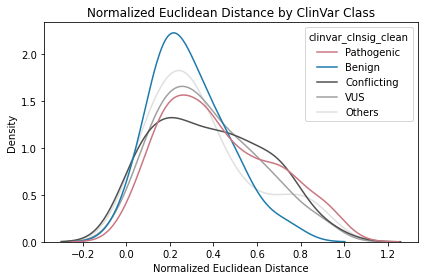

In [ ]:
hue_order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

sns.kdeplot(
    data=orf_distances,
    x='normalized_euclid_distance_normalized',
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    # palette=[color_map.get(k, "gray") for k in hue_order],
    palette=palette_dict['clinvar_clnsig_clean'],
    common_norm=False
)


plt.title('Normalized Euclidean Distance by ClinVar Class')
plt.xlabel('Normalized Euclidean Distance')
plt.tight_layout()
plt.show()

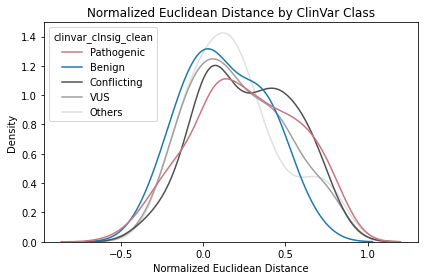

In [ ]:
hue_order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

sns.kdeplot(
    data=orf_distances,
    x='mean_signed_difference',
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    # palette=[color_map.get(k, "gray") for k in hue_order],
    palette=palette_dict['clinvar_clnsig_clean'],
    common_norm=False
)


plt.title('Normalized Euclidean Distance by ClinVar Class')
plt.xlabel('Normalized Euclidean Distance')
plt.tight_layout()
plt.show()

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1887552775.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


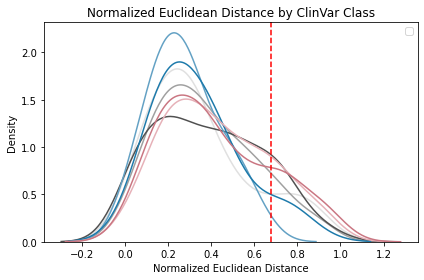

In [ ]:

hue_order = ["Pathogenic", 'Likely pathogenic', "Benign", 'Likely benign', "Conflicting", "VUS", "Others"]

sns.kdeplot(
    data=orf_distances,
    x='normalized_euclid_distance_normalized',
    hue="clinvar_clnsig_clean_pp_strict",
    hue_order=hue_order,
    # palette=[color_map.get(k, "gray") for k in hue_order],
    palette=palette_dict['clinvar_clnsig_clean_pp_strict'],
    common_norm=False
)

# plt.axvline(x=LLR_threshold, color='red', linestyle='--', label='Threshold')

plt.title('Normalized Euclidean Distance by ClinVar Class')
plt.xlabel('Normalized Euclidean Distance')
plt.axvline(x=0.678, color='red', linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()

## LWA

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Dataset balanced: 900 pathogenic, 900 benign


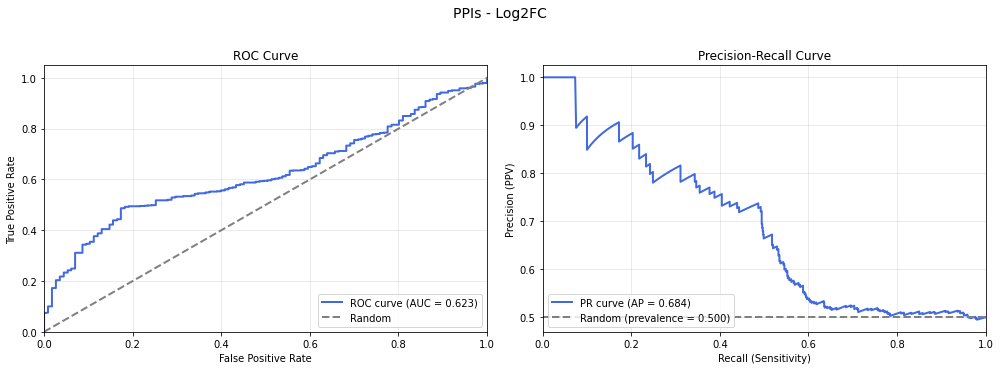


Classification Performance: PPIs - Log2FC
Dataset: 1800 variants (900 pathogenic, 900 benign)

Area Under ROC Curve (AUROC): 0.6229
Area Under PR Curve (AUPRC):  0.6836

Optimal Threshold (Youden): -1.1333

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.4867
  Specificity:           0.8267
  Precision (PPV):       0.7374
  Negative Pred. Value:  0.6169
  Accuracy:              0.6567

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 495
Total unique db_orf_id: 73
Total Pathogenic variants: 243
Total Benign variants: 31


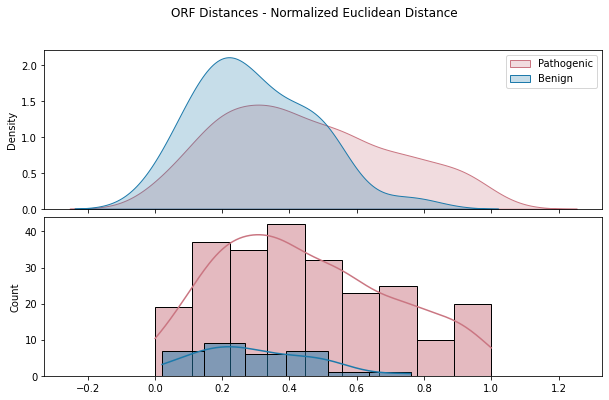

Dataset balanced: 243 pathogenic, 243 benign


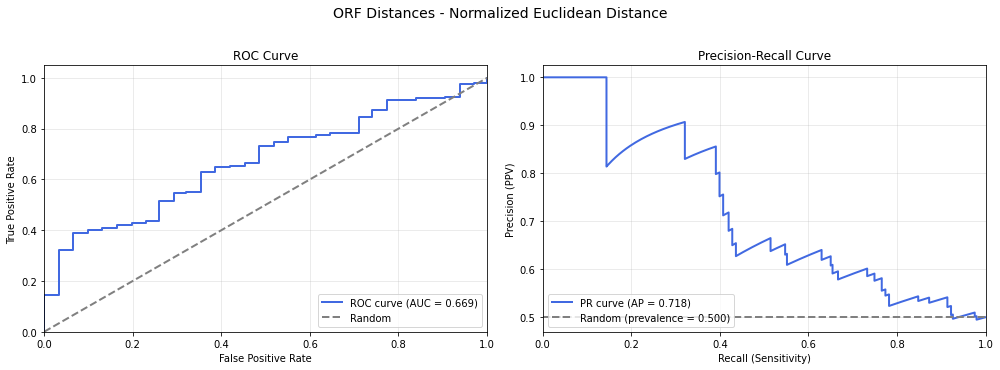


Classification Performance: ORF Distances - Normalized Euclidean Distance
Dataset: 486 variants (243 pathogenic, 243 benign)

Area Under ROC Curve (AUROC): 0.6695
Area Under PR Curve (AUPRC):  0.7175

Optimal Threshold (Youden): -0.5126

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.3909
  Specificity:           0.9342
  Precision (PPV):       0.8559
  Negative Pred. Value:  0.6053
  Accuracy:              0.6626



In [ ]:
min_growth_score = 200
scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']

df_lwa, orf_distances_lwa, perf_lwa, tracking_dict_lwa = run_full_pipeline(min_growth_score=min_growth_score, scoring_conditions=scoring_conditions)

In [ ]:
# number of ppi_group, edge_group, db_orf_id, db_mut_id in df_lwa

print("Final filtered dataframe stats:")
print("Number of unique ppi_group:", df_lwa.select(pl.col("ppi_group").n_unique()).item())
print("Number of unique edge_group:", df_lwa.select(pl.col("edge_group").n_unique()).item())
print("Number of unique db_orf_id:", df_lwa.select(pl.col("db_orf_id").n_unique()).item())
print("Number of unique db_mut_id:", df_lwa.select(pl.col("gene_variant").n_unique()).item() - 1)

Final filtered dataframe stats:
Number of unique ppi_group: 2142
Number of unique edge_group: 293
Number of unique db_orf_id: 73
Number of unique db_mut_id: 495


## AUROC comparison between LWA and non-LWA

In [ ]:
def compare_classification_performance(scores_df1, scores_df2, metric_col, 
                                      label1='Dataset 1', label2='Dataset 2',
                                      title=None, filter_edges=None, 
                                      verbose=False, balance_dataset=False):
    """
    Compare classification performance between two datasets on the same ROC and PR plots.
    
    Parameters:
    -----------
    scores_df1 : polars.DataFrame
        First DataFrame containing scores and clinical significance
    scores_df2 : polars.DataFrame
        Second DataFrame containing scores and clinical significance
    metric_col : str
        Name of the column containing the metric to evaluate (e.g., 'log2fc')
    label1 : str
        Label for first dataset
    label2 : str
        Label for second dataset
    title : str, optional
        Title for the plots
    filter_edges : int, optional
        Minimum number of edges required to include a variant
    balance_dataset : bool, optional
        If True, balance the datasets to have equal benign and pathogenic counts
    
    Returns:
    --------
    dict : Dictionary containing metrics for both datasets
    """
    
    def prepare_data(scores_df, balance=False):
        """Helper function to prepare data for each dataset"""
        scores_pd = scores_df.to_pandas()
        
        # Filter by number of edges if specified
        if filter_edges is not None and 'num_edges' in scores_pd.columns:
            scores_pd = scores_pd[scores_pd['num_edges'] >= filter_edges]
        
        # Filter to only benign and pathogenic
        filtered = scores_pd[scores_pd['clinvar_clnsig_clean'].isin(['Pathogenic', 'Benign'])].copy()
        
        # Remove NaN values in metric column
        filtered = filtered[filtered[metric_col].notna()]
        
        if len(filtered) < 10:
            print(f"Warning: Only {len(filtered)} variants available")
            return None, None, None
        
        # Balance dataset if requested
        if balance:
            n_pathogenic = (filtered['clinvar_clnsig_clean'] == 'Pathogenic').sum()
            n_benign = (filtered['clinvar_clnsig_clean'] == 'Benign').sum()
            
            if n_pathogenic > n_benign:
                benign_samples = filtered[filtered['clinvar_clnsig_clean'] == 'Benign']
                pathogenic_samples = filtered[filtered['clinvar_clnsig_clean'] == 'Pathogenic']
                
                n_repeats = n_pathogenic // n_benign
                n_remainder = n_pathogenic % n_benign
                
                balanced_benign = pd.concat([benign_samples] * n_repeats + 
                                           [benign_samples.sample(n=n_remainder, random_state=42)], 
                                           ignore_index=True)
                filtered = pd.concat([pathogenic_samples, balanced_benign], ignore_index=True)
                
            elif n_benign > n_pathogenic:
                benign_samples = filtered[filtered['clinvar_clnsig_clean'] == 'Benign']
                pathogenic_samples = filtered[filtered['clinvar_clnsig_clean'] == 'Pathogenic']
                
                n_repeats = n_benign // n_pathogenic
                n_remainder = n_benign % n_pathogenic
                
                balanced_pathogenic = pd.concat([pathogenic_samples] * n_repeats + 
                                               [pathogenic_samples.sample(n=n_remainder, random_state=42)], 
                                               ignore_index=True)
                filtered = pd.concat([benign_samples, balanced_pathogenic], ignore_index=True)
        
        # Create binary labels (1 = Pathogenic, 0 = Benign)
        y_true = (filtered['clinvar_clnsig_clean'] == 'Pathogenic').astype(int)
        y_scores = filtered[metric_col].values
        
        # For log2fc, more negative = more pathogenic, so we negate for ROC
        y_scores_roc = -y_scores
        
        return y_true, y_scores_roc, filtered
    
    # Prepare data for both datasets
    y_true1, y_scores1, filtered1 = prepare_data(scores_df1, balance=balance_dataset)
    y_true2, y_scores2, filtered2 = prepare_data(scores_df2, balance=balance_dataset)
    
    if y_true1 is None or y_true2 is None:
        return None
    
    # Calculate metrics for both datasets
    fpr1, tpr1, roc_thresholds1 = roc_curve(y_true1, y_scores1)
    roc_auc1 = auc(fpr1, tpr1)
    precision1, recall1, pr_thresholds1 = precision_recall_curve(y_true1, y_scores1)
    auprc1 = average_precision_score(y_true1, y_scores1)
    
    fpr2, tpr2, roc_thresholds2 = roc_curve(y_true2, y_scores2)
    roc_auc2 = auc(fpr2, tpr2)
    precision2, recall2, pr_thresholds2 = precision_recall_curve(y_true2, y_scores2)
    auprc2 = average_precision_score(y_true2, y_scores2)
    
    # Create comparison plots
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # ROC Curve
    axes[0].plot(fpr1, tpr1, color='royalblue', lw=2, 
                label=f'{label1} (AUC = {roc_auc1:.3f})')
    axes[0].plot(fpr2, tpr2, color='coral', lw=2, 
                label=f'{label2} (AUC = {roc_auc2:.3f})')
    axes[0].plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--', label='Random')
    axes[0].set_xlim([0.0, 1.0])
    axes[0].set_ylim([0.0, 1.05])
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title('ROC Curve Comparison')
    axes[0].legend(loc="lower right")
    axes[0].grid(alpha=0.3)
    
    # Precision-Recall Curve
    axes[1].plot(recall1, precision1, color='royalblue', lw=2,
                label=f'{label1} (AP = {auprc1:.3f})')
    axes[1].plot(recall2, precision2, color='coral', lw=2,
                label=f'{label2} (AP = {auprc2:.3f})')
    axes[1].axhline(y=y_true1.mean(), color='grey', linestyle='--', lw=2,
                    label=f'Random (prevalence = {y_true1.mean():.3f})')
    axes[1].set_xlim([0.0, 1.0])
    axes[1].set_xlabel('Recall (Sensitivity)')
    axes[1].set_ylabel('Precision (PPV)')
    axes[1].set_title('Precision-Recall Curve Comparison')
    axes[1].legend(loc="lower left")
    axes[1].grid(alpha=0.3)
    
    if title:
        fig.suptitle(title, fontsize=14, y=1.02)
    
    plt.tight_layout()
    plt.show()
    
    # Print comparison summary
    if verbose:
        print(f"\n{'='*80}")
        print(f"Classification Performance Comparison: {title if title else metric_col}")
        print(f"{'='*80}")
        print(f"\n{label1}:")
        print(f"  Dataset: {len(filtered1)} variants ({y_true1.sum()} pathogenic, {len(y_true1) - y_true1.sum()} benign)")
        print(f"  AUROC: {roc_auc1:.4f}")
        print(f"  AUPRC: {auprc1:.4f}")
        
        print(f"\n{label2}:")
        print(f"  Dataset: {len(filtered2)} variants ({y_true2.sum()} pathogenic, {len(y_true2) - y_true2.sum()} benign)")
        print(f"  AUROC: {roc_auc2:.4f}")
        print(f"  AUPRC: {auprc2:.4f}")
        
        print(f"\nDifference:")
        print(f"  ΔAUROC: {roc_auc2 - roc_auc1:+.4f}")
        print(f"  ΔAUPRC: {auprc2 - auprc1:+.4f}")
        print(f"{'='*80}\n")
    
    # Return metrics for both datasets
    return {
        'dataset1': {
            'label': label1,
            'auroc': roc_auc1,
            'auprc': auprc1,
            'n_variants': len(filtered1),
            'n_pathogenic': y_true1.sum(),
            'n_benign': len(y_true1) - y_true1.sum(),
            'fpr': fpr1,
            'tpr': tpr1,
            'precision': precision1,
            'recall': recall1
        },
        'dataset2': {
            'label': label2,
            'auroc': roc_auc2,
            'auprc': auprc2,
            'n_variants': len(filtered2),
            'n_pathogenic': y_true2.sum(),
            'n_benign': len(y_true2) - y_true2.sum(),
            'fpr': fpr2,
            'tpr': tpr2,
            'precision': precision2,
            'recall': recall2
        }
    }

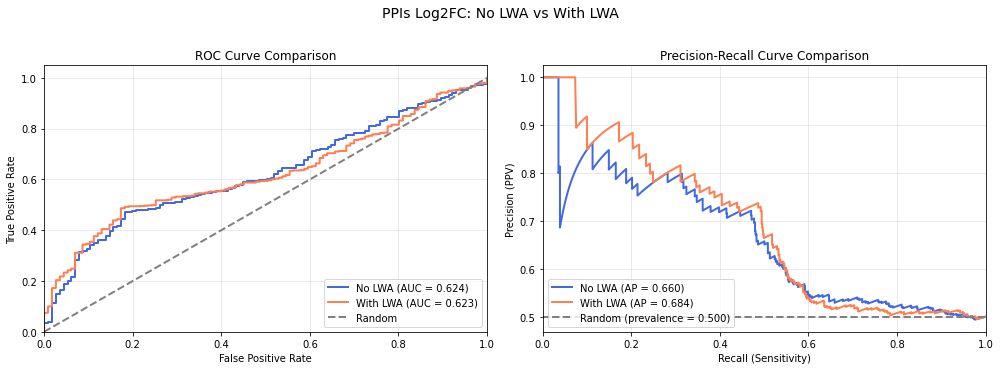


Classification Performance Comparison: PPIs Log2FC: No LWA vs With LWA

No LWA:
  Dataset: 1794 variants (897 pathogenic, 897 benign)
  AUROC: 0.6238
  AUPRC: 0.6601

With LWA:
  Dataset: 1800 variants (900 pathogenic, 900 benign)
  AUROC: 0.6229
  AUPRC: 0.6836

Difference:
  ΔAUROC: -0.0009
  ΔAUPRC: +0.0235



In [ ]:
# Compare df and df_lwa
comparison = compare_classification_performance(
    df.filter(pl.col("db_mut_id") != 0),
    df_lwa.filter(pl.col("db_mut_id") != 0),
    metric_col='log2fc',
    label1='No LWA',
    label2='With LWA',
    title='PPIs Log2FC: No LWA vs With LWA',
    verbose=True,
    balance_dataset=True
)

In [ ]:
# LWA doesn't seem to make a big difference in performance and is quite different from the other 3AT media, so we will proceed with the dataset without LWA for further analyses.

# LLR

In [ ]:
orf_distances.to_pandas().clinvar_clnsig_clean_pp_strict.value_counts()

clinvar_clnsig_clean_pp_strict
Pathogenic           154
Likely pathogenic     89
VUS                   88
Conflicting           81
Others                51
Likely benign         23
Benign                 8
Name: count, dtype: int64

In [ ]:
orf_distances.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Benign", "Likely pathogenic", "Likely benign"])
).with_columns(
    pl.when(
        pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
    )
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("gene_variant").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "normalized_euclid_distance_normalized", "gene_variant", "clinvar_clnsig_clean_pp_strict"])
).write_csv("../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_referenceSet.csv")

orf_distances.with_columns(
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("gene_variant").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_allScores.csv")

In [ ]:
# orf_distances.filter(
#     pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Benign", "Likely pathogenic", "Likely benign"])
# ).with_columns(
#     pl.when(
#         pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
#     )
#     .then(pl.lit("Positive"))
#     .otherwise(pl.lit("Negative"))
#     .alias("referenceSet"),
#     pl.col("mean_signed_difference").alias("score"),
#     pl.col("gene_variant").alias("hgvsp")
# ).select(
#     pl.col(["hgvsp", "score", "referenceSet", "mean_signed_difference", "gene_variant", "clinvar_clnsig_clean_pp_strict"])
# ).write_csv("../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_referenceSet.csv")

# orf_distances.with_columns(
#     pl.col("mean_signed_difference").alias("score"),
#     pl.col("gene_variant").alias("hgvs_pro")
# ).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_allScores.csv")

In [ ]:
# orf_distances.filter(
#     pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Benign", "Likely pathogenic", "Likely benign"])
# ).with_columns(
#     pl.when(
#         pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
#     )
#     .then(pl.lit("Positive"))
#     .otherwise(pl.lit("Negative"))
#     .alias("referenceSet"),
#     pl.col("mean_log2fc").alias("score"),
#     pl.col("gene_variant").alias("hgvsp")
# ).select(
#     pl.col(["hgvsp", "score", "referenceSet", "mean_log2fc", "gene_variant", "clinvar_clnsig_clean_pp_strict"])
# ).write_csv("../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_referenceSet.csv")

# orf_distances.with_columns(
#     pl.col("mean_log2fc").alias("score"),
#     pl.col("gene_variant").alias("hgvs_pro")
# ).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_allScores.csv")

In [ ]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_bcv.log" --bandwidth "bcv" --printTransitions  --kernel "gaussian" --outlierSuppression 0.1
# Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
# Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_default.log" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
# Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_nrd.log" --bandwidth "nrd" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
# Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_sj.log" --printTransitions --bandwidth "SJ" --kernel "gaussian" --outlierSuppression 0.1

Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-16_14:39:00 INFO: Reading input 
2025-12-16_14:39:00 INFO: Calculating densties 


Warning message:
In stats::bw.bcv(data) : minimum occurred at one end of the range


2025-12-16_14:39:01 INFO: Drawing LLR plot 
2025-12-16_14:39:01 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-16_14:39:02 INFO: Category transitions:  
0.650 : none -> patho.support
0.796 : patho.support -> patho.moderate
0.936 : patho.moderate -> patho.strong
2025-12-16_14:39:02 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-12-16_14:39:02 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_score_bcv.csv 
2025-12-16_14:39:02 INFO: Done! 


In [ ]:
# Run to explore multiple parameter combinations

# %%bash
# source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
# conda activate py310

# # Define parameter arrays
# KERNELS=("gaussian" "epanechnikov" "rectangular" "triangular" "biweight" "cosine")
# OUTLIER_SUPPRESSIONS=(0 0.05 0.1 0.15 0.2 0.25 0.30 0.35 0.4 0.45 0.5 0.55 0.6 0.65 0.7 0.75 0.8 0.85 0.9 0.95 1)
# BANDWIDTHS=("bcv" "nrd0" "nrd" "SJ")

# # Loop through all combinations
# for kernel in "${KERNELS[@]}"; do
#     for outlier in "${OUTLIER_SUPPRESSIONS[@]}"; do
#         for bandwidth in "${BANDWIDTHS[@]}"; do
#             # Create meaningful output names
#             output_suffix="${kernel}_${bandwidth}_outlier${outlier}"
            
#             echo "Running with kernel=${kernel}, bandwidth=${bandwidth}, outlierSuppression=${outlier}"
            
#             Rscript ../../threshold_calibration/calcLLR.R \
#                 ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_allScores.csv \
#                 ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_referenceSet.csv \
#                 --outfile "../3_outputs/sqY2H/calcLLR/output/figs/PPI_Best_Media_LLR_${output_suffix}" \
#                 --logfile "../3_outputs/sqY2H/calcLLR/output/log/PPI_Best_Media_LLR_${output_suffix}.log" \
#                 --bandwidth "${bandwidth}" \
#                 --kernel "${kernel}" \
#                 --outlierSuppression ${outlier} \
#                 --printTransitions
#         done
#     done
# done

# echo "All parameter combinations completed!"

In [ ]:
## Run to organize PDF files

# import os
# import shutil
# from pathlib import Path

# # Define paths
# output_base = "../3_outputs/sqY2H/calcLLR/output/figs"
# organized_base = "../3_outputs/sqY2H/calcLLR/output/organized"

# # Create organized directory if it doesn't exist
# Path(organized_base).mkdir(parents=True, exist_ok=True)

# # Get all PDF files, excluding those ending with _prc.pdf
# pdf_files = [f for f in Path(output_base).glob("*.pdf") if not f.stem.endswith("_prc")]

# print(f"Found {len(pdf_files)} PDF files (excluding _prc.pdf files)")

# # Organize files
# for pdf_file in pdf_files:
#     # Extract parameters from filename
#     # Format: PPI_Best_Media_LLR_{kernel}_{bandwidth}_outlier{value}.pdf
#     filename = pdf_file.stem  # Remove .pdf extension
    
#     # Remove prefix
#     if filename.startswith("PPI_Best_Media_LLR_"):
#         params = filename.replace("PPI_Best_Media_LLR_", "")
        
#         # Split into kernel, bandwidth, and outlier
#         parts = params.split("_")
        
#         if len(parts) >= 3:
#             kernel = parts[0]
#             bandwidth = parts[1]
#             outlier = "_".join(parts[2:])  # In case outlier value has underscores
            
#             # Create folder structure: organized/{kernel}/{bandwidth}/
#             folder_path = Path(organized_base) / kernel / bandwidth
#             folder_path.mkdir(parents=True, exist_ok=True)
            
#             # Copy file to organized location
#             dest_path = folder_path / pdf_file.name
#             shutil.copy2(pdf_file, dest_path)
            
#             print(f"Copied {pdf_file.name} -> {kernel}/{bandwidth}/")

# print(f"\nOrganization complete! Files organized in {organized_base}")

# # Print summary
# kernels = [d.name for d in Path(organized_base).iterdir() if d.is_dir()]
# print(f"\nKernels found: {sorted(kernels)}")

# for kernel in sorted(kernels):
#     kernel_path = Path(organized_base) / kernel
#     bandwidths = [d.name for d in kernel_path.iterdir() if d.is_dir()]
#     print(f"\n{kernel}:")
#     for bandwidth in sorted(bandwidths):
#         n_files = len(list((kernel_path / bandwidth).glob("*.pdf")))
#         print(f"  {bandwidth}: {n_files} files")

In [ ]:
# Check distribution at low scores
low_score_data = orf_distances.filter(pl.col("normalized_euclid_distance_normalized") < 0.1)
print(low_score_data.group_by("clinvar_clnsig_clean").agg(pl.count()))

shape: (5, 2)
┌──────────────────────┬───────┐
│ clinvar_clnsig_clean ┆ count │
│ ---                  ┆ ---   │
│ str                  ┆ u32   │
╞══════════════════════╪═══════╡
│ Benign               ┆ 3     │
│ Pathogenic           ┆ 17    │
│ VUS                  ┆ 7     │
│ Conflicting          ┆ 11    │
│ Others               ┆ 7     │
└──────────────────────┴───────┘


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/688382294.py:3: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  print(low_score_data.group_by("clinvar_clnsig_clean").agg(pl.count()))


In [ ]:
LLR_threshold = 0.650

In [ ]:
orf_distances = orf_distances.with_columns(
    pl.when(pl.col("normalized_euclid_distance_normalized") >= LLR_threshold)
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("ppi_hit")
)

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 494
Total unique db_orf_id: 73
Total Pathogenic variants: 243
Total Benign variants: 31
path_thres: 0.7585481545616801
fixed_threshold: 0.65


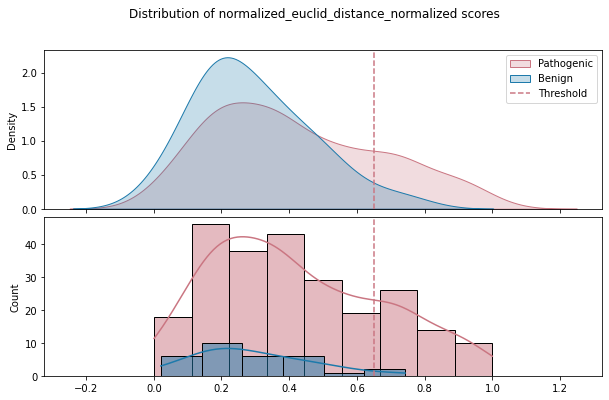

Benign: 1 (3.23%)
Pathogenic: 53 (21.81%)
VUS: 12 (13.64%)
Conflicting: 16 (19.75%)


In [ ]:
plot_patho_benign(scores=orf_distances, threshold=True, fixed_threshold=0.650)

In [ ]:
# Calculate percentage of ppi_hit = True per clinvar_clnsig_clean category
hit_stats = (
    orf_distances
    .group_by("clinvar_clnsig_clean")
    .agg([
        pl.count().alias("total"),
        pl.col("ppi_hit").sum().alias("hits"),
        (pl.col("ppi_hit").sum() / pl.count() * 100).alias("hit_percentage")
    ])
    .sort("hit_percentage", descending=True)
)

print(hit_stats)

shape: (5, 4)
┌──────────────────────┬───────┬──────┬────────────────┐
│ clinvar_clnsig_clean ┆ total ┆ hits ┆ hit_percentage │
│ ---                  ┆ ---   ┆ ---  ┆ ---            │
│ str                  ┆ u32   ┆ u32  ┆ f64            │
╞══════════════════════╪═══════╪══════╪════════════════╡
│ Pathogenic           ┆ 243   ┆ 53   ┆ 21.8107        │
│ Conflicting          ┆ 81    ┆ 16   ┆ 19.753086      │
│ Others               ┆ 51    ┆ 8    ┆ 15.686275      │
│ VUS                  ┆ 88    ┆ 12   ┆ 13.636364      │
│ Benign               ┆ 31    ┆ 1    ┆ 3.225806       │
└──────────────────────┴───────┴──────┴────────────────┘

Detailed Hit Statistics by ClinVar Category:
shape: (5, 5)
┌──────────────────────┬────────────────┬──────────┬──────────┬────────────┐
│ clinvar_clnsig_clean ┆ total_variants ┆ ppi_hits ┆ non_hits ┆ hit_rate_% │
│ ---                  ┆ ---            ┆ ---      ┆ ---      ┆ ---        │
│ str                  ┆ u32            ┆ u32      ┆ u32      ┆ f64 

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2040842287.py:6: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  pl.count().alias("total"),
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2040842287.py:8: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  (pl.col("ppi_hit").sum() / pl.count() * 100).alias("hit_percentage")
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2040842287.py:20: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  pl.count().alias("total_variants"),
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2040842287.py:23: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  (pl.col("ppi_hit").sum() / pl.count() * 100).alias("hit_rate_%")


In [ ]:
orf_distances.write_csv(f"{outputs_dir}/orf_distances_final.csv")

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 494
Total unique db_orf_id: 73
Total Pathogenic variants: 243
Total Benign variants: 31
path_thres: 0.7585481545616801
fixed_threshold: 0.65


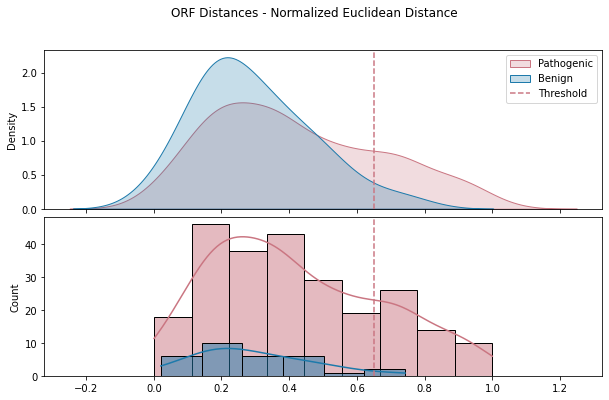

Benign: 1 (3.23%)
Pathogenic: 53 (21.81%)
VUS: 12 (13.64%)
Conflicting: 16 (19.75%)


In [ ]:
plot_patho_benign(orf_distances, metric="normalized_euclid_distance_normalized", threshold=True, fixed_threshold=0.650, title="ORF Distances - Normalized Euclidean Distance")

Plotting mean_signed_difference distribution for Pathogenic and Benign variants
Total variants: 494
Total unique db_orf_id: 73
Total Pathogenic variants: 243
Total Benign variants: 31
path_thres: 0.6644463283493328
fixed_threshold: 0.686


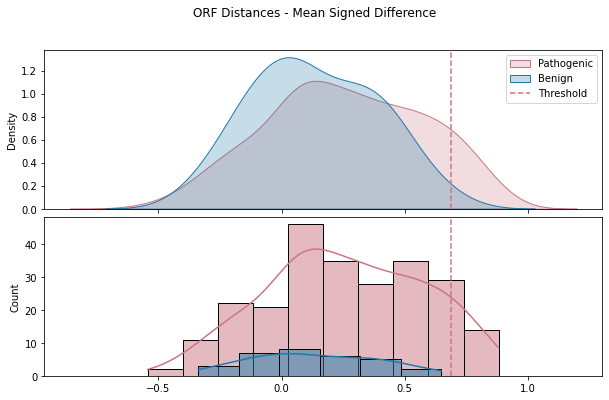

Benign: 0 (0.00%)
Pathogenic: 25 (10.29%)
VUS: 7 (7.95%)
Conflicting: 6 (7.41%)


In [ ]:
plot_patho_benign(orf_distances, metric="mean_signed_difference", threshold=True, fixed_threshold=0.686, title="ORF Distances - Mean Signed Difference")

In [ ]:
orf_distances_no_KCNJ2 = orf_distances.filter(pl.col('symbol') != 'KCNJ2')
orf_distances_no_KCNJ2

db_orf_id,db_mut_id,num_edges,clinvar_clnsig_clean,euclid_distance,nan_euclid_distance,mean_signed_difference,mean_log2fc,max_perturbation,std_perturbation,cv_perturbation,gini_coefficient,edges_disrupted_pct,max_to_mean_ratio,top3_edges_contribution_pct,median_abs_deviation,normalized_euclid_distance,normalized_nan_euclid_distance,normalized_euclid_distance_normalized,normalized_nan_euclid_distance_normalized,max_perturbation_normalized,symbol,aa_change,gene_variant,spdi,nt_change,chr_num,nuc_loc,ref_allele,alt_allele,Chrom,ensembl_gene_id,ccsb_mutation_id,ccsb_allele_id,ensembl_protein_id,collection,entry_plate_orig,…,g2p_O-GlcNAc,g2p_Peptide (UniProt),g2p_Phi angle (degrees)*,g2p_Phosphorylation,g2p_Pocket number (fpocket)*,g2p_Propeptide (UniProt),g2p_Psi angle (degrees)*,g2p_Region (UniProt),g2p_Regulatory sites,g2p_Repeat (UniProt),g2p_SNP-associated PTMs,g2p_SUMOylation,g2p_Secondary structure (DSSP 3-state)*,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,ppi_hit
i64,i64,i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,i64,i64,str,str,str,str,str,str,str,str,str,…,str,str,f64,str,str,str,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,i64,str,bool,bool
13796,218140,2,"""Others""",0.134432,0.15465,-0.109354,-0.195291,0.109354,0.0,0.0,0.0,0.0,1.0,100.0,0.0,0.095058,0.109354,0.107903,0.124132,0.115486,"""HBD""","""Gly17Arg""","""HBD_Gly17Arg""","""NC_000011.10:5234385:C:G""","""49G>C""",11,5234385,"""C""","""G""","""11""","""ENSG00000223609""","""CCSBVarC006557""","""ALE00006556""","""ENSP00000497529.1""","""CEGS2""","""CegsMutGDEh1046""",…,null,null,-59.3,null,null,null,-15.1,null,null,null,"""dbSNP: rs34012192; Variant typ…",null,"""C (loop/coil)""","""T (turn)""",null,null,null,null,null,null,null,null,null,null,null,98.07,84.52381,""">90""","""10-90""",null,null,null,"""Rare genetic hematologic disea…",1,null,false,false
11805,2150,2,"""Conflicting""",0.24452,0.24452,0.172902,0.63856,0.173324,0.000423,0.002444,0.001222,0.0,1.002444,100.0,0.000423,0.172902,0.172902,0.196267,0.196267,0.183043,"""SMAD3""","""Pro263Leu""","""SMAD3_Pro263Leu""","""NC_000015.10:67181370:C:T""","""788C>T""",15,67181370,"""C""","""T""","""15""","""ENSG00000166949""","""CCSBVarC004695""","""ALE00004695""","""ENSP00000332973.4""","""Edgotyping3""","""VUSMutGDEh005""",…,null,null,-86.7,null,null,null,-9.0,null,null,null,null,null,"""C (loop/coil)""","""S (bend)""",null,null,null,null,null,null,null,null,null,null,null,92.14,80.14706,""">90""","""10-90""","""613795""","""autosomal dominant""","""OMIM""","""Rare genetic vascular disease;…",2,"""LOEYS-DIETZ SYNDROME 3""",false,false
70497,3843,1,"""Conflicting""",0.326309,0.326309,0.326309,1.586849,0.326309,0.0,0.0,0.0,100.0,1.0,100.0,0.0,0.326309,0.326309,0.370405,0.370405,0.344607,"""AGXT""","""Asp201Asn""","""AGXT_Asp201Asn""","""NC_000002.12:240873983:G:A""","""601G>A""",2,240873983,"""G""","""A""","""2""","""ENSG00000172482""","""CCSBVarC008203""","""ALE00008189""","""ENSP00000302620.3""","""Edgotyping3""","""VUSMutGDEh004""",…,null,null,-88.2,null,null,null,-36.7,null,null,null,null,null,"""C (loop/coil)""","""S (bend)""","""Beta strand""",null,null,null,null,null,null,null,null,null,null,98.96,2.4539876,""">90""","""<10""","""259900""","""autosomal recessive""","""OMIM""","""Rare genetic eye disease; Rare…",3,"""HYPEROXALURIA, PRIMARY, TYPE I""",false,false
70497,3792,1,"""Pathogenic""",0.000696,0.000696,0.000696,0.002054,0.000696,0.0,0

Plotting mean_log2fc distribution for Pathogenic and Benign variants
Total variants: 494
Total unique db_orf_id: 73
Total Pathogenic variants: 243
Total Benign variants: 31
path_thres: 7.733655988610181
fixed_threshold: 0.686


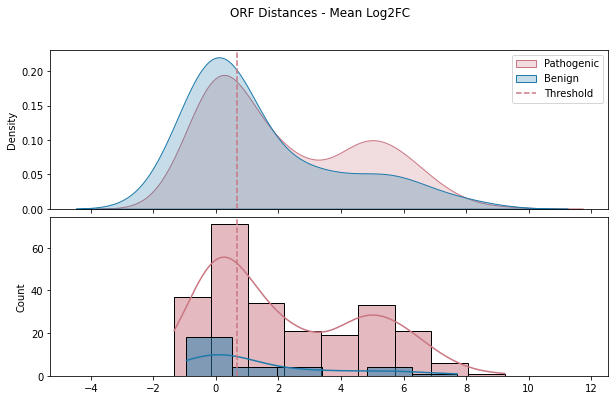

Benign: 12 (38.71%)
Pathogenic: 144 (59.26%)
VUS: 50 (56.82%)
Conflicting: 48 (59.26%)


In [ ]:
plot_patho_benign(orf_distances, metric="mean_log2fc", threshold=True, fixed_threshold=0.686, title="ORF Distances - Mean Log2FC")

Plotting mean_log2fc distribution for Pathogenic and Benign variants
Total variants: 468
Total unique db_orf_id: 72
Total Pathogenic variants: 231
Total Benign variants: 30
path_thres: 7.733655988610181
fixed_threshold: 3.5


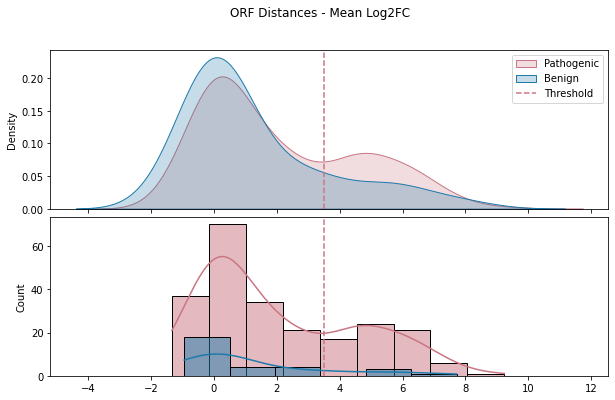

Benign: 4 (13.33%)
Pathogenic: 69 (29.87%)
VUS: 18 (21.43%)
Conflicting: 18 (25.00%)


In [ ]:
plot_patho_benign(orf_distances_no_KCNJ2, metric="mean_log2fc", threshold=True, fixed_threshold=3.5, title="ORF Distances - Mean Log2FC")

Dataset balanced: 243 pathogenic, 243 benign


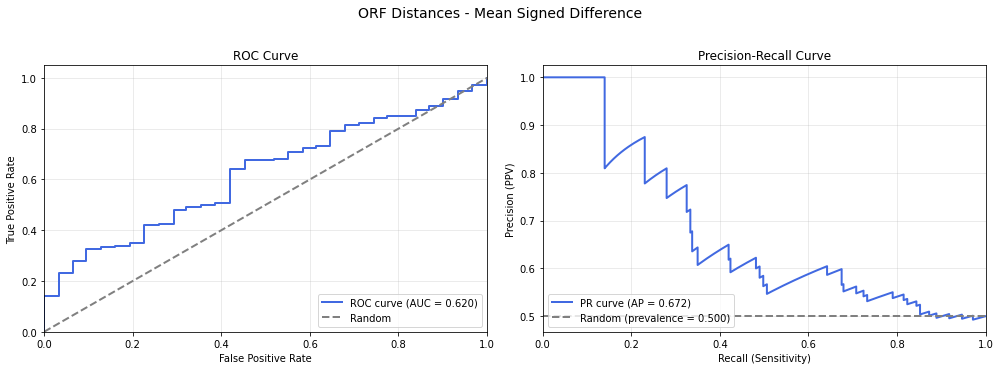


Classification Performance: ORF Distances - Mean Signed Difference
Dataset: 486 variants (243 pathogenic, 243 benign)

Area Under ROC Curve (AUROC): 0.6197
Area Under PR Curve (AUPRC):  0.6717

Optimal Threshold (Youden): -0.4406

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.3251
  Specificity:           0.9053
  Precision (PPV):       0.7745
  Negative Pred. Value:  0.5729
  Accuracy:              0.6152



In [ ]:
# Evaluate classification performance
perf = evaluate_classification_performance(
    orf_distances.filter(pl.col("db_mut_id") != 0),
    metric_col='mean_signed_difference',
    title='ORF Distances - Mean Signed Difference',
    verbose=True,
    balance_dataset=True
)

Dataset balanced: 243 pathogenic, 243 benign


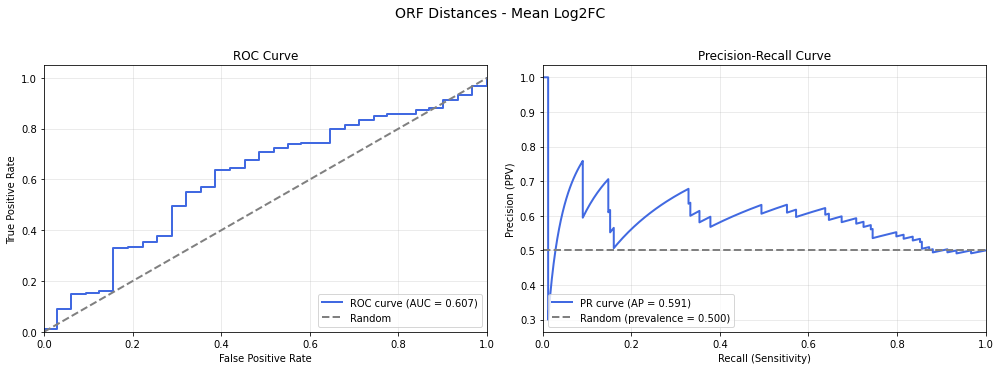


Classification Performance: ORF Distances - Mean Log2FC
Dataset: 486 variants (243 pathogenic, 243 benign)

Area Under ROC Curve (AUROC): 0.6074
Area Under PR Curve (AUPRC):  0.5907

Optimal Threshold (Youden): -0.5451

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.6379
  Specificity:           0.6132
  Precision (PPV):       0.6225
  Negative Pred. Value:  0.6287
  Accuracy:              0.6255



In [ ]:
# Evaluate classification performance
perf = evaluate_classification_performance(
    orf_distances.filter(pl.col("db_mut_id") != 0),
    metric_col='mean_log2fc',
    title='ORF Distances - Mean Log2FC',
    verbose=True,
    balance_dataset=True
)

Dataset balanced: 243 pathogenic, 243 benign


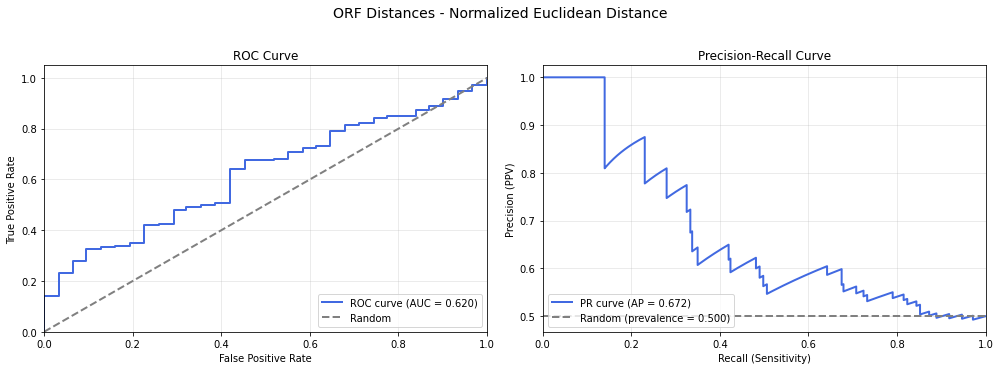


Classification Performance: ORF Distances - Normalized Euclidean Distance
Dataset: 486 variants (243 pathogenic, 243 benign)

Area Under ROC Curve (AUROC): 0.6197
Area Under PR Curve (AUPRC):  0.6717

Optimal Threshold (Youden): -0.4406

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.3251
  Specificity:           0.9053
  Precision (PPV):       0.7745
  Negative Pred. Value:  0.5729
  Accuracy:              0.6152



In [ ]:
# Evaluate classification performance
perf = evaluate_classification_performance(
    orf_distances.filter(pl.col("db_mut_id") != 0),
    metric_col='mean_signed_difference',
    title='ORF Distances - Normalized Euclidean Distance',
    verbose=True,
    balance_dataset=True
)

In [ ]:
df_pd = df.to_pandas()

df_pd[(
    df_pd.symbol == 'STXBP1'
) &
      (df_pd.aa_change.str.contains('Arg406'))
      ][['aa_change','clinvar_clnsig_clean_pp_strict', 'ad_symbol' ,'log2fc']]

,aa_change,clinvar_clnsig_clean_pp_strict,ad_symbol,log2fc
587,Arg406His,Likely pathogenic,CENPP,-5.029993
592,Arg406Leu,Likely pathogenic,CENPP,-5.042973
774,Arg406His,Likely pathogenic,SYTL4,-3.439792
775,Arg406Leu,Likely pathogenic,SYTL4,-7.713567
860,Arg406Leu,Likely pathogenic,TRIM38,-6.249099
863,Arg406His,Likely pathogenic,TRIM38,-0.467193
1934,Arg406Leu,Likely pathogenic,STX5,-3.640812
1938,Arg406His,Likely pathogenic,STX5,-1.276581


In [ ]:
df_pd = df.to_pandas()

df_pd[(
    df_pd.symbol == 'STXBP1'
) &
      (df_pd.aa_change.str.contains('Arg190'))
      ][['aa_change','clinvar_clnsig_clean_pp_strict', 'ad_symbol' ,'log2fc']]

,aa_change,clinvar_clnsig_clean_pp_strict,ad_symbol,log2fc
572,Arg190Gln,Conflicting,CENPP,-4.687753
576,Arg190Trp,Pathogenic,CENPP,-5.031770
766,Arg190Trp,Pathogenic,SYTL4,-9.439702
839,Arg190Gln,Conflicting,TRIM38,-5.983777
884,Arg190Gln,Conflicting,STX19,-6.846388
888,Arg190Trp,Pathogenic,STX19,-1.061301
1912,Arg190Gln,Conflicting,STX5,-4.340951
1923,Arg190Trp,Pathogenic,STX5,-1.329696


## Edge level

Plotting log2fc distribution for Pathogenic and Benign variants
Total variants: 2139
Total unique db_orf_id: 73
Total Pathogenic variants: 897
Total Benign variants: 116


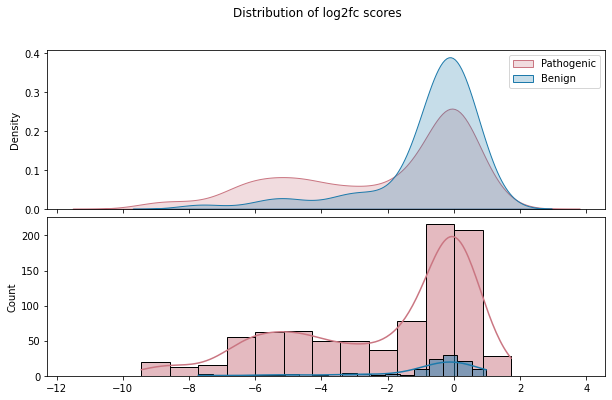

In [ ]:
plot_patho_benign(scores=df, metric="log2fc")

In [ ]:
df.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Benign", "Likely pathogenic", "Likely benign"])
).with_columns(
    pl.when(
        pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
    )
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("log2fc").alias("score"),
    pl.col("ppi_group").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "log2fc", "ppi_group", "clinvar_clnsig_clean_pp_strict"])
).write_csv("../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_Edges_referenceSet.csv")

df.with_columns(
    pl.col("log2fc").alias("score"),
    pl.col("ppi_group").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_Edges_allScores.csv")

In [ ]:
# %%bash
# source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
# conda activate py310

# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_bcv.log" --bandwidth "bcv" --printTransitions
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_default.log" --printTransitions
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_nrd.log" --bandwidth "nrd" --printTransitions
# # Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_sj.log" --printTransitions --bandwidth "SJ"

In [ ]:
# %%bash
# source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
# conda activate py310

# # Define parameter arrays
# KERNELS=("gaussian" "epanechnikov" "rectangular" "triangular" "biweight" "cosine")
# OUTLIER_SUPPRESSIONS=(0 0.05 0.1 0.15 0.2 0.25 0.30 0.35 0.4 0.45 0.5 0.55 0.6 0.65 0.7 0.75 0.8 0.85 0.9 0.95 1)
# BANDWIDTHS=("bcv" "nrd0" "nrd" "SJ")

# # Loop through all combinations
# for kernel in "${KERNELS[@]}"; do
#     for outlier in "${OUTLIER_SUPPRESSIONS[@]}"; do
#         for bandwidth in "${BANDWIDTHS[@]}"; do
#             # Create meaningful output names
#             output_suffix="${kernel}_${bandwidth}_outlier${outlier}"
            
#             echo "Running with kernel=${kernel}, bandwidth=${bandwidth}, outlierSuppression=${outlier}"
            
#             Rscript ../../threshold_calibration/calcLLR.R \
#                 ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_Edges_allScores.csv \
#                 ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_Edges_referenceSet.csv \
#                 --outfile "../3_outputs/sqY2H/calcLLR/output/edges/figs/PPI_Best_Media_Edges_LLR_${output_suffix}" \
#                 --logfile "../3_outputs/sqY2H/calcLLR/output/edges/log/PPI_Best_Media_Edges_LLR_${output_suffix}.log" \
#                 --bandwidth "${bandwidth}" \
#                 --kernel "${kernel}" \
#                 --outlierSuppression ${outlier} \
#                 --printTransitions
#         done
#     done
# done

# echo "All parameter combinations completed!"

In [ ]:
# import os
# import shutil
# from pathlib import Path

# # Define paths
# output_base = "../3_outputs/sqY2H/calcLLR/output/edges/figs"
# organized_base = "../3_outputs/sqY2H/calcLLR/output/edges/organized"

# # Create organized directory if it doesn't exist
# Path(organized_base).mkdir(parents=True, exist_ok=True)

# # Get all PDF files, excluding those ending with _prc.pdf
# pdf_files = [f for f in Path(output_base).glob("*.pdf") if not f.stem.endswith("_prc")]

# print(f"Found {len(pdf_files)} PDF files (excluding _prc.pdf files)")

# # Organize files
# for pdf_file in pdf_files:
#     # Extract parameters from filename
#     # Format: PPI_Best_Media_LLR_{kernel}_{bandwidth}_outlier{value}.pdf
#     filename = pdf_file.stem  # Remove .pdf extension
    
#     # Remove prefix
#     if filename.startswith("PPI_Best_Media_Edges_LLR_"):
#         params = filename.replace("PPI_Best_Media_Edges_LLR_", "")
        
#         # Split into kernel, bandwidth, and outlier
#         parts = params.split("_")
        
#         if len(parts) >= 3:
#             kernel = parts[0]
#             bandwidth = parts[1]
#             outlier = "_".join(parts[2:])  # In case outlier value has underscores
            
#             # Create folder structure: organized/{kernel}/{bandwidth}/
#             folder_path = Path(organized_base) / kernel / bandwidth
#             folder_path.mkdir(parents=True, exist_ok=True)
            
#             # Copy file to organized location
#             dest_path = folder_path / pdf_file.name
#             shutil.copy2(pdf_file, dest_path)
            
#             print(f"Copied {pdf_file.name} -> {kernel}/{bandwidth}/")

# print(f"\nOrganization complete! Files organized in {organized_base}")

# # Print summary
# kernels = [d.name for d in Path(organized_base).iterdir() if d.is_dir()]
# print(f"\nKernels found: {sorted(kernels)}")

# for kernel in sorted(kernels):
#     kernel_path = Path(organized_base) / kernel
#     bandwidths = [d.name for d in kernel_path.iterdir() if d.is_dir()]
#     print(f"\n{kernel}:")
#     for bandwidth in sorted(bandwidths):
#         n_files = len(list((kernel_path / bandwidth).glob("*.pdf")))
#         print(f"  {bandwidth}: {n_files} files")

# plots

## struct

In [ ]:
def plot_structural_features_by_clinvar(orf_distances, features=['plddt', 'rsa'], clinvar_col='clinvar_clnsig_clean'):
    """
    Plot structural features (pLDDT, RSA) distributions for each ClinVar category.
    
    Parameters:
    -----------
    orf_distances : pl.DataFrame
        DataFrame containing structural features and ClinVar annotations
    features : list
        List of structural features to plot (e.g., ['plddt', 'rsa'])
    clinvar_col : str
        Column name containing ClinVar classifications
    """
    # Color palette for ClinVar categories
    # palette_dict = {
    #     'Pathogenic': "#CA7682",
    #     'Benign': "#1D7AAB",
    #     'Conflicting': "#505050",
    #     'VUS': "#A0A0A0",
    #     'Others': "#E0E0E0"
    # }
    
    # Convert to pandas for easier plotting
    df_pd = orf_distances.to_pandas()
    
    # Filter out nulls and get categories
    df_filtered = df_pd[df_pd[clinvar_col].notna()].copy()
    categories = df_filtered[clinvar_col].unique()
    
    # Create subplots
    n_features = len(features)
    fig, axes = plt.subplots(n_features, 2, figsize=(14, 5*n_features))
    
    # Make axes 2D array even if only one feature
    if n_features == 1:
        axes = axes.reshape(1, -1)
    
    for feat_idx, feature in enumerate(features):
        # Filter for non-null feature values
        df_feat = df_filtered[df_filtered[feature].notna()].copy()
        
        # KDE plot (left column)
        ax_kde = axes[feat_idx, 0]
        for category in categories:
            if category in palette_dict[clinvar_col]:
                data = df_feat[df_feat[clinvar_col] == category][feature]
                if len(data) > 0:
                    sns.kdeplot(
                        data=data, 
                        label=f'{category} (n={len(data)})',
                        color=palette_dict[clinvar_col].get(category, 'gray'),
                        fill=True,
                        alpha=0.3,
                        ax=ax_kde
                    )
        
        ax_kde.set_xlabel(feature.upper())
        ax_kde.set_ylabel('Density')
        ax_kde.set_title(f'{feature.upper()} Distribution by ClinVar Category')
        ax_kde.legend()
        ax_kde.grid(alpha=0.3)
        
        # Box plot (right column)
        ax_box = axes[feat_idx, 1]
        
        # Prepare data for boxplot
        plot_data = []
        plot_labels = []
        plot_colors = []
        
        for category in ['Benign', 'Likely benign', 'VUS', 'Conflicting', 'Likely pathogenic', 'Pathogenic']:
            if category in df_feat[clinvar_col].values:
                data = df_feat[df_feat[clinvar_col] == category][feature].dropna()
                if len(data) > 0:
                    plot_data.append(data)
                    plot_labels.append(f'{category}\n(n={len(data)})')
                    plot_colors.append(palette_dict[clinvar_col].get(category, 'gray'))
        
        # Create boxplot
        bp = ax_box.boxplot(plot_data, labels=plot_labels, patch_artist=True)
        
        # Color the boxes
        for patch, color in zip(bp['boxes'], plot_colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.6)
        
        ax_box.set_ylabel(feature.upper())
        ax_box.set_title(f'{feature.upper()} by ClinVar Category')
        ax_box.grid(alpha=0.3, axis='y')
        ax_box.tick_params(axis='x', rotation=45)
        
        # Print statistics
        print(f"\n{'='*60}")
        print(f"{feature.upper()} Statistics by ClinVar Category")
        print(f"{'='*60}")
        for category in categories:
            data = df_feat[df_feat[clinvar_col] == category][feature].dropna()
            if len(data) > 0:
                print(f"{category:20s}: n={len(data):4d}, mean={data.mean():.3f}, "
                      f"median={data.median():.3f}, std={data.std():.3f}")
    
    plt.tight_layout()
    plt.show()
    
    return fig

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3945754855.py:80: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_box.boxplot(plot_data, labels=plot_labels, patch_artist=True)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3945754855.py:80: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_box.boxplot(plot_data, labels=plot_labels, patch_artist=True)



PLDDT Statistics by ClinVar Category
Others              : n=  46, mean=89.901, median=95.795, std=12.863
Conflicting         : n=  80, mean=84.689, median=95.000, std=20.609
Pathogenic          : n= 243, mean=92.286, median=97.310, std=11.866
VUS                 : n=  87, mean=85.194, median=92.870, std=17.541
Benign              : n=  31, mean=74.584, median=88.240, std=25.705

RSA Statistics by ClinVar Category
Others              : n=  46, mean=0.467, median=0.539, std=0.260
Conflicting         : n=  80, mean=0.456, median=0.464, std=0.303
Pathogenic          : n= 243, mean=0.272, median=0.141, std=0.284
VUS                 : n=  87, mean=0.388, median=0.331, std=0.334
Benign              : n=  31, mean=0.598, median=0.680, std=0.310


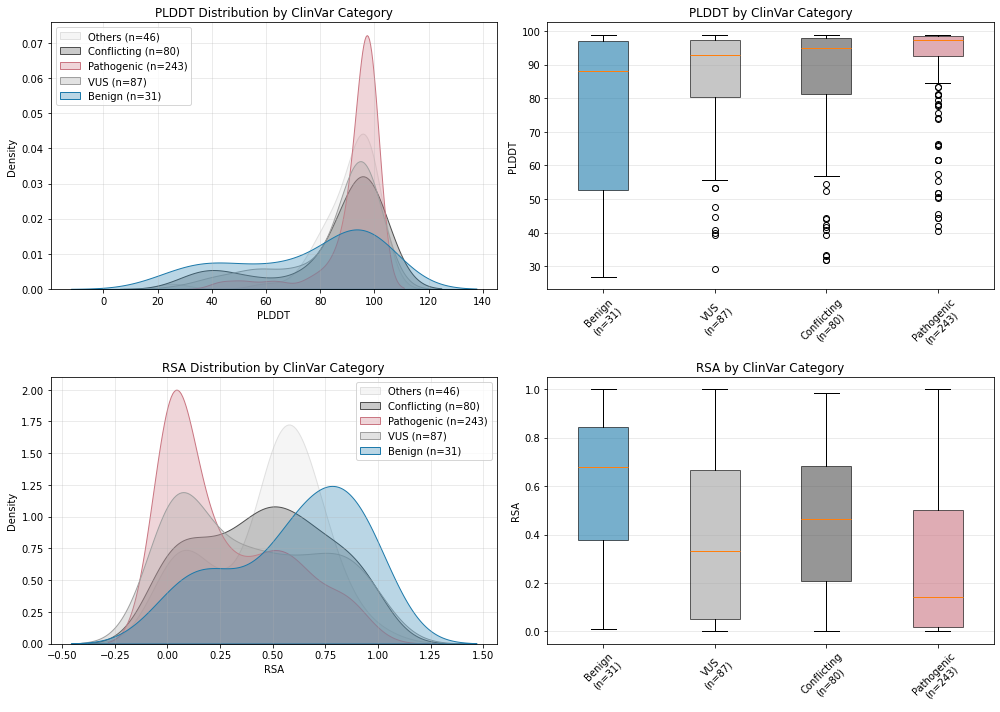

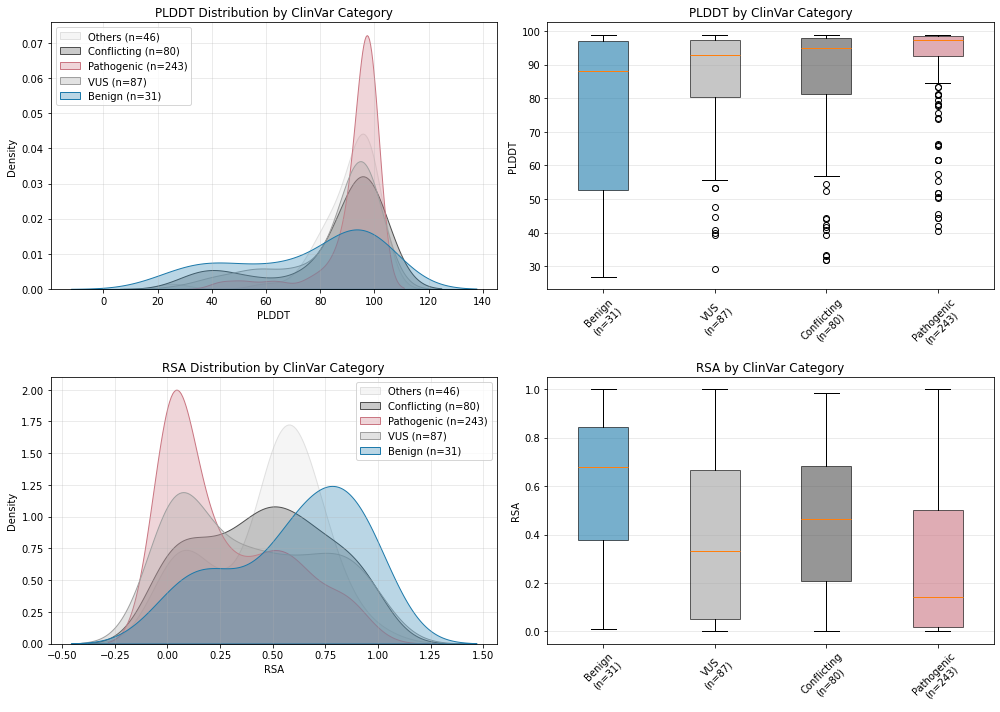

In [ ]:
# Plot pLDDT and RSA for main ClinVar categories
plot_structural_features_by_clinvar(
    orf_distances, 
    features=['plddt', 'rsa'],
    clinvar_col='clinvar_clnsig_clean'
)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3945754855.py:80: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_box.boxplot(plot_data, labels=plot_labels, patch_artist=True)



PLDDT Statistics by ClinVar Category
Others              : n=  46, mean=89.901, median=95.795, std=12.863
Conflicting         : n=  80, mean=84.689, median=95.000, std=20.609
Pathogenic          : n= 154, mean=91.181, median=96.670, std=12.960
Likely pathogenic   : n=  89, mean=94.199, median=97.850, std=9.453
VUS                 : n=  87, mean=85.194, median=92.870, std=17.541
Likely benign       : n=  23, mean=76.313, median=88.240, std=23.828
Benign              : n=   8, mean=69.611, median=78.930, std=31.767

RSA Statistics by ClinVar Category
Others              : n=  46, mean=0.467, median=0.539, std=0.260
Conflicting         : n=  80, mean=0.456, median=0.464, std=0.303
Pathogenic          : n= 154, mean=0.302, median=0.224, std=0.294
Likely pathogenic   : n=  89, mean=0.219, median=0.113, std=0.259
VUS                 : n=  87, mean=0.388, median=0.331, std=0.334
Likely benign       : n=  23, mean=0.545, median=0.560, std=0.319
Benign              : n=   8, mean=0.748, median

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3945754855.py:80: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_box.boxplot(plot_data, labels=plot_labels, patch_artist=True)


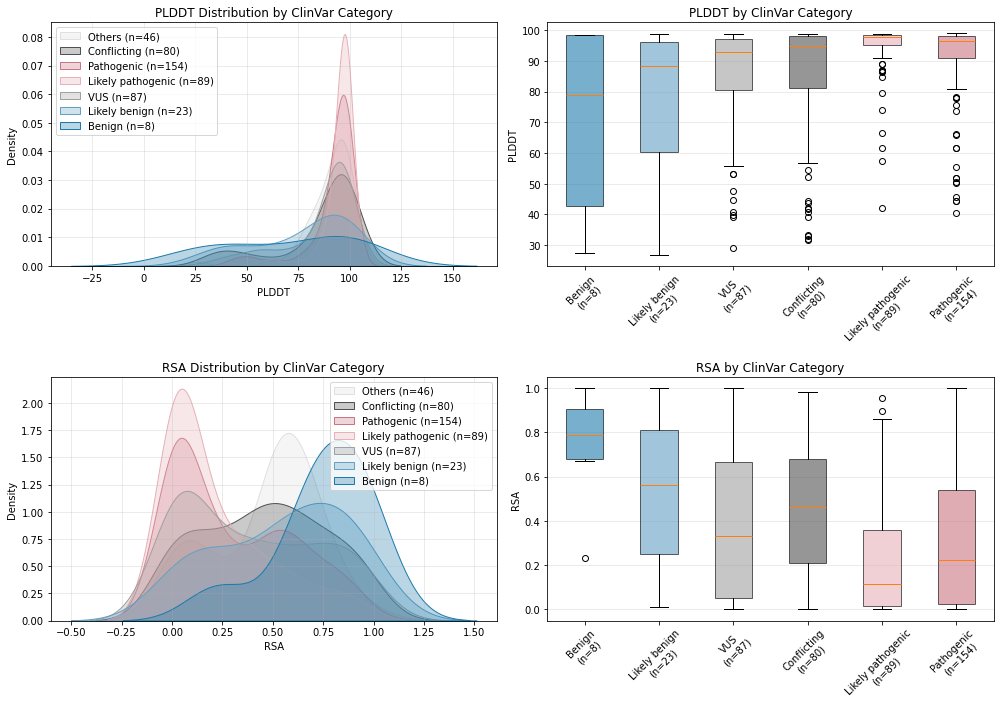

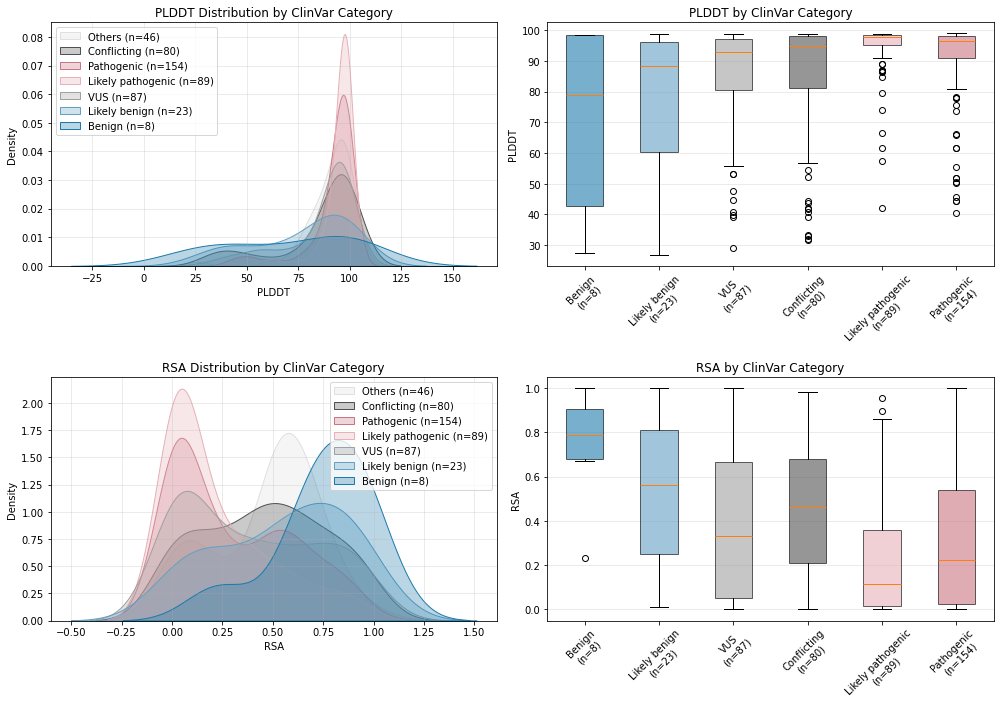

In [ ]:
# Plot using stricter ClinVar classification
plot_structural_features_by_clinvar(
    orf_distances, 
    features=['plddt', 'rsa'],
    clinvar_col='clinvar_clnsig_clean_pp_strict'
)

## scores

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/771649454.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/771649454.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


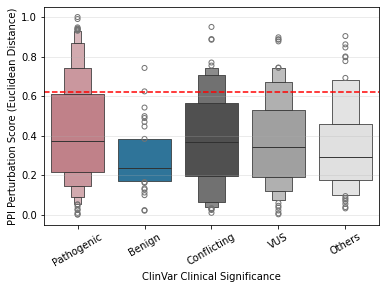

In [ ]:

order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

ax = sns.boxenplot(
    data=orf_distances,
    x="clinvar_clnsig_clean",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.set_xlabel("ClinVar Clinical Significance")
plt.axhline(y=0.620, color='red', linestyle='--', label='LLR Threshold (0.620)')
plt.show()


In [ ]:
def add_statistical_annotations(ax, data, x_col, y_col, order=None, test='mannwhitneyu', 
                                comparisons='all_significant', y_offset_factor=0.05, 
                                fontsize=10, alpha=0.05, fdr_correction=True, fdr_method='fdr_bh'):
    """
    Add statistical significance annotations to a plot.
    
    Parameters:
    -----------
    ax : matplotlib.axes.Axes
        The axes object to add annotations to
    data : pl.DataFrame or pd.DataFrame
        DataFrame containing the data
    x_col : str
        Column name for x-axis categories
    y_col : str
        Column name for y-axis values
    order : list, optional
        Order of categories on x-axis
    test : str
        Statistical test to use ('mannwhitneyu', 'ttest', 'kruskal')
    comparisons : str or list of tuples
        'all_significant' to test all pairs and show only significant ones
        'adjacent' for adjacent pairs only
        Or list of specific pairs: [('Pathogenic', 'Benign'), ...]
    y_offset_factor : float
        Vertical offset for annotation bars as fraction of y-range
    fontsize : int
        Font size for significance stars
    alpha : float
        Significance level threshold (default: 0.05)
    fdr_correction : bool
        Whether to apply FDR correction for multiple testing (default: True)
    fdr_method : str
        FDR correction method ('fdr_bh' for Benjamini-Hochberg, 'fdr_by' for Benjamini-Yekutieli)
        
    Returns:
    --------
    dict : Dictionary with test results for each comparison
    """
    from scipy import stats as scipy_stats
    from statsmodels.stats.multitest import multipletests
    import pandas as pd
    import numpy as np
    from itertools import combinations
    
    # Convert to pandas if needed
    if hasattr(data, 'to_pandas'):
        df = data.to_pandas()
    else:
        df = data.copy()
    
    # Get order if not specified
    if order is None:
        order = df[x_col].unique().tolist()
    
    # Filter data for categories in order
    df = df[df[x_col].isin(order)].copy()
    
    # Set up comparisons
    if comparisons == 'all_significant':
        # Test all possible pairs
        all_pairs = list(combinations(order, 2))
    elif comparisons == 'adjacent':
        all_pairs = [(order[i], order[i+1]) for i in range(len(order)-1)]
    else:
        all_pairs = comparisons
    
    # Store all results
    all_results = {}
    
    # Perform tests on all pairs
    for cat1, cat2 in all_pairs:
        # Get data for each category
        data1 = df[df[x_col] == cat1][y_col].dropna()
        data2 = df[df[x_col] == cat2][y_col].dropna()
        
        if len(data1) < 2 or len(data2) < 2:
            continue
        
        # Perform statistical test
        if test == 'mannwhitneyu':
            statistic, p_value = scipy_stats.mannwhitneyu(data1, data2, alternative='two-sided')
            test_name = 'Mann-Whitney U'
        elif test == 'ttest':
            statistic, p_value = scipy_stats.ttest_ind(data1, data2)
            test_name = 't-test'
        elif test == 'kruskal':
            statistic, p_value = scipy_stats.kruskal(data1, data2)
            test_name = 'Kruskal-Wallis'
        
        # Store results
        all_results[f"{cat1}_vs_{cat2}"] = {
            'statistic': statistic,
            'p_value': p_value,
            'test': test_name,
            'n1': len(data1),
            'n2': len(data2),
            'mean1': data1.mean(),
            'mean2': data2.mean(),
            'median1': data1.median(),
            'median2': data2.median(),
            'cat1': cat1,
            'cat2': cat2
        }
    
    # Apply FDR correction if requested
    if fdr_correction and all_results:
        p_values = [v['p_value'] for v in all_results.values()]
        reject, p_adjusted, _, _ = multipletests(p_values, alpha=alpha, method=fdr_method)
        
        # Add adjusted p-values to results
        for (key, result), p_adj, is_reject in zip(all_results.items(), p_adjusted, reject):
            result['p_value_adjusted'] = p_adj
            result['reject_null_fdr'] = is_reject
    
    # Filter for significant results
    if comparisons == 'all_significant':
        if fdr_correction:
            significant_results = {k: v for k, v in all_results.items() 
                                 if v.get('reject_null_fdr', False)}
        else:
            significant_results = {k: v for k, v in all_results.items() 
                                 if v['p_value'] < alpha}
    else:
        significant_results = all_results
    
    if not significant_results:
        correction_text = " (FDR-corrected)" if fdr_correction else ""
        print(f"No significant comparisons found at alpha={alpha}{correction_text}")
        return all_results
    
    # Get y-axis limits for positioning
    y_min, y_max = ax.get_ylim()
    y_range = y_max - y_min
    y_offset = y_range * y_offset_factor
    
    # Calculate max y value for starting position
    # Use the current plot top limit to ensure we clear violin tips
    current_y = y_max + y_offset
    
    # Sort comparisons by adjusted p-value if FDR, else by p-value
    sort_key = 'p_value_adjusted' if fdr_correction else 'p_value'
    sorted_comparisons = sorted(significant_results.items(), 
                               key=lambda x: x[1].get(sort_key, x[1]['p_value']))
    
    # Add annotations for significant results
    for comparison_name, stats in sorted_comparisons:
        cat1 = stats['cat1']
        cat2 = stats['cat2']
        
        # Use adjusted p-value if FDR correction is applied
        p_value = stats.get('p_value_adjusted', stats['p_value']) if fdr_correction else stats['p_value']
        
        # Determine significance stars
        if p_value < 0.001:
            sig_text = '***'
        elif p_value < 0.01:
            sig_text = f'p = {p_value:.3f}\n**'
        elif p_value < 0.05:
            sig_text = f'p = {p_value:.3f}\n*'
        else:
            continue  # Skip non-significant
        
        # Get x positions
        x1 = order.index(cat1)
        x2 = order.index(cat2)
        
        # Draw horizontal line
        ax.plot([x1, x2], [current_y, current_y], 'k-', lw=1.5)
        
        # Draw vertical ticks
        tick_height = y_offset * 0.2
        ax.plot([x1, x1], [current_y, current_y - tick_height], 'k-', lw=1.5)
        ax.plot([x2, x2], [current_y, current_y - tick_height], 'k-', lw=1.5)
        
        # Add significance text
        ax.text((x1 + x2) / 2, current_y + y_offset * 0.1, sig_text,
               ha='center', va='bottom', fontsize=fontsize, fontweight='bold')
        
        # Update y position for next comparison
        current_y += y_offset * 1.5
    
    # Adjust y-axis limit to accommodate annotations
    if sorted_comparisons:
        ax.set_ylim(y_min, current_y + y_offset * 0.5)
        
    return all_results

def print_statistical_summary(results, verbose=True, alpha=0.05, show_all=False, use_fdr=True):
    """
    Print summary of statistical test results.
    
    Parameters:
    -----------
    results : dict
        Dictionary returned by add_statistical_annotations
    verbose : bool
        Whether to print detailed output
    alpha : float
        Significance threshold for highlighting
    show_all : bool
        If True, show all comparisons; if False, show only significant ones
    use_fdr : bool
        Whether to use FDR-adjusted p-values for filtering (if available)
    """
    if not verbose:
        return
    
    # Check if FDR correction was applied
    has_fdr = any('p_value_adjusted' in v for v in results.values())
    
    # Filter results if requested
    if show_all:
        display_results = results
        title = "All Statistical Test Results"
    else:
        if has_fdr and use_fdr:
            display_results = {k: v for k, v in results.items() 
                             if v.get('reject_null_fdr', False)}
            title = f"Significant Statistical Test Results (FDR-corrected, alpha={alpha})"
        else:
            display_results = {k: v for k, v in results.items() 
                             if v['p_value'] < alpha}
            title = f"Significant Statistical Test Results (p < {alpha})"
    
    if not display_results:
        fdr_text = " (FDR-corrected)" if (has_fdr and use_fdr) else ""
        print(f"\nNo {'significant ' if not show_all else ''}results to display{fdr_text}")
        return
    
    print(f"\n{'='*80}")
    print(title)
    print(f"{'='*80}")
    print(f"Total comparisons: {len(results)}")
    
    if has_fdr:
        print(f"Significant comparisons (FDR): {sum(1 for v in results.values() if v.get('reject_null_fdr', False))}")
    print(f"Significant comparisons (unadjusted): {sum(1 for v in results.values() if v['p_value'] < alpha)}")
    print(f"{'='*80}")
    
    # Sort by adjusted p-value if available, else by p-value
    sort_key = 'p_value_adjusted' if (has_fdr and use_fdr) else 'p_value'
    sorted_results = sorted(display_results.items(), 
                           key=lambda x: x[1].get(sort_key, x[1]['p_value']))
    
    for comparison, stats in sorted_results:
        cat1, cat2 = comparison.replace('_vs_', ' vs ').split(' vs ')
        print(f"\n{cat1} vs {cat2}:")
        print(f"  Test: {stats['test']}")
        print(f"  Statistic: {stats['statistic']:.4f}")
        print(f"  P-value: {stats['p_value']:.4e}")
        
        if has_fdr:
            print(f"  P-value (FDR-adjusted): {stats['p_value_adjusted']:.4e}")
            print(f"  Reject null (FDR): {stats['reject_null_fdr']}")
        
        print(f"  N1: {stats['n1']}, N2: {stats['n2']}")
        print(f"  Mean1: {stats['mean1']:.4f}, Mean2: {stats['mean2']:.4f}")
        print(f"  Median1: {stats['median1']:.4f}, Median2: {stats['median2']:.4f}")
        print(f"  Mean difference: {stats['mean1'] - stats['mean2']:.4f}")
        
        # Use adjusted p-value for significance markers if FDR is applied
        p_val = stats.get('p_value_adjusted', stats['p_value']) if (has_fdr and use_fdr) else stats['p_value']
        
        if p_val < 0.001:
            sig = "*** (highly significant)"
        elif p_val < 0.01:
            sig = "** (very significant)"
        elif p_val < 0.05:
            sig = "* (significant)"
        else:
            sig = "ns (not significant)"
        print(f"  Significance: {sig}")
    
    print(f"{'='*80}\n")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2044846799.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2044846799.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


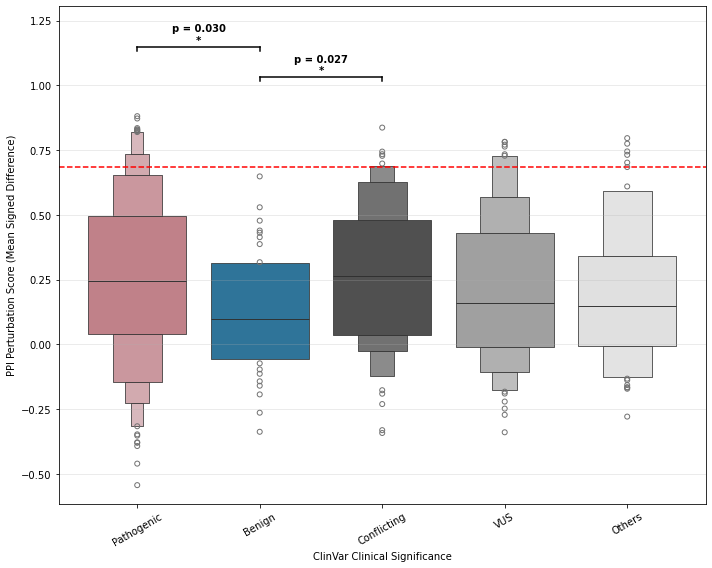


Significant Statistical Test Results (p < 0.05)
Total comparisons: 10
Significant comparisons (unadjusted): 2

Benign vs Conflicting:
  Test: Mann-Whitney U
  Statistic: 915.0000
  P-value: 2.7029e-02
  N1: 31, N2: 81
  Mean1: 0.1339, Mean2: 0.2663
  Median1: 0.0991, Median2: 0.2659
  Mean difference: -0.1323
  Significance: * (significant)

Pathogenic vs Benign:
  Test: Mann-Whitney U
  Statistic: 4671.0000
  P-value: 2.9574e-02
  N1: 243, N2: 31
  Mean1: 0.2572, Mean2: 0.1339
  Median1: 0.2461, Median2: 0.0991
  Mean difference: 0.1232
  Significance: * (significant)


All Statistical Test Results
Total comparisons: 10
Significant comparisons (unadjusted): 2

Benign vs Conflicting:
  Test: Mann-Whitney U
  Statistic: 915.0000
  P-value: 2.7029e-02
  N1: 31, N2: 81
  Mean1: 0.1339, Mean2: 0.2663
  Median1: 0.0991, Median2: 0.2659
  Mean difference: -0.1323
  Significance: * (significant)

Pathogenic vs Benign:
  Test: Mann-Whitney U
  Statistic: 4671.0000
  P-value: 2.9574e-02
  N1: 

In [ ]:
order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

fig, ax = plt.subplots(figsize=(10, 8))

sns.boxenplot(
    data=orf_distances,
    x="clinvar_clnsig_clean",
    y="mean_signed_difference",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
    ax=ax
)

# Test ALL possible combinations and show only significant ones
results = add_statistical_annotations(
    ax=ax,
    data=orf_distances,
    x_col="clinvar_clnsig_clean",
    y_col="mean_signed_difference",
    order=order,
    test='mannwhitneyu',
    comparisons='all_significant',  # This tests all pairs and shows only significant
    alpha=0.05,  # Can adjust significance threshold
    fdr_correction=False,  # Apply FDR correction
)

ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Mean Signed Difference)")
ax.axhline(y=0.686, color='red', linestyle='--', label='LLR Threshold (0.678)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.tight_layout()
plt.show()

# Print only significant results
print_statistical_summary(results, verbose=True, show_all=False)

# Or print all results
print_statistical_summary(results, verbose=True, show_all=True)

### good violin plots

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2783732490.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2783732490.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2783732490.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)


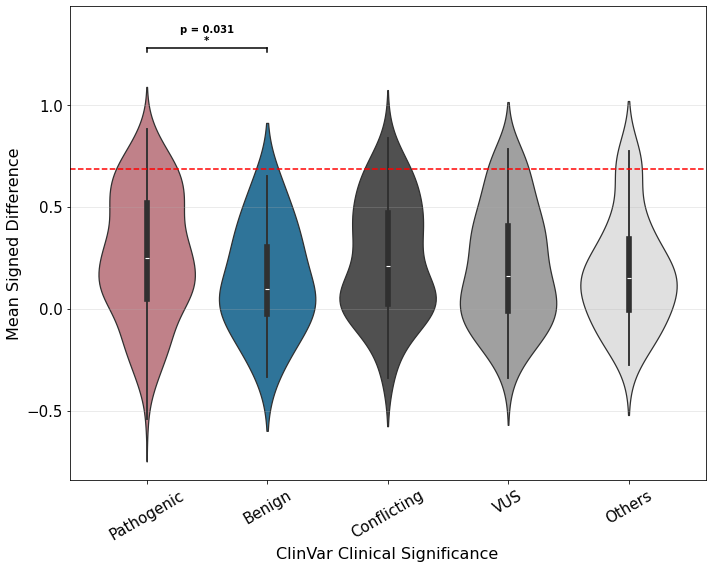


Significant Statistical Test Results (p < 0.05)
Total comparisons: 10
Significant comparisons (unadjusted): 1

Pathogenic vs Benign:
  Test: Mann-Whitney U
  Statistic: 4813.0000
  P-value: 3.1371e-02
  N1: 251, N2: 31
  Mean1: 0.2622, Mean2: 0.1442
  Median1: 0.2461, Median2: 0.0946
  Mean difference: 0.1181
  Significance: * (significant)


All Statistical Test Results
Total comparisons: 10
Significant comparisons (unadjusted): 1

Pathogenic vs Benign:
  Test: Mann-Whitney U
  Statistic: 4813.0000
  P-value: 3.1371e-02
  N1: 251, N2: 31
  Mean1: 0.2622, Mean2: 0.1442
  Median1: 0.2461, Median2: 0.0946
  Mean difference: 0.1181
  Significance: * (significant)

Pathogenic vs Others:
  Test: Mann-Whitney U
  Statistic: 7466.0000
  P-value: 6.1033e-02
  N1: 251, N2: 51
  Mean1: 0.2622, Mean2: 0.1812
  Median1: 0.2461, Median2: 0.1517
  Mean difference: 0.0810
  Significance: ns (not significant)

Benign vs Conflicting:
  Test: Mann-Whitney U
  Statistic: 1035.0000
  P-value: 1.0995e-01


In [569]:
order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

fig, ax = plt.subplots(figsize=(10, 8))

sns.violinplot(
    data=orf_distances,
    x="clinvar_clnsig_clean",
    y="mean_signed_difference",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
    ax=ax
)

# Test ALL possible combinations and show only significant ones
results = add_statistical_annotations(
    ax=ax,
    data=orf_distances,
    x_col="clinvar_clnsig_clean",
    y_col="mean_signed_difference",
    order=order,
    test='mannwhitneyu',
    comparisons='all_significant',  # This tests all pairs and shows only significant
    alpha=0.05,  # Can adjust significance threshold
    fdr_correction=False,  # Apply FDR correction
    y_offset_factor=0.05  # Increase offset for violin plots
)

ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)
ax.set_ylabel("Mean Signed Difference", fontsize=16)
ax.axhline(y=0.686, color='red', linestyle='--', label='LLR Threshold (0.678)')
ax.set_xlabel("ClinVar Clinical Significance", fontsize=16)
plt.tight_layout()
plt.show()

# Print only significant results
print_statistical_summary(results, verbose=True, show_all=False)

# Or print all results
print_statistical_summary(results, verbose=True, show_all=True)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2605072962.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2605072962.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2605072962.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)


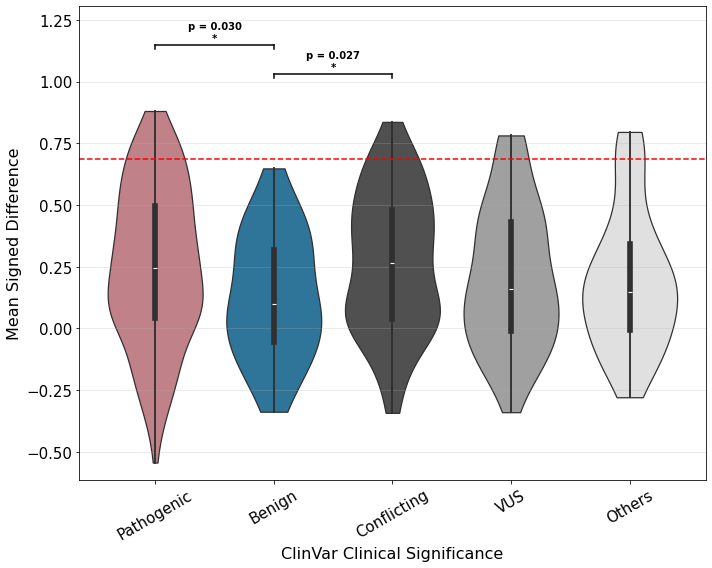


Significant Statistical Test Results (p < 0.05)
Total comparisons: 10
Significant comparisons (unadjusted): 2

Benign vs Conflicting:
  Test: Mann-Whitney U
  Statistic: 915.0000
  P-value: 2.7029e-02
  N1: 31, N2: 81
  Mean1: 0.1339, Mean2: 0.2663
  Median1: 0.0991, Median2: 0.2659
  Mean difference: -0.1323
  Significance: * (significant)

Pathogenic vs Benign:
  Test: Mann-Whitney U
  Statistic: 4671.0000
  P-value: 2.9574e-02
  N1: 243, N2: 31
  Mean1: 0.2572, Mean2: 0.1339
  Median1: 0.2461, Median2: 0.0991
  Mean difference: 0.1232
  Significance: * (significant)


All Statistical Test Results
Total comparisons: 10
Significant comparisons (unadjusted): 2

Benign vs Conflicting:
  Test: Mann-Whitney U
  Statistic: 915.0000
  P-value: 2.7029e-02
  N1: 31, N2: 81
  Mean1: 0.1339, Mean2: 0.2663
  Median1: 0.0991, Median2: 0.2659
  Mean difference: -0.1323
  Significance: * (significant)

Pathogenic vs Benign:
  Test: Mann-Whitney U
  Statistic: 4671.0000
  P-value: 2.9574e-02
  N1: 

In [ ]:
order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

fig, ax = plt.subplots(figsize=(10, 8))

sns.violinplot(
    data=orf_distances,
    x="clinvar_clnsig_clean",
    y="mean_signed_difference",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
    ax=ax,
    cut=0  # Limit violin tails to data range
)

# Test ALL possible combinations and show only significant ones
results = add_statistical_annotations(
    ax=ax,
    data=orf_distances,
    x_col="clinvar_clnsig_clean",
    y_col="mean_signed_difference",
    order=order,
    test='mannwhitneyu',
    comparisons='all_significant',  # This tests all pairs and shows only significant
    alpha=0.05,  # Can adjust significance threshold
    fdr_correction=False,  # Apply FDR correction
    y_offset_factor=0.05  # Increase offset for violin plots
)

ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)
ax.set_ylabel("Mean Signed Difference", fontsize=16)
ax.axhline(y=0.686, color='red', linestyle='--', label='LLR Threshold (0.678)')
ax.set_xlabel("ClinVar Clinical Significance", fontsize=16)
plt.tight_layout()
plt.show()

# Print only significant results
print_statistical_summary(results, verbose=True, show_all=False)

# Or print all results
print_statistical_summary(results, verbose=True, show_all=True)

In [ ]:
for col in orf_distances.columns:
    if 'clinvar' in col:
        print(col)

clinvar_clnsig_clean
clinvar_nt_change
clinvar_aa_change
clinvar_clnsig_clean_right
clinvar_clnsig_clean_pp_strict
clinvar_id
clinvar_trait
clinvar_review
clinvar_hgvs
clinvar_var_source
clinvar_MedGen_id
clinvar_OMIM_id
clinvar_Orphanet_id


In [ ]:
orf_distances.to_pandas().clinvar_clnsig_clean_pp_strict.value_counts()

clinvar_clnsig_clean_pp_strict
Pathogenic           154
Likely pathogenic     89
VUS                   88
Conflicting           81
Others                51
Likely benign         23
Benign                 8
Name: count, dtype: int64

In [ ]:
from scipy import stats as scipy_stats

data1 = orf_distances.filter(pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", 'Likely pathogenic']))["normalized_euclid_distance_normalized"].to_list()
data2 = orf_distances.filter(pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Benign", "Likely benign"]))["normalized_euclid_distance_normalized"].to_list()

statistic, p_value = scipy_stats.mannwhitneyu(data1, data2, alternative='greater')

print(f"Mann-Whitney U test between Pathogenic and Benign:")
print(f"Statistic: {statistic:.4f}, P-value: {p_value:.4e}")

Mann-Whitney U test between Pathogenic and Benign:
Statistic: 4876.0000, P-value: 3.8023e-03


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2585458931.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2585458931.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2585458931.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)


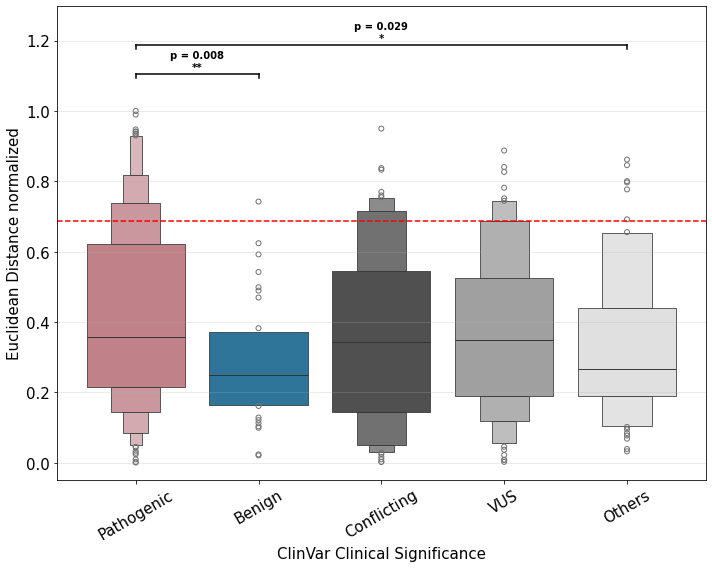

In [571]:
order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

fig, ax = plt.subplots(figsize=(10, 8))

sns.boxenplot(
    data=orf_distances,
    x="clinvar_clnsig_clean",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
    ax=ax
)

# Test ALL possible combinations and show only significant ones
results = add_statistical_annotations(
    ax=ax,
    data=orf_distances,
    x_col="clinvar_clnsig_clean",
    y_col="normalized_euclid_distance_normalized",
    order=order,
    test='mannwhitneyu',
    comparisons='all_significant',  # This tests all pairs and shows only significant
    alpha=0.05,  # Can adjust significance threshold
    fdr_correction=False,  # Apply FDR correction
    y_offset_factor=0.05  # Increase offset for violin plots
)

ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)
ax.set_ylabel("Euclidean Distance normalized", fontsize=15)
ax.axhline(y=0.686, color='red', linestyle='--', label='LLR Threshold (0.678)')
ax.set_xlabel("ClinVar Clinical Significance", fontsize=15)
plt.tight_layout()
plt.show()

# Print only significant results
# print_statistical_summary(results, verbose=True, show_all=False)

# Or print all results
# print_statistical_summary(results, verbose=True, show_all=True)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/680037390.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/680037390.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/680037390.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)


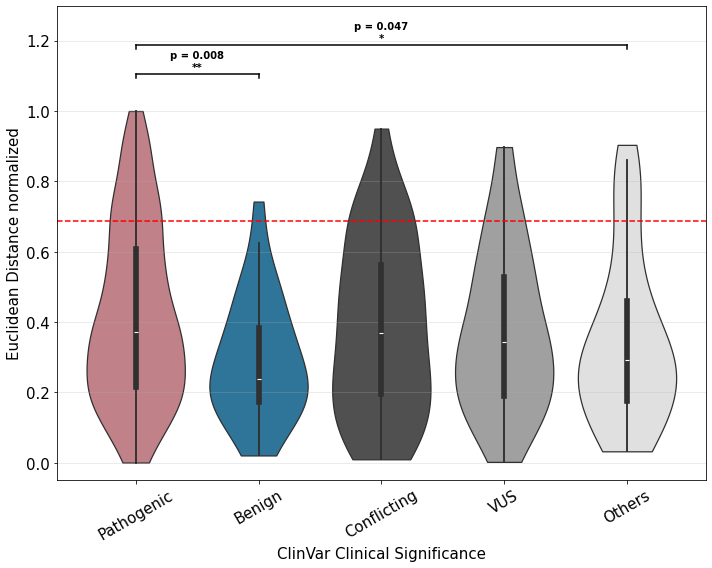


Significant Statistical Test Results (p < 0.05)
Total comparisons: 10
Significant comparisons (unadjusted): 2

Pathogenic vs Benign:
  Test: Mann-Whitney U
  Statistic: 4876.0000
  P-value: 7.6045e-03
  N1: 243, N2: 31
  Mean1: 0.4206, Mean2: 0.2928
  Median1: 0.3727, Median2: 0.2389
  Mean difference: 0.1278
  Significance: ** (very significant)

Pathogenic vs Others:
  Test: Mann-Whitney U
  Statistic: 7293.0000
  P-value: 4.7073e-02
  N1: 243, N2: 51
  Mean1: 0.4206, Mean2: 0.3483
  Median1: 0.3727, Median2: 0.2922
  Mean difference: 0.0723
  Significance: * (significant)


All Statistical Test Results
Total comparisons: 10
Significant comparisons (unadjusted): 2

Pathogenic vs Benign:
  Test: Mann-Whitney U
  Statistic: 4876.0000
  P-value: 7.6045e-03
  N1: 243, N2: 31
  Mean1: 0.4206, Mean2: 0.2928
  Median1: 0.3727, Median2: 0.2389
  Mean difference: 0.1278
  Significance: ** (very significant)

Pathogenic vs Others:
  Test: Mann-Whitney U
  Statistic: 7293.0000
  P-value: 4.707

In [ ]:
order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

fig, ax = plt.subplots(figsize=(10, 8))

sns.violinplot(
    data=orf_distances,
    x="clinvar_clnsig_clean",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
    ax=ax,
    cut=0  # Limit violin tails to data range
)

# Test ALL possible combinations and show only significant ones
results = add_statistical_annotations(
    ax=ax,
    data=orf_distances,
    x_col="clinvar_clnsig_clean",
    y_col="normalized_euclid_distance_normalized",
    order=order,
    test='mannwhitneyu',
    comparisons='all_significant',  # This tests all pairs and shows only significant
    alpha=0.05,  # Can adjust significance threshold
    fdr_correction=False,  # Apply FDR correction
    y_offset_factor=0.05  # Increase offset for violin plots
)

ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)
ax.set_ylabel("Euclidean Distance normalized", fontsize=15)
ax.axhline(y=0.686, color='red', linestyle='--', label='LLR Threshold (0.678)')
ax.set_xlabel("ClinVar Clinical Significance", fontsize=15)
plt.tight_layout()
plt.show()

# Print only significant results
print_statistical_summary(results, verbose=True, show_all=False)

# Or print all results
print_statistical_summary(results, verbose=True, show_all=True)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/4058098493.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/4058098493.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/4058098493.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)


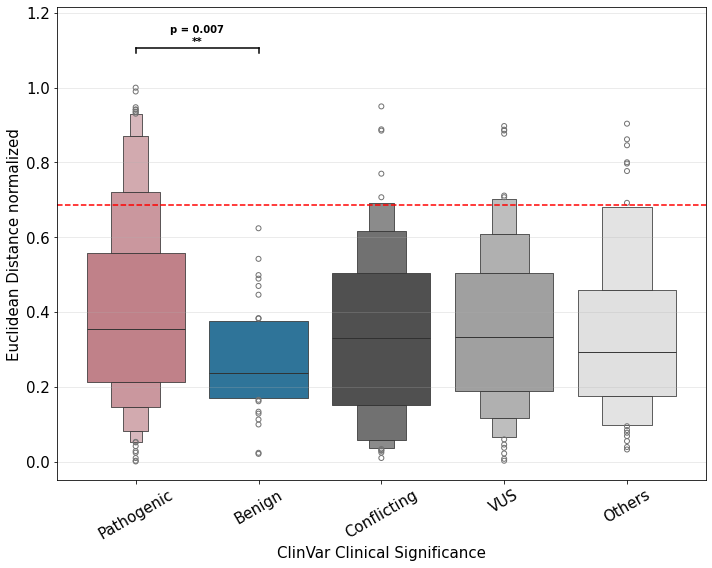


Significant Statistical Test Results (p < 0.05)
Total comparisons: 10
Significant comparisons (unadjusted): 1

Pathogenic vs Benign:
  Test: Mann-Whitney U
  Statistic: 4507.0000
  P-value: 7.4170e-03
  N1: 231, N2: 30
  Mean1: 0.4066, Mean2: 0.2778
  Median1: 0.3557, Median2: 0.2378
  Mean difference: 0.1289
  Significance: ** (very significant)


All Statistical Test Results
Total comparisons: 10
Significant comparisons (unadjusted): 1

Pathogenic vs Benign:
  Test: Mann-Whitney U
  Statistic: 4507.0000
  P-value: 7.4170e-03
  N1: 231, N2: 30
  Mean1: 0.4066, Mean2: 0.2778
  Median1: 0.3557, Median2: 0.2378
  Mean difference: 0.1289
  Significance: ** (very significant)

Pathogenic vs Conflicting:
  Test: Mann-Whitney U
  Statistic: 9424.0000
  P-value: 8.7974e-02
  N1: 231, N2: 72
  Mean1: 0.4066, Mean2: 0.3464
  Median1: 0.3557, Median2: 0.3303
  Mean difference: 0.0603
  Significance: ns (not significant)

Pathogenic vs Others:
  Test: Mann-Whitney U
  Statistic: 6789.0000
  P-va

In [ ]:
order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

orf_no_kc = orf_distances.filter(pl.col("symbol") != 'KCNJ2')

fig, ax = plt.subplots(figsize=(10, 8))

sns.boxenplot(
    data=orf_no_kc,
    x="clinvar_clnsig_clean",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
    ax=ax
)

# Test ALL possible combinations and show only significant ones
results = add_statistical_annotations(
    ax=ax,
    data=orf_no_kc,
    x_col="clinvar_clnsig_clean",
    y_col="normalized_euclid_distance_normalized",
    order=order,
    test='mannwhitneyu',
    comparisons='all_significant',  # This tests all pairs and shows only significant
    alpha=0.05,  # Can adjust significance threshold
    fdr_correction=False,  # Apply FDR correction
    y_offset_factor=0.05  # Increase offset for violin plots
)

ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)
ax.set_ylabel("Euclidean Distance normalized", fontsize=15)
ax.axhline(y=0.686, color='red', linestyle='--', label='LLR Threshold (0.678)')
ax.set_xlabel("ClinVar Clinical Significance", fontsize=15)
plt.tight_layout()
plt.show()

# Print only significant results
print_statistical_summary(results, verbose=True, show_all=False)

# Or print all results
print_statistical_summary(results, verbose=True, show_all=True)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/4266535147.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/4266535147.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/4266535147.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)


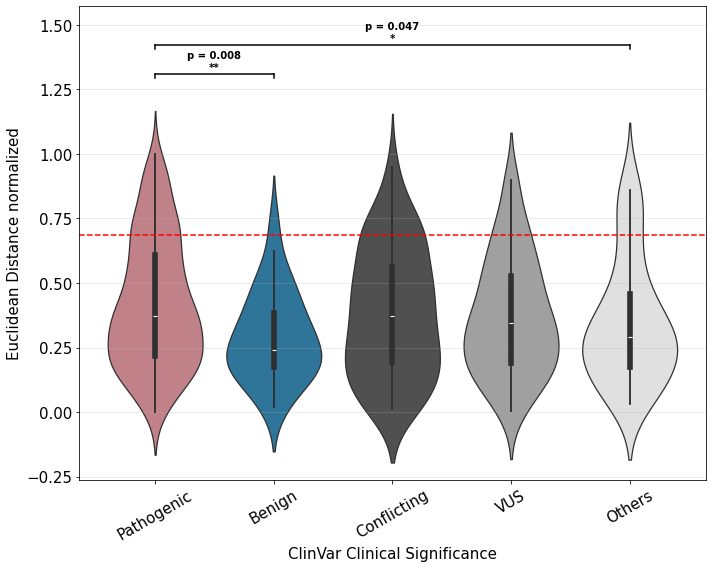


Significant Statistical Test Results (p < 0.05)
Total comparisons: 10
Significant comparisons (unadjusted): 2

Pathogenic vs Benign:
  Test: Mann-Whitney U
  Statistic: 4876.0000
  P-value: 7.6045e-03
  N1: 243, N2: 31
  Mean1: 0.4206, Mean2: 0.2928
  Median1: 0.3727, Median2: 0.2389
  Mean difference: 0.1278
  Significance: ** (very significant)

Pathogenic vs Others:
  Test: Mann-Whitney U
  Statistic: 7293.0000
  P-value: 4.7073e-02
  N1: 243, N2: 51
  Mean1: 0.4206, Mean2: 0.3483
  Median1: 0.3727, Median2: 0.2922
  Mean difference: 0.0723
  Significance: * (significant)


All Statistical Test Results
Total comparisons: 10
Significant comparisons (unadjusted): 2

Pathogenic vs Benign:
  Test: Mann-Whitney U
  Statistic: 4876.0000
  P-value: 7.6045e-03
  N1: 243, N2: 31
  Mean1: 0.4206, Mean2: 0.2928
  Median1: 0.3727, Median2: 0.2389
  Mean difference: 0.1278
  Significance: ** (very significant)

Pathogenic vs Others:
  Test: Mann-Whitney U
  Statistic: 7293.0000
  P-value: 4.707

In [ ]:
order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

fig, ax = plt.subplots(figsize=(10, 8))

sns.violinplot(
    data=orf_distances,
    x="clinvar_clnsig_clean",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
    ax=ax
)

# Test ALL possible combinations and show only significant ones
results = add_statistical_annotations(
    ax=ax,
    data=orf_distances,
    x_col="clinvar_clnsig_clean",
    y_col="normalized_euclid_distance_normalized",
    order=order,
    test='mannwhitneyu',
    comparisons='all_significant',  # This tests all pairs and shows only significant
    alpha=0.05,  # Can adjust significance threshold
    fdr_correction=False,  # Apply FDR correction
    y_offset_factor=0.05  # Increase offset for violin plots
)

ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, fontsize=15)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=15)
ax.set_ylabel("Euclidean Distance normalized", fontsize=15)
ax.axhline(y=0.686, color='red', linestyle='--', label='LLR Threshold (0.678)')
ax.set_xlabel("ClinVar Clinical Significance", fontsize=15)
plt.tight_layout()
plt.show()

# Print only significant results
print_statistical_summary(results, verbose=True, show_all=False)

# Or print all results
print_statistical_summary(results, verbose=True, show_all=True)

### auroc comparison

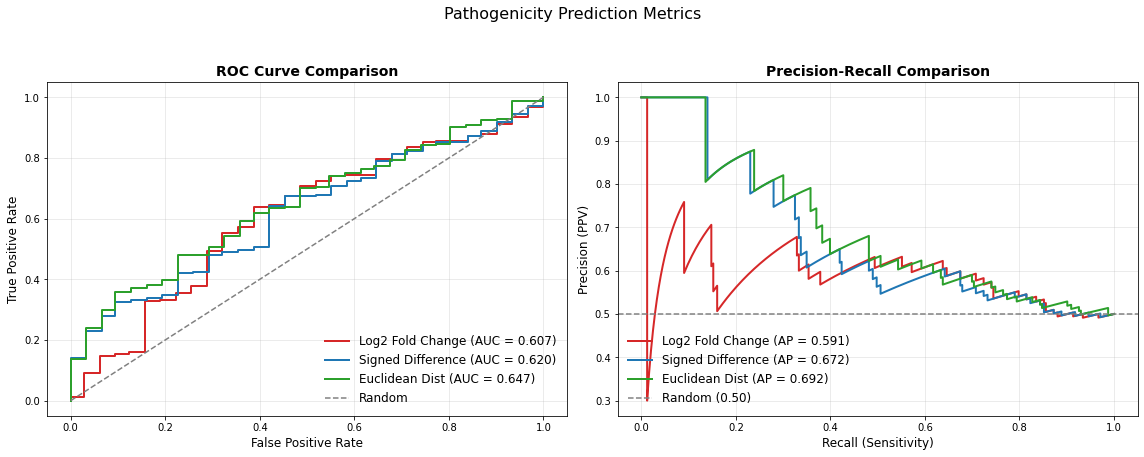

              Metric     AUROC     AUPRC
0   Log2 Fold Change  0.607377  0.590713
1  Signed Difference  0.619655  0.671670
2     Euclidean Dist  0.647395  0.692174


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

def compare_classification_metrics(scores_df, metrics_dict, title=None, filter_edges=None, 
                                   verbose=False, balance_dataset=False,
                                   clinvar_col='clinvar_clnsig_clean'):
    """
    Compare AUROC and AUPRC for multiple metrics on the same plot.
    Assumes all metrics are already oriented such that Higher Score = Pathogenic.
    
    Parameters:
    -----------
    scores_df : polars.DataFrame or pandas.DataFrame
        DataFrame containing scores and clinical significance
    metrics_dict : dict
        Dictionary of {column_name: 'Display Label'} to compare.
    """
    
    # 1. SETUP CATEGORIES
    if clinvar_col == "clinvar_clnsig_clean_pp_strict":
        pathogenic_categories = ['Pathogenic', 'Likely pathogenic']
        benign_categories = ['Benign', 'Likely benign']
    else:
        pathogenic_categories = ['Pathogenic']
        benign_categories = ['Benign']
    
    # 2. PRE-PROCESS DATA
    try:
        df = scores_df.to_pandas()
    except:
        df = scores_df.copy()
        
    # Filter edges if requested
    if filter_edges is not None and 'num_edges' in df.columns:
        df = df[df['num_edges'] >= filter_edges]
    
    # Filter ClinVar
    all_categories = pathogenic_categories + benign_categories
    filtered = df[df[clinvar_col].isin(all_categories)].copy()
    
    # Drop rows where ANY of the target metrics are NaN (for fair comparison)
    metric_cols = list(metrics_dict.keys())
    filtered = filtered.dropna(subset=metric_cols)
    
    if len(filtered) < 10:
        print(f"Warning: Only {len(filtered)} variants available. Aborting.")
        return None
        
    # Balance Dataset logic (Same as before)
    if balance_dataset:
        n_path = filtered[clinvar_col].isin(pathogenic_categories).sum()
        n_ben = filtered[clinvar_col].isin(benign_categories).sum()
        
        if n_path > n_ben:
            benign = filtered[filtered[clinvar_col].isin(benign_categories)]
            path = filtered[filtered[clinvar_col].isin(pathogenic_categories)]
            balanced_benign = pd.concat([benign] * (n_path // n_ben) + 
                                      [benign.sample(n=n_path % n_ben, random_state=42)], ignore_index=True)
            filtered = pd.concat([path, balanced_benign], ignore_index=True)
        elif n_ben > n_path:
            benign = filtered[filtered[clinvar_col].isin(benign_categories)]
            path = filtered[filtered[clinvar_col].isin(pathogenic_categories)]
            balanced_path = pd.concat([path] * (n_ben // n_path) + 
                                    [path.sample(n=n_ben % n_path, random_state=42)], ignore_index=True)
            filtered = pd.concat([benign, balanced_path], ignore_index=True)
            
    # 3. PLOTTING SETUP
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    colors = ['#d62728', '#1f77b4', '#2ca02c', '#ff7f0e', '#9467bd'] # Red, Blue, Green, Orange, Purple
    
    y_true = filtered[clinvar_col].isin(pathogenic_categories).astype(int)
    results_summary = []
    
    # 4. LOOP THROUGH METRICS
    for i, (col, label) in enumerate(metrics_dict.items()):
        scores = filtered[col].values
        
        # ROC
        fpr, tpr, _ = roc_curve(y_true, scores)
        roc_auc = auc(fpr, tpr)
        
        # PR
        precision, recall, _ = precision_recall_curve(y_true, scores)
        auprc = average_precision_score(y_true, scores)
        
        # Plot ROC
        axes[0].plot(fpr, tpr, lw=2, color=colors[i % len(colors)],
                    label=f'{label} (AUC = {roc_auc:.3f})')
        
        # Plot PR
        axes[1].plot(recall, precision, lw=2, color=colors[i % len(colors)],
                    label=f'{label} (AP = {auprc:.3f})')
        
        results_summary.append({'Metric': label, 'AUROC': roc_auc, 'AUPRC': auprc})

    # 5. FINALIZE PLOTS
    # ROC
    axes[0].plot([0, 1], [0, 1], color='grey', lw=1.5, linestyle='--', label='Random')
    axes[0].set_xlabel('False Positive Rate', fontsize=12)
    axes[0].set_ylabel('True Positive Rate', fontsize=12)
    axes[0].set_title('ROC Curve Comparison', fontsize=14, fontweight='bold')
    axes[0].legend(loc="lower right", frameon=False, fontsize=12)
    axes[0].grid(alpha=0.3)
    
    # PR
    baseline = y_true.mean()
    axes[1].axhline(y=baseline, color='grey', lw=1.5, linestyle='--', label=f'Random ({baseline:.2f})')
    axes[1].set_xlabel('Recall (Sensitivity)', fontsize=12)
    axes[1].set_ylabel('Precision (PPV)', fontsize=12)
    axes[1].set_title('Precision-Recall Comparison', fontsize=14, fontweight='bold')
    axes[1].legend(loc="lower left", frameon=False, fontsize=12)
    axes[1].grid(alpha=0.3)
    
    if title:
        fig.suptitle(title, fontsize=16, y=1.05)
    
    plt.tight_layout()
    plt.show()
    
    return pd.DataFrame(results_summary)

# --- Usage Example ---
metrics_to_plot = {
    'mean_log2fc': 'Log2 Fold Change',
    'mean_signed_difference': 'Signed Difference', 
    'normalized_euclid_distance': 'Euclidean Dist'
}
summary_df = compare_classification_metrics(orf_distances, metrics_to_plot, 
                                            title="Pathogenicity Prediction Metrics",
                                            balance_dataset=True)
print(summary_df)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3213317409.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3213317409.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


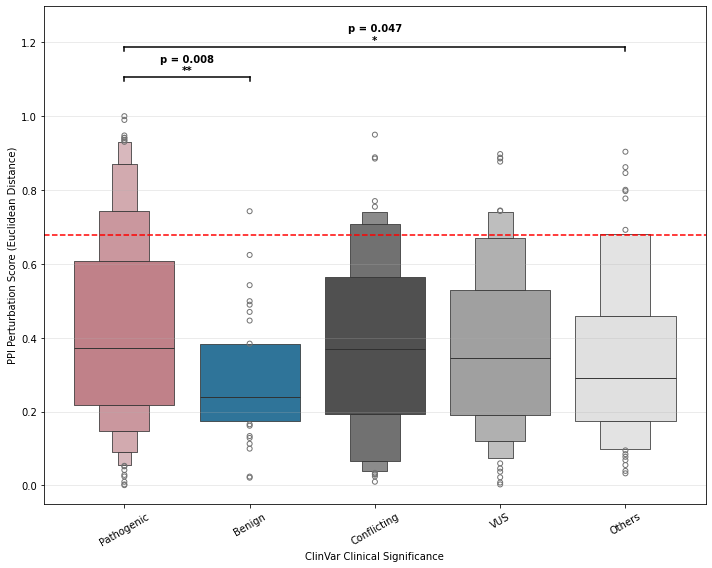


Significant Statistical Test Results (p < 0.05)
Total comparisons: 10
Significant comparisons (unadjusted): 2

Pathogenic vs Benign:
  Test: Mann-Whitney U
  Statistic: 4876.0000
  P-value: 7.6045e-03
  N1: 243, N2: 31
  Mean1: 0.4206, Mean2: 0.2928
  Median1: 0.3727, Median2: 0.2389
  Mean difference: 0.1278
  Significance: ** (very significant)

Pathogenic vs Others:
  Test: Mann-Whitney U
  Statistic: 7293.0000
  P-value: 4.7073e-02
  N1: 243, N2: 51
  Mean1: 0.4206, Mean2: 0.3483
  Median1: 0.3727, Median2: 0.2922
  Mean difference: 0.0723
  Significance: * (significant)


All Statistical Test Results
Total comparisons: 10
Significant comparisons (unadjusted): 2

Pathogenic vs Benign:
  Test: Mann-Whitney U
  Statistic: 4876.0000
  P-value: 7.6045e-03
  N1: 243, N2: 31
  Mean1: 0.4206, Mean2: 0.2928
  Median1: 0.3727, Median2: 0.2389
  Mean difference: 0.1278
  Significance: ** (very significant)

Pathogenic vs Others:
  Test: Mann-Whitney U
  Statistic: 7293.0000
  P-value: 4.707

In [ ]:
order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

fig, ax = plt.subplots(figsize=(10, 8))

sns.boxenplot(
    data=orf_distances,
    x="clinvar_clnsig_clean",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
    ax=ax
)

# Test ALL possible combinations and show only significant ones
results = add_statistical_annotations(
    ax=ax,
    data=orf_distances,
    x_col="clinvar_clnsig_clean",
    y_col="normalized_euclid_distance_normalized",
    order=order,
    test='mannwhitneyu',
    comparisons='all_significant',  # This tests all pairs and shows only significant
    alpha=0.05,  # Can adjust significance threshold
    fdr_correction=False,  # Apply FDR correction
)

ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.678)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.tight_layout()
plt.show()

# Print only significant results
print_statistical_summary(results, verbose=True, show_all=False)

# Or print all results
print_statistical_summary(results, verbose=True, show_all=True)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/463325278.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(


No significant comparisons found at alpha=0.05 (FDR-corrected)


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/463325278.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


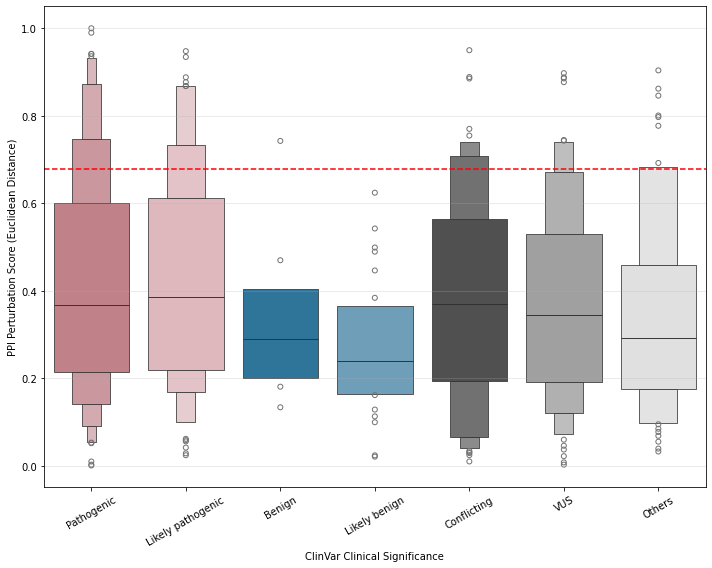


No significant results to display (FDR-corrected)

All Statistical Test Results
Total comparisons: 21
Significant comparisons (FDR): 0
Significant comparisons (unadjusted): 2

Pathogenic vs Likely benign:
  Test: Mann-Whitney U
  Statistic: 2328.0000
  P-value: 1.5189e-02
  P-value (FDR-adjusted): 1.5948e-01
  Reject null (FDR): False
  N1: 154, N2: 23
  Mean1: 0.4184, Mean2: 0.2774
  Median1: 0.3683, Median2: 0.2389
  Mean difference: 0.1410
  Significance: ns (not significant)

Likely pathogenic vs Likely benign:
  Test: Mann-Whitney U
  Statistic: 1394.0000
  P-value: 7.6993e-03
  P-value (FDR-adjusted): 1.5948e-01
  Reject null (FDR): False
  N1: 89, N2: 23
  Mean1: 0.4243, Mean2: 0.2774
  Median1: 0.3864, Median2: 0.2389
  Mean difference: 0.1469
  Significance: ns (not significant)

Pathogenic vs Others:
  Test: Mann-Whitney U
  Statistic: 4573.0000
  P-value: 7.8755e-02
  P-value (FDR-adjusted): 2.8943e-01
  Reject null (FDR): False
  N1: 154, N2: 51
  Mean1: 0.4184, Mean2: 0.3

In [ ]:
order = ["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]

fig, ax = plt.subplots(figsize=(10, 8))

sns.boxenplot(
    data=orf_distances,
    x="clinvar_clnsig_clean_pp_strict",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
    ax=ax
)

# Test ALL possible combinations and show only significant ones
results = add_statistical_annotations(
    ax=ax,
    data=orf_distances,
    x_col="clinvar_clnsig_clean_pp_strict",
    y_col="normalized_euclid_distance_normalized",
    order=order,
    test='mannwhitneyu',
    comparisons='all_significant',  # This tests all pairs and shows only significant
    alpha=0.05  # Can adjust significance threshold
)

ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.678)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.tight_layout()
plt.show()

# Print only significant results
print_statistical_summary(results, verbose=True, show_all=False)

# Or print all results
print_statistical_summary(results, verbose=True, show_all=True)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1893048866.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1893048866.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


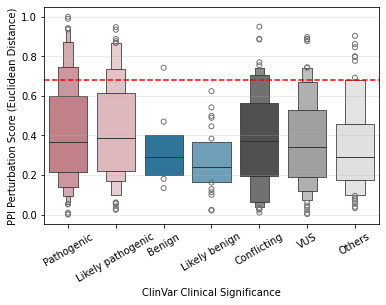

In [ ]:

order = ["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]

ax = sns.boxenplot(
    data=orf_distances,
    x="clinvar_clnsig_clean_pp_strict",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
plt.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.620)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2349656510.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2349656510.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


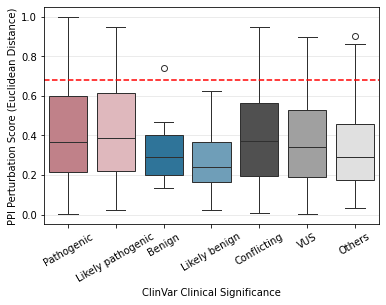

In [ ]:

order = ["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]

ax = sns.boxplot(
    data=orf_distances,
    x="clinvar_clnsig_clean_pp_strict",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
plt.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.620)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3175448014.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3175448014.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


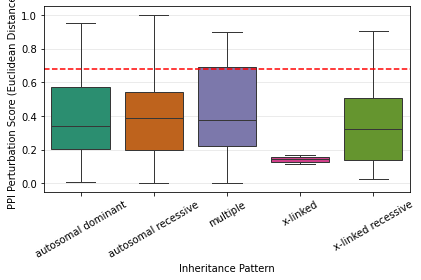

In [ ]:

# First check if inheritance_pattern column exists
if "inheritance_pattern" in orf_distances.columns:
    order = ['autosomal dominant', 'autosomal recessive', 'multiple', 'x-linked', 'x-linked recessive']
    # Get unique inheritance patterns
    inheritance_order = orf_distances.select("inheritance_pattern").unique().to_series().sort().to_list()
    
    ax = sns.boxplot(
        data=orf_distances,
        x="inheritance_pattern",
        y="normalized_euclid_distance_normalized",
        order=order,
        palette='Dark2',
    )
    ax.grid(alpha=0.3, axis='y')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
    ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
    plt.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.678)')
    ax.set_xlabel("Inheritance Pattern")
    # plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Column 'inheritance_pattern' not found in orf_distances")
    print("Available columns:", orf_distances.columns)


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2915675403.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2915675403.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


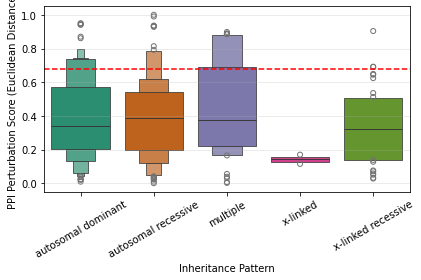

In [ ]:

# First check if inheritance_pattern column exists
if "inheritance_pattern" in orf_distances.columns:
    order = ['autosomal dominant', 'autosomal recessive', 'multiple', 'x-linked', 'x-linked recessive']
    # Get unique inheritance patterns
    inheritance_order = orf_distances.select("inheritance_pattern").unique().to_series().sort().to_list()
    
    ax = sns.boxenplot(
        data=orf_distances,
        x="inheritance_pattern",
        y="normalized_euclid_distance_normalized",
        order=order,
        palette='Dark2',
    )
    ax.grid(alpha=0.3, axis='y')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
    ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
    plt.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.678)')
    ax.set_xlabel("Inheritance Pattern")
    # plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Column 'inheritance_pattern' not found in orf_distances")
    print("Available columns:", orf_distances.columns)


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3966634490.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3966634490.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


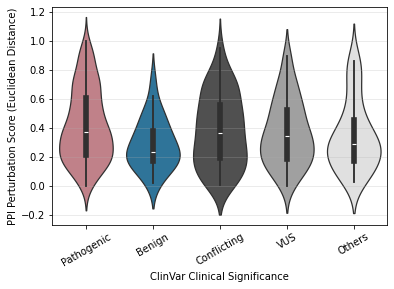

In [ ]:
order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

ax = sns.violinplot(
    data=orf_distances,
    x="clinvar_clnsig_clean",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/814735304.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/814735304.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


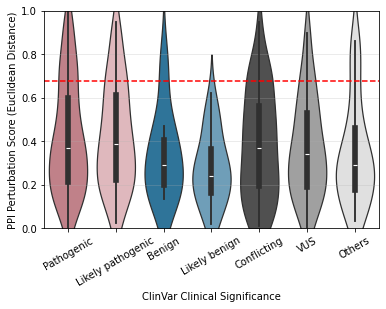

In [ ]:
order = ["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]

ax = sns.violinplot(
    data=orf_distances,
    x="clinvar_clnsig_clean_pp_strict",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.678)')
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.set_xlabel("ClinVar Clinical Significance")
plt.ylim(0, 1)
plt.show()


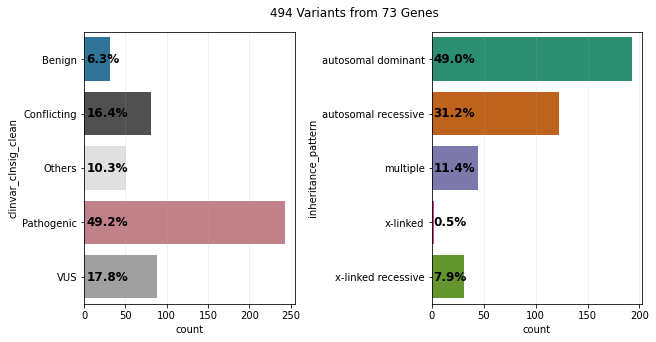

In [ ]:
orf_pd = orf_distances.to_pandas()

original_df = pl.DataFrame(orf_pd)

plot_df = orf_pd[orf_pd.clinvar_clnsig_clean.isin(['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others'])]


scores_dedup_pl = pl.DataFrame(plot_df)


fig, axes = plt.subplots(1,2,figsize=(10,5))
plot_cat_count_perc(
    scores_dedup_pl,
    "clinvar_clnsig_clean",
    title="ClinVar",
    ax=axes[0],
    palette=palette_dict["clinvar_clnsig_clean"]
)
plot_df = plot_df[plot_df.inheritance_pattern.isin(['autosomal dominant', 'autosomal recessive', 'multiple', 'x-linked', 'x-linked recessive'])]

scores_dedup_pl = pl.DataFrame(plot_df)
plot_cat_count_perc(
    scores_dedup_pl,
    "inheritance_pattern",
    title="Inheritance",
    ax=axes[1],
)

plt.suptitle(f"{original_df.unique('gene_variant').shape[0]} Variants from {original_df.unique('symbol').shape[0]} Genes", y=.95)
plt.subplots_adjust(wspace=.65)
plt.show()

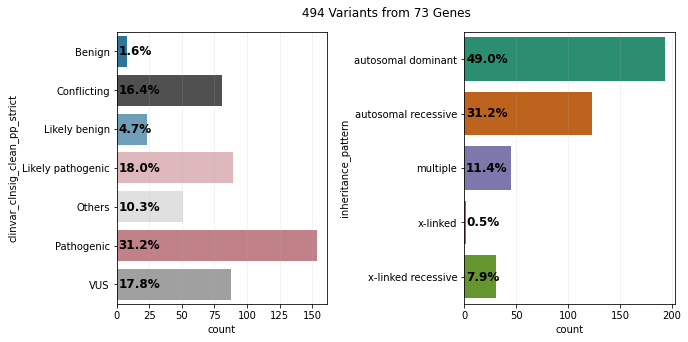

In [ ]:
orf_pd = orf_distances.to_pandas()

original_df = pl.DataFrame(orf_pd)

plot_df = orf_pd[orf_pd.clinvar_clnsig_clean_pp_strict.isin(["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"])]


scores_dedup_pl = pl.DataFrame(plot_df)


fig, axes = plt.subplots(1,2,figsize=(10,5))
plot_cat_count_perc(
    scores_dedup_pl,
    "clinvar_clnsig_clean_pp_strict",
    title="ClinVar",
    ax=axes[0],
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"]
)
plot_df = plot_df[plot_df.inheritance_pattern.isin(['autosomal dominant', 'autosomal recessive', 'multiple', 'x-linked', 'x-linked recessive'])]

scores_dedup_pl = pl.DataFrame(plot_df)
plot_cat_count_perc(
    scores_dedup_pl,
    "inheritance_pattern",
    title="Inheritance",
    ax=axes[1],
)

plt.suptitle(f"{original_df.unique('gene_variant').shape[0]} Variants from {original_df.unique('symbol').shape[0]} Genes", y=.95)
plt.subplots_adjust(wspace=.65)
plt.show()

## hit rates

In [ ]:
def plot_assay_hit_by_category(df, hit_col, cat_cols, title="", ax=None, palette_dict=None, xlim=None, order=None):
    """
    plot_assay_hit_by_category
    ==========================
    
    Create a horizontal bar chart showing the hit rate percentage for each
    category in `cat_cols`, colored according to a palette.
    
    Parameters
    ----------
    df : polars.DataFrame
        Input table containing at least the columns listed in `cat_cols` and a
        boolean column indicating hits.
    hit_col : str
        Name of the boolean column that flags hits (e.g. `"ppi_hit"`).
    cat_cols : str or list[str]
        Column(s) that define the categorical grouping(s).  If a single string is
        supplied it is handled automatically.
    title : str, optional
        Title placed above the plot.
    ax : matplotlib.axes.Axes, optional
        Pre-existing axes to draw on.  If None, a new figure and axes are created.
    palette_dict : dict, optional
        Dictionary mapping category values to colors. If None, uses default colors.
        For inheritance_pattern, uses seaborn 'Dark2' palette automatically.
    xlim : tuple, optional
        X-axis limits. If None, uses (0, 100) by default.
    order : list, optional
        Order of categories for plotting. If None, uses default sorting.
    
    Returns
    -------
    polars.DataFrame
        A tidy frame with one row per category, containing:
            - the grouping key(s)
            - total_counts   : total observations in that category
            - hit_counts     : observations that were hits
            - hit_perc       : hit rate in percent (hit_counts / total_counts * 100)
    
    Example
    -------
    >>> plot_assay_hit_by_category(
    ...     df=my_data,
    ...     hit_col="ppi_hit",
    ...     cat_cols="clinvar_clnsig_clean_pp_strict",
    ...     title="Hit rate by ClinVar significance",
    ...     palette_dict=palette_dict["clinvar_clnsig_clean_pp_strict"],
    ...     order=["Benign", "Likely benign", "VUS", "Conflicting", "Likely pathogenic", "Pathogenic"]
    ... )
    """
    # --- compute hit counts and percentages ---
    df_tot_cnt_per_cat = (
        df.group_by(cat_cols)
        .len()
        .rename({"len": "total_counts"})
    )
    df_hit_cnt_per_cat = (
        df.unique("gene_variant")
        .filter(pl.col(hit_col))
        .group_by(cat_cols)
        .len()
        .rename({"len": "hit_counts"})
    )

    img_hits_perc_df = (
        df_tot_cnt_per_cat.join(
            df_hit_cnt_per_cat,
            on=cat_cols,
            how="left"
        )
        .fill_null(0)
        .with_columns(
            (pl.col("hit_counts") / pl.col("total_counts") * 100).alias("hit_perc")
        )
        .sort(cat_cols)
    )

    # --- plotting ---
    if ax is None:
        _, ax = plt.subplots(1, 1, figsize=(8, max(4, img_hits_perc_df.shape[0] * 0.5)))

    plot_df = img_hits_perc_df.to_pandas()
    
    # Get category column name
    cat_col_name = cat_cols if isinstance(cat_cols, str) else cat_cols[-1]
    
    # Apply custom order if provided
    if order is not None:
        # Filter to only include categories that are in the order list
        plot_df = plot_df[plot_df[cat_col_name].isin(order)]
        # Convert to categorical with specified order
        plot_df[cat_col_name] = pd.Categorical(plot_df[cat_col_name], categories=order, ordered=True)
        plot_df = plot_df.sort_values(cat_col_name, ascending=False).reset_index(drop=True)
    
    # Create color list based on category type
    if cat_cols == 'inheritance_pattern':
        # Use seaborn Dark2 palette for inheritance patterns
        n_categories = len(plot_df[cat_col_name].unique())
        colors = sns.color_palette('Dark2', n_categories)[::-1]
    elif palette_dict is not None:
        # Use provided palette dictionary
        colors = [palette_dict.get(cat, '#808080') for cat in plot_df[cat_col_name]]
    else:
        # Default colors
        colors = None

    # Hit rate bars (colored by category)
    ax.barh(
        y=plot_df[cat_col_name].astype(str),  # Convert to string to avoid categorical issues
        width=plot_df["hit_perc"],
        color=colors
    )

    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel("Hit Rate (%)", fontsize=12)
    ax.set_ylabel("")
    ax.grid(alpha=.2, axis='x')
    
    # Set x-axis limits
    if xlim is not None:
        ax.set_xlim(xlim)
    else:
        ax.set_xlim(0, 100)

    # Percentage annotations
    for idx, row in plot_df.iterrows():
        ax.text(
            row['hit_perc'] + 1,
            idx,
            f"{row['hit_perc']:.1f}% ({int(row['hit_counts'])}/{int(row['total_counts'])})",
            va="center",
            ha="left",
            fontweight="bold",
            fontsize=10,
            color="black"
        )

    plt.tight_layout()
    return img_hits_perc_df

clinvar_clnsig_clean,total_counts,hit_counts,hit_perc
str,u32,u32,f64
"""Benign""",31,1,3.225806
"""Conflicting""",81,13,16.049383
"""Others""",51,7,13.72549
"""Pathogenic""",243,50,20.576132
"""VUS""",88,11,12.5


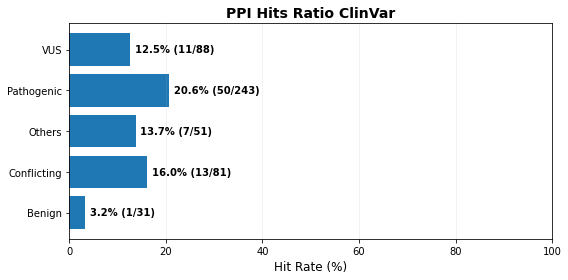

In [ ]:
scores_dedup_with_gene_variant = orf_distances.filter(
    pl.col("clinvar_clnsig_clean").is_in(['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others']) #pl.col("Gene")!="BRCA1" #
)

plot_assay_hit_by_category(scores_dedup_with_gene_variant, "ppi_hit", "clinvar_clnsig_clean", f"PPI Hits Ratio ClinVar")

clinvar_clnsig_clean_pp_strict,total_counts,hit_counts,hit_perc
str,u32,u32,f64
"""Benign""",8,1,12.5
"""Conflicting""",81,13,16.049383
"""Likely benign""",23,0,0.0
"""Likely pathogenic""",89,18,20.224719
"""Others""",51,7,13.72549
"""Pathogenic""",154,32,20.779221
"""VUS""",88,11,12.5


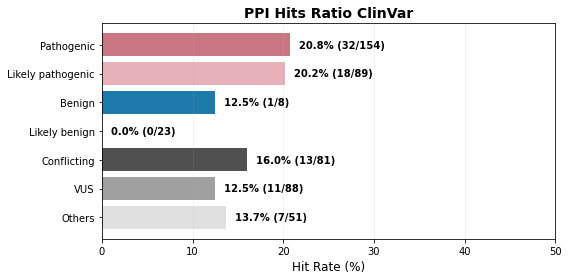

In [ ]:
scores_dedup_with_gene_variant = orf_distances.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]) #pl.col("Gene")!="BRCA1" #
)

plot_assay_hit_by_category(scores_dedup_with_gene_variant,
                           "ppi_hit", 
                           "clinvar_clnsig_clean_pp_strict", 
                           f"PPI Hits Ratio ClinVar", 
                           xlim=(0,50),
                           order=["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"],
                           palette_dict=palette_dict["clinvar_clnsig_clean_pp_strict"])

inheritance_pattern,total_counts,hit_counts,hit_perc
str,u32,u32,f64
"""autosomal dominant""",193,37,19.170984
"""autosomal recessive""",123,12,9.756098
"""multiple""",45,13,28.888889
"""x-linked""",2,0,0.0
"""x-linked dominant""",5,0,0.0
"""x-linked recessive""",31,3,9.677419


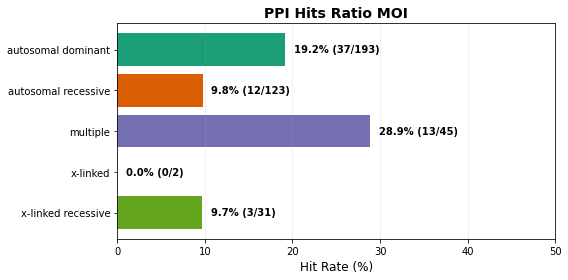

In [ ]:
plot_df = orf_distances.filter(
    (pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"])) &
    (pl.col('inheritance_pattern').is_not_null())
)

plot_assay_hit_by_category(plot_df, 
                           "ppi_hit", 
                           "inheritance_pattern", 
                           f"PPI Hits Ratio MOI", 
                           xlim=(0,50),
                           order=['autosomal dominant', 'autosomal recessive', 'multiple', 'x-linked', 'x-linked recessive']
                           )

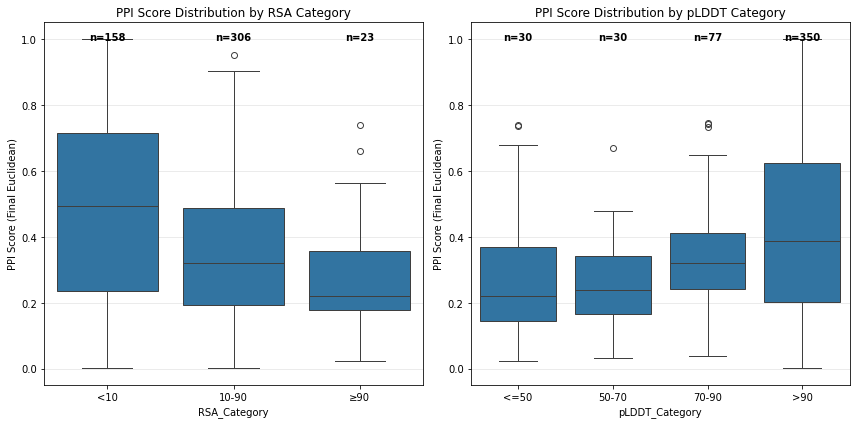

RSA Category Summary:
              count   mean  median    std
RSA_Category                             
<10             158  0.491   0.493  0.279
10-90           306  0.347   0.321  0.206
≥90              23  0.285   0.219  0.183

pLDDT Category Summary:
                count   mean  median    std
pLDDT_Category                             
<=50               30  0.290   0.219  0.210
50-70              30  0.251   0.238  0.142
70-90              77  0.342   0.321  0.151
>90               350  0.422   0.388  0.258


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1429374680.py:51: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rsa_summary = rsa_data.groupby('RSA_Category')['normalized_euclid_distance_normalized'].agg(['count', 'mean', 'median', 'std']).round(3)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1429374680.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  plddt_summary = plddt_data.groupby('pLDDT_Category')['normalized_euclid_distance_normalized'].agg(['count', 'mean', 'median', 'std']).round(3)


In [ ]:
# Set the proper order for both RSA and pLDDT categories
rsa_order = ['<10', '10-90', '≥90']
plddt_order = ["<=50", "50-70", "70-90", ">90"]

# First convert to pandas to set the categorical order, then back to polars
all_variants_df_ppi_pd = orf_distances.to_pandas()

# Set categorical order for both RSA and pLDDT
all_variants_df_ppi_pd['RSA_Category'] = pd.Categorical(
    all_variants_df_ppi_pd['RSA_Category'], 
    categories=rsa_order, 
    ordered=True
)
all_variants_df_ppi_pd['pLDDT_Category'] = pd.Categorical(
    all_variants_df_ppi_pd['pLDDT_Category'], 
    categories=plddt_order, 
    ordered=True
)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# RSA Category boxplot
rsa_data = all_variants_df_ppi_pd.dropna(subset=['RSA_Category', 'normalized_euclid_distance_normalized'])
sns.boxplot(data=rsa_data, x='RSA_Category', y='normalized_euclid_distance_normalized', ax=axes[0])
axes[0].set_title('PPI Score Distribution by RSA Category')
axes[0].set_ylabel('PPI Score (Final Euclidean)')
axes[0].grid(alpha=0.3, axis='y')

# Add sample sizes for RSA categories (using ordered categories)
for i, category in enumerate(rsa_order):
    n = len(rsa_data[rsa_data['RSA_Category'] == category])
    axes[0].text(i, axes[0].get_ylim()[1] * 0.95, f'n={n}', ha='center', fontweight='bold')

# pLDDT Category boxplot  
plddt_data = all_variants_df_ppi_pd.dropna(subset=['pLDDT_Category', 'normalized_euclid_distance_normalized'])
sns.boxplot(data=plddt_data, x='pLDDT_Category', y='normalized_euclid_distance_normalized', ax=axes[1])
axes[1].set_title('PPI Score Distribution by pLDDT Category')
axes[1].set_ylabel('PPI Score (Final Euclidean)')
axes[1].grid(alpha=0.3, axis='y')

# Add sample sizes for pLDDT categories
for i, category in enumerate(plddt_order):
    n = len(plddt_data[plddt_data['pLDDT_Category'] == category])
    axes[1].text(i, axes[1].get_ylim()[1] * 0.95, f'n={n}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("RSA Category Summary:")
rsa_summary = rsa_data.groupby('RSA_Category')['normalized_euclid_distance_normalized'].agg(['count', 'mean', 'median', 'std']).round(3)
print(rsa_summary)

print("\npLDDT Category Summary:")
plddt_summary = plddt_data.groupby('pLDDT_Category')['normalized_euclid_distance_normalized'].agg(['count', 'mean', 'median', 'std']).round(3)
print(plddt_summary)

pLDDT_Category,total_counts,hit_counts,hit_perc
cat,u32,u32,f64
"""50-70""",30,0,0.0
"""70-90""",77,3,3.896104
"""<=50""",30,3,10.0
""">90""",350,75,21.428571


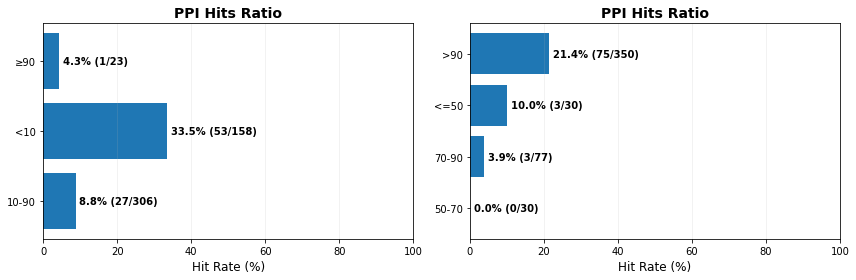

In [ ]:
# Set the proper order for pLDDT categories
plddt_order = ["<=50", "50-70", "70-90", ">90"]

# First convert to pandas to set the categorical order, then back to polars
all_variants_df_ppi_pd = orf_distances.to_pandas()
all_variants_df_ppi_pd['pLDDT_Category'] = pd.Categorical(
    all_variants_df_ppi_pd['pLDDT_Category'], 
    categories=plddt_order, 
    ordered=True
)
all_variants_df_ppi_pl = pl.from_pandas(all_variants_df_ppi_pd)

fig, axes = plt.subplots(1,2,figsize=(12,4))
plot_assay_hit_by_category(all_variants_df_ppi_pl.drop_nulls(subset='RSA_Category'), "ppi_hit", "RSA_Category", f"PPI Hits Ratio", ax=axes[0])
plot_assay_hit_by_category(all_variants_df_ppi_pl.drop_nulls(subset='pLDDT_Category'), "ppi_hit", "pLDDT_Category", f"PPI Hits Ratio", ax=axes[1])

## Balanced AUPRC

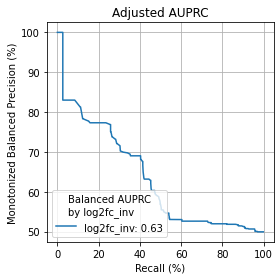

In [ ]:
sys.path.insert(1, "../../../4_compare_ai_scores/2_analysis/scripts")
from yogiroc import *

def plot_adjusted_pr_curves(df_clinvar_w_scores, label, pos_labels, methods, monotonized_flag=True, balanced_flag=True, subsample=False, n_bootstrap=1000, random_state=None):
    """
    For each method, plot the adjusted PR curve (with both balanced and monotonized adjustments)
    and compute the adjusted AUPRC via bootstrapping. Also perform pairwise significance testing 
    of the AUPRC across different RSA categories.
    
    Parameters
    ----------
    df_clinvar_w_scores : Polars DataFrame
        Input data including columns "clinvar_clnsig_clean", category and predictor scores.
    methods : list of str
        List of method names corresponding to score columns in the data.
    set2_palette : list of str
        List of colors (e.g., from a color palette) to use for different RSA categories.
    n_bootstrap : int, optional
        Number of bootstrap iterations for significance testing (default is 1000).
    random_state : int or None, optional
        Seed for reproducibility.
    
    Returns
    -------
    ap_results : dict
        Dictionary of adjusted AUPRC values and bootstrap distributions, structured as:
          { method: { category: {"AP": <adjusted AUPRC>, "boot_ap": <bootstrap array> } } }
    significance : dict
        Dictionary mapping each method to a DataFrame of pairwise p-values comparing AUPRC between categories.
    """
    assert (balanced_flag and not subsample) or (subsample and not balanced_flag) or (not subsample and not balanced_flag)
    
    ap_results_dict = {}
    # sig_results_dict = {}
    fig, axes = plt.subplots(1, len(methods), figsize=(4 * len(methods), 4))
    if len(methods) == 1:
        axes = [axes]
        
    ap_results = {}  # to store adjusted AUPRC and bootstrap distributions
    for m_idx, met in enumerate(methods):
        ap_results[met] = {}
        # Filter data for current category and valid clinical labels.
        df_clin_per_method = df_clinvar_w_scores.with_columns(
            (
                pl.when(pl.col(label).is_in(pos_labels))
                .then(1)
                .otherwise(0)
            ).alias("clinvar_label")
        ).drop_nulls(subset=[label, met])
        
        # Convert to pandas DataFrame.
        df_pd = df_clin_per_method.to_pandas()
        if subsample:
            # Assume df is your existing DataFrame with a column named "label"
            # Find the minimum count among the two classes (0 and 1)
            min_count = df_pd['clinvar_label'].value_counts().min()
            # Group by the 'label' column and sample min_count rows from each group (without replacement)
            df_pd = df_pd.groupby('clinvar_label').apply(lambda x: x.sample(n=min_count, random_state=42)).reset_index(drop=True)

        # Convert clinvar_label to boolean.
        truth = df_pd["clinvar_label"].astype(bool)
        # Create a scores DataFrame (with one column).
        scores = df_pd[[met]]

        # Create the YogiROC2 object using the new YogiROC2() constructor.
        yrobj = YogiROC2(truth, scores, names=[met], high=True)
        # Get the performance table from the YogiROC2 object.
        table = yrobj.tables[met]

        if (monotonized_flag and balanced_flag):
            table = table.dropna()
        precision = configure_prec(table, monotonized_flag=monotonized_flag, balanced_flag=balanced_flag)
        recall = table["tpr_sens"].values
        # print(precision)
        # print(recall)
        ap = calc_auc(recall[~np.isnan(recall)], precision[~np.isnan(precision)])
        ap_results[met] = {"AUPRC": ap}

        # Plot the adjusted PR curve.
        axes[m_idx].plot(100 * recall, 100 * precision,
                        label=f"{met}: {ap:.2f}")
        # Plot chance level as a horizontal dashed line.
        prior = np.sum(truth) / df_pd.shape[0]
        if (not balanced_flag):
            axes[m_idx].axhline(y=100 * prior, color=set2_palette[plddt_cats.index(cat)], ls="--")
    
        # Customize the subplot.
        handles, labels = axes[methods.index(met)].get_legend_handles_labels()
        precision_label = "Precision (%)"
        title = f"AUPRC\nby {met}"
        
        if balanced_flag:
            precision_label = "Balanced " + precision_label
            title = "Balanced " + title
        if monotonized_flag:
            precision_label = "Monotonized " + precision_label
    
        axes[m_idx].legend(
                        loc="lower left",
                        title=title)
        axes[m_idx].set_xlabel("Recall (%)")
        axes[m_idx].set_ylabel(precision_label)
        axes[m_idx].set_title("Adjusted AUPRC")
        axes[m_idx].grid()

    # sig_results_dict[category] = significance

    plt.tight_layout()
    plt.show()
    # plt.subplots_adjust(wspace=0.04)
    
    return None ## , sig_results_dict

plot_adjusted_pr_curves(df_clinvar_w_scores=df.with_columns(
        (-pl.col("log2fc")).alias("log2fc_inv")
    ).filter(
        (pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely_pathogenic", "Benign", "Likely benign"]))
    ), 
    label="clinvar_clnsig_clean_pp_strict",
    pos_labels=["Pathogenic", "Likely_pathogenic"], 
    methods=["log2fc_inv"]
)

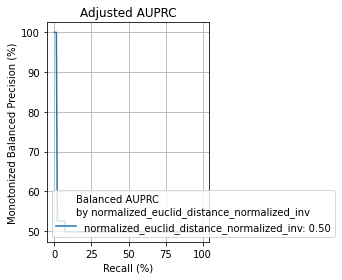

In [ ]:
plot_adjusted_pr_curves(df_clinvar_w_scores=orf_distances.with_columns(
        (-pl.col("normalized_euclid_distance_normalized")).alias("normalized_euclid_distance_normalized_inv")
    ).filter(
        (pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely_pathogenic", "Benign", "Likely benign"]))
    ), 
    label="clinvar_clnsig_clean_pp_strict",
    pos_labels=["Pathogenic", "Likely_pathogenic"], 
    methods=["normalized_euclid_distance_normalized_inv"]
)

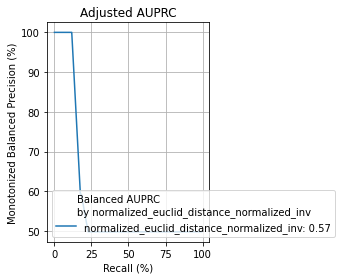

In [ ]:
plot_adjusted_pr_curves(df_clinvar_w_scores=orf_distances.with_columns(
        (-pl.col("normalized_euclid_distance_normalized")).alias("normalized_euclid_distance_normalized_inv")
    ).filter(
        (pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely_pathogenic", "Benign"]))#, "Likely benign"]))
    ), 
    label="clinvar_clnsig_clean_pp_strict",
    pos_labels=["Pathogenic", "Likely_pathogenic"], 
    methods=["normalized_euclid_distance_normalized_inv"]
)

In [ ]:
orf_distances.to_pandas()

,db_orf_id,db_mut_id,num_edges,clinvar_clnsig_clean,euclid_distance,nan_euclid_distance,mean_signed_difference,mean_log2fc,max_perturbation,std_perturbation,...,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,ppi_hit
0,13796,218140,2,Others,0.134432,0.154650,-0.109354,-0.195291,0.109354,0.000000,...,>90,10-90,None,None,None,Rare genetic hematologic disease,1,None,False,False
1,11805,2150,2,Conflicting,0.244520,0.244520,0.172902,0.638560,0.173324,0.000423,...,>90,10-90,613795,autosomal dominant,OMIM,Rare genetic vascular disease; Rare genetic sy...,2,LOEYS-DIETZ SYNDROME 3,False,False
2,70497,3843,1,Conflicting,0.326309,0.326309,0.326309,1.586849,0.326309,0.000000,...,>90,<10,259900,autosomal recessive,OMIM,Rare genetic eye disease; Rare genetic renal d...,3,"HYPEROXALURIA, PRIMARY, TYPE I",False,False
3,70497,3792,1,Pathogenic,0.000696,0.000696,0.000696,0.002054,0.000696,0.000000,...,>90,10-90,259900,autosomal recessive,OMIM,Rare genetic eye disease; Rare genetic renal d...,3,"HYPEROXALURIA, PRIMARY, TYPE I",False,False
4,52920,2677,15,Pathogenic,1.173497,1.173497,0.005896,0.811034,0.630297,0.302938,...,70-90,<10,601098,autosomal dominant,OMIM,Rare genetic neurological disorder,1,"CHARCOT-MARIE-TOOTH DISEASE, DEMYELINATING, TY...",False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
489,8999,203016,1,Pathogenic,0.392074,0.392074,-0.392074,-1.164874,0.392074,0.000000,...,>90,<10,105210;105210;115430;145680,autosomal dominant,OMIM,Rare genetic systemic or rheumatologic disease...,3,"AMYLOIDOSIS, HEREDITARY SYSTEMIC 1; AMYLOIDOSI...",False,False
490,71337,3950,3,Benign,0.952369,0.952369,0.529268,5.444465,0.739402,0.149035,...,>90,10-90,614265,autosomal recessive,OMIM,Rare inborn errors of metabolism,1,COMBINED MALONIC AND METHYLMALONIC ACIDURIA,False,False
491,8420,216662,1,Pathogenic,0.572140,0.572140,0.572140,3.726575,0.572140,0.000000,...,>90,10-90,300751,x-linked recessive,OMIM,Rare genetic renal disease; Rare genetic hemat...,4,"ANEMIA, SIDEROBLASTIC, 1",False,False
492,7982,202796,2,Others,1.053974,1.053974,0.744933,3.457548,0.767418,0.022484,...,None,None,None,None,None,Rare genetic renal disease; Rare genetic hemat...,4,None,False,True


In [ ]:
orf_distances.to_pandas()[orf_distances.to_pandas().clinvar_clnsig_clean_pp_strict.isin(["Benign"])][['gene_variant','symbol','aa_change','clinvar_clnsig_clean_pp_strict','normalized_euclid_distance_normalized']]

,gene_variant,symbol,aa_change,clinvar_clnsig_clean_pp_strict,normalized_euclid_distance_normalized
100,KRT8_Tyr54His,KRT8,Tyr54His,Benign,0.133771
153,KCNJ2_Ile258Thr,KCNJ2,Ile258Thr,Benign,0.742548
242,AGXT_Val326Ile,AGXT,Val326Ile,Benign,0.180828
243,VHL_Pro81Ser,VHL,Pro81Ser,Benign,0.360236
299,AGXT_Asn22Ser,AGXT,Asn22Ser,Benign,0.469845
355,KRT8_Gly434Ser,KRT8,Gly434Ser,Benign,0.207003
421,VHL_Pro25Leu,VHL,Pro25Leu,Benign,0.382717
438,VHL_Glu52Lys,VHL,Glu52Lys,Benign,0.218914


# Genes with signal?

In [ ]:
# def select_discriminating_genes(orf_distances, clinvar_col="clinvar_clnsig_clean_pp_strict", 
#                                 metric="normalized_euclid_distance_normalized",
#                                 min_pathogenic=2, min_benign=2, 
#                                 effect_size_threshold=0.3, p_value_threshold=0.05,
#                                 verbose=True):
#     """
#     Select genes that show significant discrimination between benign and pathogenic variants.
    
#     Parameters:
#     -----------
#     orf_distances : pl.DataFrame
#         DataFrame with variant-level scores and ClinVar annotations
#     clinvar_col : str
#         Column to use for ClinVar classification
#     metric : str
#         Column containing the score metric
#     min_pathogenic : int
#         Minimum number of pathogenic variants required per gene
#     min_benign : int
#         Minimum number of benign variants required per gene
#     effect_size_threshold : float
#         Minimum Cohen's d effect size (0.2=small, 0.5=medium, 0.8=large)
#     p_value_threshold : float
#         Maximum p-value for statistical significance
#     verbose : bool
#         Whether to print detailed statistics
        
#     Returns:
#     --------
#     tuple : (discriminating_genes, gene_stats_df)
#         - discriminating_genes: list of gene symbols that meet criteria
#         - gene_stats_df: pl.DataFrame with statistics for each gene
#     """
#     from scipy import stats
    
#     # Define pathogenic and benign categories
#     if clinvar_col == "clinvar_clnsig_clean_pp_strict":
#         pathogenic_categories = ['Pathogenic', 'Likely pathogenic']
#         benign_categories = ['Benign', 'Likely benign']
#     else:
#         pathogenic_categories = ['Pathogenic']
#         benign_categories = ['Benign']
    
#     # Convert to pandas for easier groupby operations
#     df_pd = orf_distances.to_pandas()
    
#     # Filter for genes with sufficient benign and pathogenic variants
#     gene_stats = []
    
#     for gene in df_pd['symbol'].unique():
#         if pd.isna(gene):
#             continue
            
#         gene_data = df_pd[df_pd['symbol'] == gene].copy()
        
#         # Get pathogenic and benign scores
#         path_scores = gene_data[
#             gene_data[clinvar_col].isin(pathogenic_categories)
#         ][metric].dropna()
        
#         benign_scores = gene_data[
#             gene_data[clinvar_col].isin(benign_categories)
#         ][metric].dropna()
        
#         # Skip if insufficient data
#         if len(path_scores) < min_pathogenic or len(benign_scores) < min_benign:
#             continue
        
#         # Calculate statistics
#         # Mann-Whitney U test (non-parametric)
#         statistic, p_value = stats.mannwhitneyu(path_scores, benign_scores, 
#                                                  alternative='two-sided')
        
#         # Cohen's d effect size
#         pooled_std = np.sqrt(
#             ((len(path_scores) - 1) * path_scores.std()**2 + 
#              (len(benign_scores) - 1) * benign_scores.std()**2) / 
#             (len(path_scores) + len(benign_scores) - 2)
#         )
#         cohens_d = abs(path_scores.mean() - benign_scores.mean()) / pooled_std if pooled_std > 0 else 0
        
#         # Area under ROC curve (simple version)
#         from sklearn.metrics import roc_auc_score
#         y_true = [1] * len(path_scores) + [0] * len(benign_scores)
#         y_scores = list(path_scores) + list(benign_scores)
#         try:
#             auroc = roc_auc_score(y_true, y_scores)
#         except:
#             auroc = 0.5
        
#         gene_stats.append({
#             'symbol': gene,
#             'db_orf_id': gene_data['db_orf_id'].iloc[0],
#             'n_pathogenic': len(path_scores),
#             'n_benign': len(benign_scores),
#             'pathogenic_mean': path_scores.mean(),
#             'pathogenic_median': path_scores.median(),
#             'benign_mean': benign_scores.mean(),
#             'benign_median': benign_scores.median(),
#             'mean_difference': path_scores.mean() - benign_scores.mean(),
#             'cohens_d': cohens_d,
#             'mannwhitney_p': p_value,
#             'auroc': auroc
#         })
    
#     # Convert to DataFrame
#     gene_stats_df = pl.DataFrame(gene_stats)
    
#     # Filter for discriminating genes
#     discriminating_genes_df = gene_stats_df.filter(
#         (pl.col('cohens_d') >= effect_size_threshold) &
#         (pl.col('mannwhitney_p') <= p_value_threshold)
#     ).sort('cohens_d', descending=True)
    
#     discriminating_genes = discriminating_genes_df['symbol'].to_list()
    
#     if verbose:
#         print(f"\n{'='*80}")
#         print(f"Gene Discrimination Analysis")
#         print(f"{'='*80}")
#         print(f"Total genes analyzed: {len(gene_stats)}")
#         print(f"Genes meeting criteria: {len(discriminating_genes)}")
#         print(f"\nCriteria:")
#         print(f"  - Min pathogenic variants: {min_pathogenic}")
#         print(f"  - Min benign variants: {min_benign}")
#         print(f"  - Min Cohen's d: {effect_size_threshold}")
#         print(f"  - Max p-value: {p_value_threshold}")
#         print(f"\nTop 10 discriminating genes:")
#         print(discriminating_genes_df.head(10).to_pandas().to_string(index=False))
#         print(f"{'='*80}\n")
    
#     return discriminating_genes, gene_stats_df

# # Use the function
# discriminating_genes, gene_stats = select_discriminating_genes(
#     orf_distances,
#     clinvar_col="clinvar_clnsig_clean_pp_strict",
#     metric="normalized_euclid_distance_normalized",
#     min_pathogenic=1,
#     min_benign=1,
#     effect_size_threshold=0.2,  # Medium effect size
#     p_value_threshold=0.7,
#     verbose=True
# )

# # Filter your data to only these genes
# orf_distances_filtered = orf_distances.filter(
#     pl.col("symbol").is_in(discriminating_genes)
# )

# print(f"\nFiltered to {len(discriminating_genes)} genes with "
#       f"{orf_distances_filtered.height} variants")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3132905981.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3132905981.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(category_labels, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3132905981.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3132905981.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set

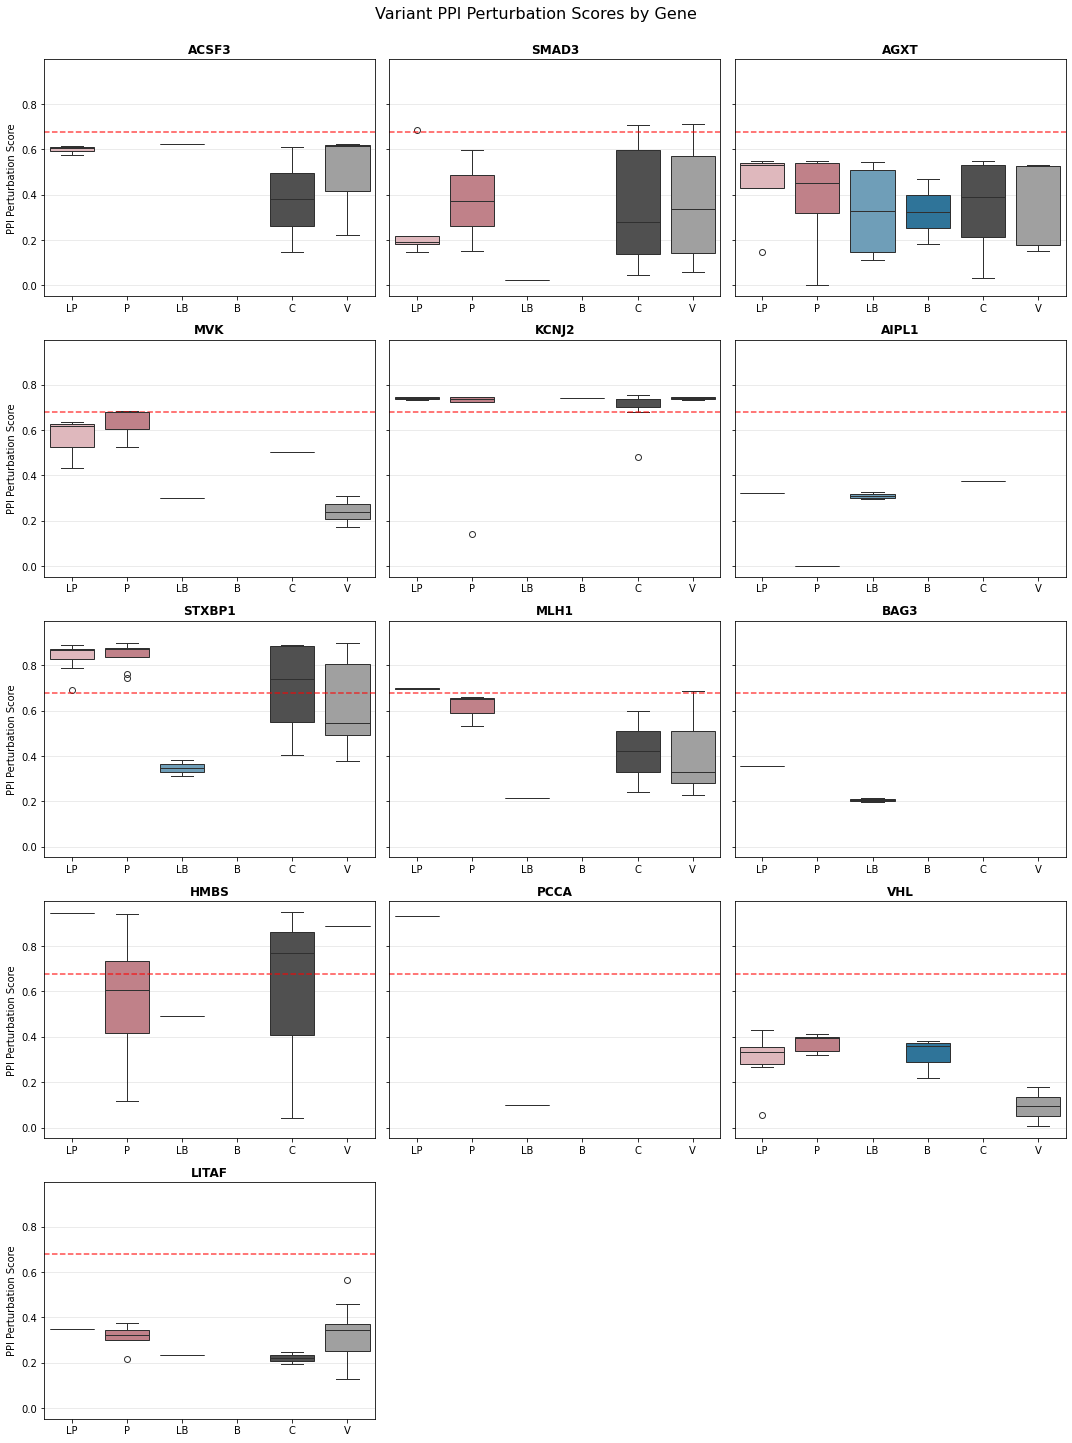

In [ ]:
# Collect all data for genes that have both pathogenic and benign variants
plot_data = []
gene_order = []

for gene_tuple in orf_distances.group_by("symbol"):
    gene = gene_tuple[0][0]  # First element is the gene name
    df = gene_tuple[1]     # Second element is the dataframe
    
    clinvar_classes = df["clinvar_clnsig_clean_pp_strict"].unique()
    has_pathogenic = any(x in clinvar_classes for x in ["Pathogenic", "Likely pathogenic"])
    has_benign = any(x in clinvar_classes for x in ["Benign", "Likely benign"])
    
    if has_pathogenic and has_benign:
        df_pd = df.to_pandas()
        df_pd['symbol'] = gene
        plot_data.append(df_pd)
        gene_order.append(gene)

# Define fixed order for categories
category_order = ["Likely pathogenic", "Pathogenic", "Likely benign", "Benign", "Conflicting", "VUS"]
category_labels = ["LP", "P", "LB", "B", "C", "V"]

# Create subplots
if plot_data:
    n_genes = len(gene_order)
    n_cols = 3  # Number of columns in the subplot grid
    n_rows = int(np.ceil(n_genes / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows), sharey=True)
    axes = axes.flatten() if n_genes > 1 else [axes]
    
    for idx, gene in enumerate(gene_order):
        ax = axes[idx]
        
        # Filter data for this gene
        gene_df = plot_data[idx]
        
        # Create boxplot for this gene with categories on x-axis
        sns.boxplot(
            data=gene_df,
            x="clinvar_clnsig_clean_pp_strict",
            y="normalized_euclid_distance_normalized",
            order=category_order,
            palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
            ax=ax
        )
        
        ax.axhline(y=0.678, color='red', linestyle='--', alpha=0.7)
        ax.set_title(f'{gene}', fontweight='bold')
        ax.set_ylabel("PPI Perturbation Score")
        ax.set_xlabel("")
        
        # Set custom x-tick labels
        ax.set_xticklabels(category_labels, rotation=0)
        ax.grid(alpha=0.3, axis='y')
    
    # Hide empty subplots
    for idx in range(n_genes, len(axes)):
        axes[idx].set_visible(False)
    
    plt.suptitle('Variant PPI Perturbation Scores by Gene', fontsize=16, y=1.00)
    plt.tight_layout()
    plt.show()
else:
    print("No genes found with both pathogenic and benign variants")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2233362604.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2233362604.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(category_labels, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2233362604.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2233362604.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set

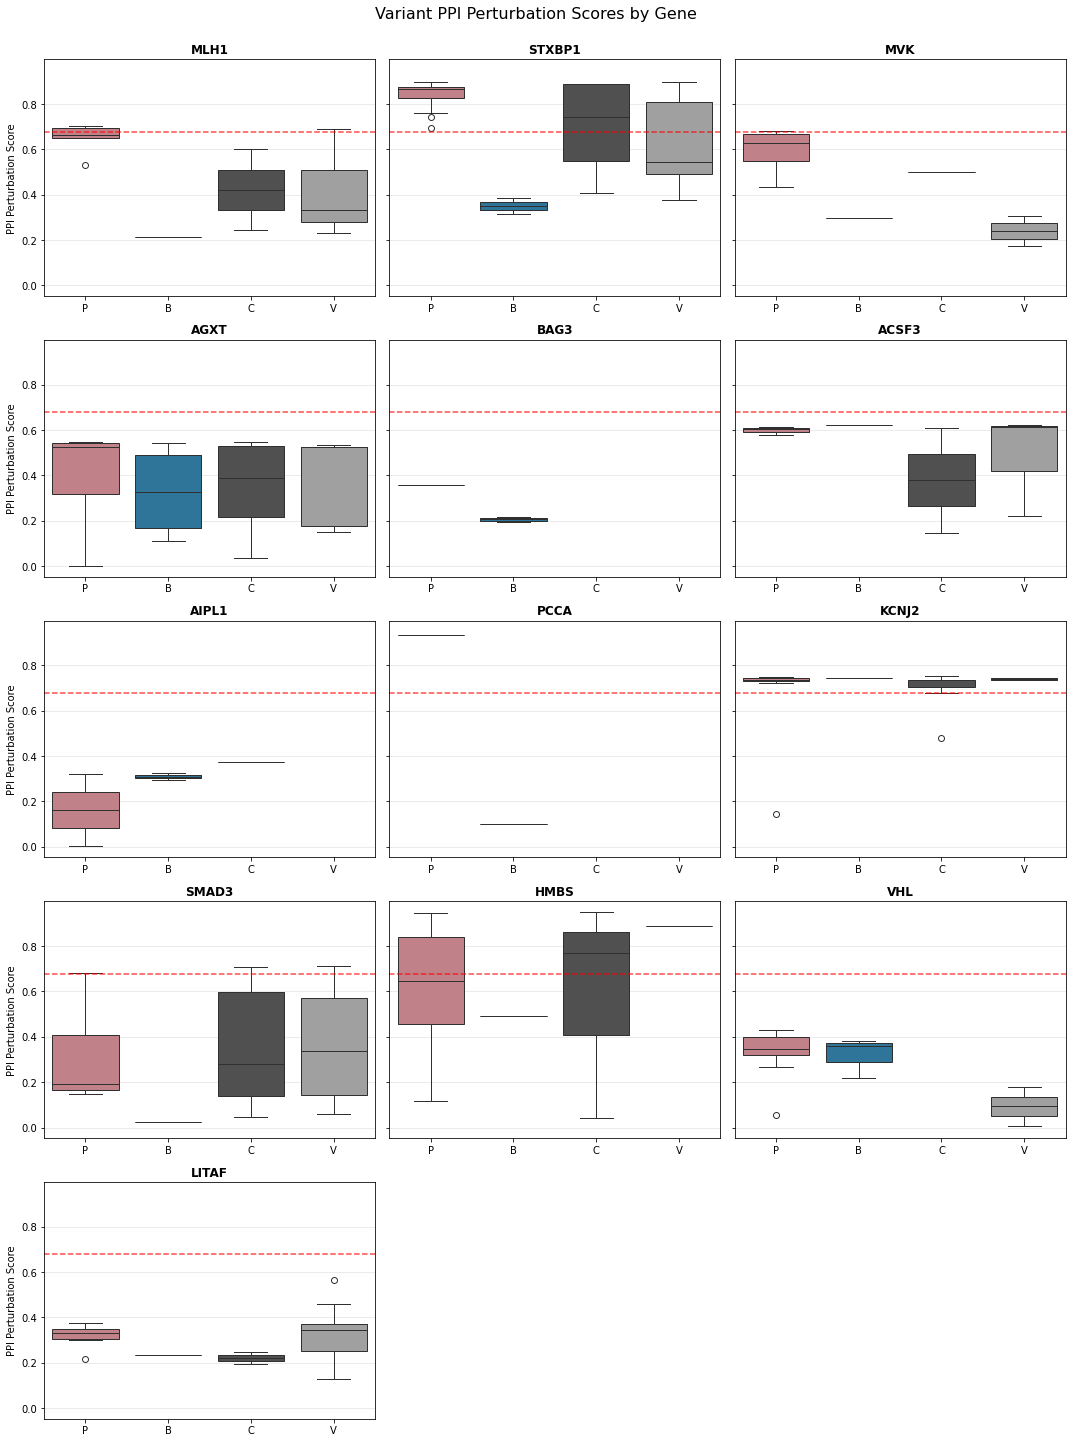

In [ ]:
# Collect all data for genes that have both pathogenic and benign variants
plot_data = []
gene_order = []

for gene_tuple in orf_distances.group_by("symbol"):
    gene = gene_tuple[0][0]  # First element is the gene name
    df = gene_tuple[1]     # Second element is the dataframe
    
    clinvar_classes = df["clinvar_clnsig_clean"].unique()
    has_pathogenic = any(x in clinvar_classes for x in ["Pathogenic", "Likely pathogenic"])
    has_benign = any(x in clinvar_classes for x in ["Benign", "Likely benign"])
    
    if has_pathogenic and has_benign:
        df_pd = df.to_pandas()
        df_pd['symbol'] = gene
        plot_data.append(df_pd)
        gene_order.append(gene)

# Define fixed order for categories
category_order = ["Pathogenic","Benign", "Conflicting", "VUS"]
category_labels = ["P","B", "C", "V"]

# Create subplots
if plot_data:
    n_genes = len(gene_order)
    n_cols = 3  # Number of columns in the subplot grid
    n_rows = int(np.ceil(n_genes / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows), sharey=True)
    axes = axes.flatten() if n_genes > 1 else [axes]
    
    for idx, gene in enumerate(gene_order):
        ax = axes[idx]
        
        # Filter data for this gene
        gene_df = plot_data[idx]
        
        # Create boxplot for this gene with categories on x-axis
        sns.boxplot(
            data=gene_df,
            x="clinvar_clnsig_clean",
            y="normalized_euclid_distance_normalized",
            order=category_order,
            palette=palette_dict["clinvar_clnsig_clean"],
            ax=ax
        )
        
        ax.axhline(y=0.678, color='red', linestyle='--', alpha=0.7)
        ax.set_title(f'{gene}', fontweight='bold')
        ax.set_ylabel("PPI Perturbation Score")
        ax.set_xlabel("")
        
        # Set custom x-tick labels
        ax.set_xticklabels(category_labels, rotation=0)
        ax.grid(alpha=0.3, axis='y')
    
    # Hide empty subplots
    for idx in range(n_genes, len(axes)):
        axes[idx].set_visible(False)
    
    plt.suptitle('Variant PPI Perturbation Scores by Gene', fontsize=16, y=1.00)
    plt.tight_layout()
    plt.show()
else:
    print("No genes found with both pathogenic and benign variants")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3445851691.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3445851691.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_with_counts, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3445851691.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/3445851691.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. af

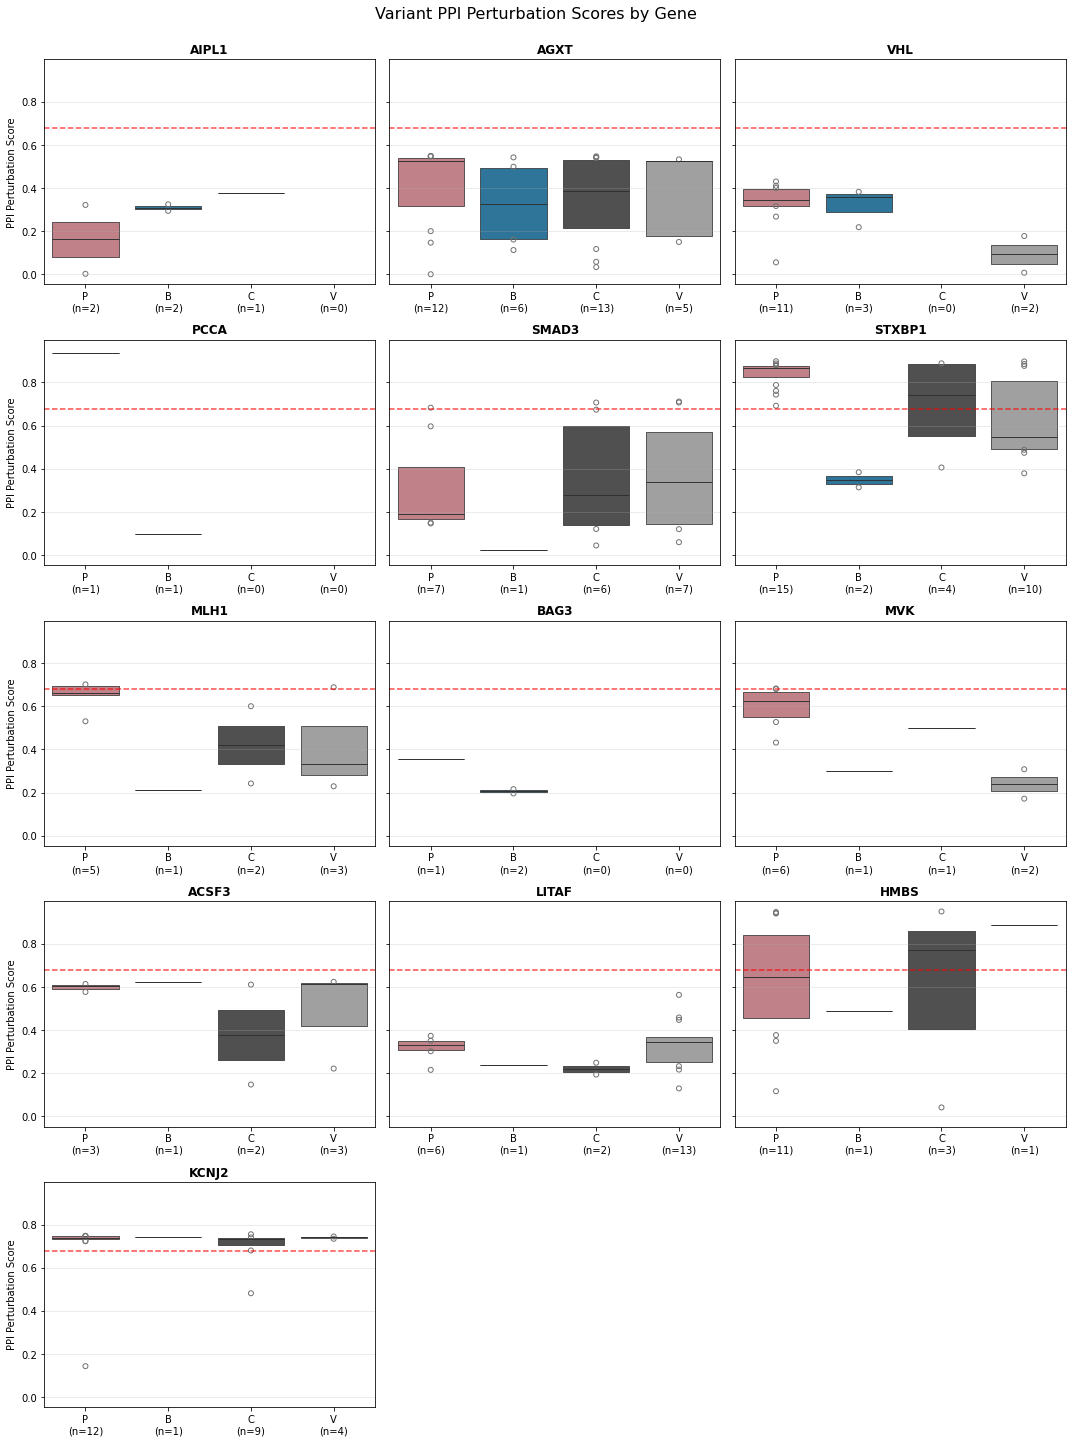

In [ ]:
# Collect all data for genes that have both pathogenic and benign variants
plot_data = []
gene_order = []

for gene_tuple in orf_distances.group_by("symbol"):
    gene = gene_tuple[0][0]  # First element is the gene name
    df = gene_tuple[1]     # Second element is the dataframe
    
    clinvar_classes = df["clinvar_clnsig_clean"].unique()
    has_pathogenic = any(x in clinvar_classes for x in ["Pathogenic", "Likely pathogenic"])
    has_benign = any(x in clinvar_classes for x in ["Benign", "Likely benign"])
    
    if has_pathogenic and has_benign:
        df_pd = df.to_pandas()
        df_pd['symbol'] = gene
        plot_data.append(df_pd)
        gene_order.append(gene)

# Define fixed order for categories
category_order = ["Pathogenic","Benign", "Conflicting", "VUS"]
category_labels = ["P","B", "C", "V"]

# Create subplots
if plot_data:
    n_genes = len(gene_order)
    n_cols = 3  # Number of columns in the subplot grid
    n_rows = int(np.ceil(n_genes / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows), sharey=True)
    axes = axes.flatten() if n_genes > 1 else [axes]
    
    for idx, gene in enumerate(gene_order):
        ax = axes[idx]
        
        # Filter data for this gene
        gene_df = plot_data[idx]
        
        # Create boxplot for this gene with categories on x-axis
        sns.boxenplot(
            data=gene_df,
            x="clinvar_clnsig_clean",
            y="normalized_euclid_distance_normalized",
            order=category_order,
            palette=palette_dict["clinvar_clnsig_clean"],
            ax=ax
        )
        
        ax.axhline(y=0.678, color='red', linestyle='--', alpha=0.7)
        ax.set_title(f'{gene}', fontweight='bold')
        ax.set_ylabel("PPI Perturbation Score")
        ax.set_xlabel("")
        
        # Count variants per category and create labels with counts
        labels_with_counts = []
        for cat, label in zip(category_order, category_labels):
            count = len(gene_df[gene_df["clinvar_clnsig_clean"] == cat])
            labels_with_counts.append(f"{label}\n(n={count})")
        
        ax.set_xticklabels(labels_with_counts, rotation=0)
        ax.grid(alpha=0.3, axis='y')
    
    # Hide empty subplots
    for idx in range(n_genes, len(axes)):
        axes[idx].set_visible(False)
    
    plt.suptitle('Variant PPI Perturbation Scores by Gene', fontsize=16, y=1.00)
    plt.tight_layout()
    plt.show()
else:
    print("No genes found with both pathogenic and benign variants")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1982390700.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1982390700.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_with_counts, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1982390700.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(


No significant comparisons found at alpha=0.05 (FDR-corrected)
No significant comparisons found at alpha=0.05 (FDR-corrected)


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1982390700.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_with_counts, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1982390700.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1982390700.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_with_counts, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1982390700.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. A

No significant comparisons found at alpha=0.05 (FDR-corrected)
No significant comparisons found at alpha=0.05 (FDR-corrected)
No significant comparisons found at alpha=0.05 (FDR-corrected)
No significant comparisons found at alpha=0.05 (FDR-corrected)


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1982390700.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_with_counts, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1982390700.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1982390700.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_with_counts, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1982390700.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. A

No significant comparisons found at alpha=0.05 (FDR-corrected)
No significant comparisons found at alpha=0.05 (FDR-corrected)
No significant comparisons found at alpha=0.05 (FDR-corrected)


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1982390700.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_with_counts, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1982390700.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1982390700.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_with_counts, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1982390700.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. A

No significant comparisons found at alpha=0.05 (FDR-corrected)
No significant comparisons found at alpha=0.05 (FDR-corrected)
No significant comparisons found at alpha=0.05 (FDR-corrected)
No significant comparisons found at alpha=0.05 (FDR-corrected)


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1982390700.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_with_counts, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1982390700.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/1982390700.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_with_counts, rotation=0)


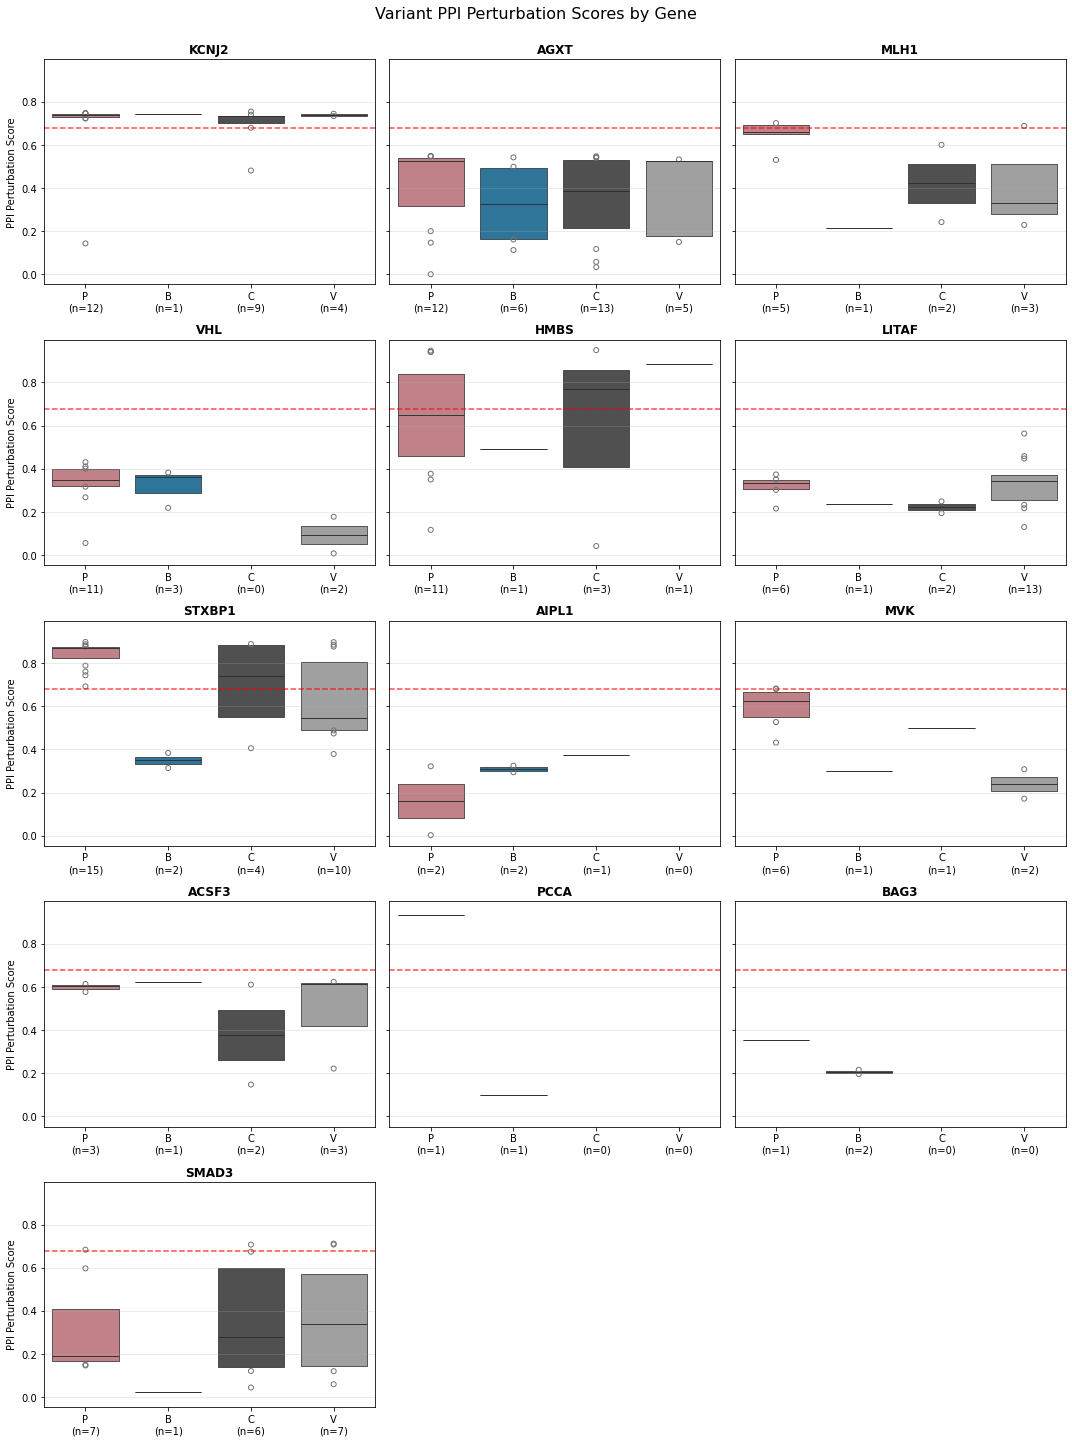

In [ ]:
# Collect all data for genes that have both pathogenic and benign variants
plot_data = []
gene_order = []

for gene_tuple in orf_distances.group_by("symbol"):
    gene = gene_tuple[0][0]  # First element is the gene name
    df = gene_tuple[1]     # Second element is the dataframe
    
    clinvar_classes = df["clinvar_clnsig_clean"].unique()
    has_pathogenic = any(x in clinvar_classes for x in ["Pathogenic", "Likely pathogenic"])
    has_benign = any(x in clinvar_classes for x in ["Benign", "Likely benign"])
    
    if has_pathogenic and has_benign:
        df_pd = df.to_pandas()
        df_pd['symbol'] = gene
        plot_data.append(df_pd)
        gene_order.append(gene)

# Define fixed order for categories
category_order = ["Pathogenic","Benign", "Conflicting", "VUS"]
category_labels = ["P","B", "C", "V"]

# Create subplots
if plot_data:
    n_genes = len(gene_order)
    n_cols = 3  # Number of columns in the subplot grid
    n_rows = int(np.ceil(n_genes / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows), sharey=True)
    axes = axes.flatten() if n_genes > 1 else [axes]
    
    for idx, gene in enumerate(gene_order):
        ax = axes[idx]
        
        # Filter data for this gene
        gene_df = plot_data[idx]
        
        # Create boxplot for this gene with categories on x-axis
        sns.boxenplot(
            data=gene_df,
            x="clinvar_clnsig_clean",
            y="normalized_euclid_distance_normalized",
            order=category_order,
            palette=palette_dict["clinvar_clnsig_clean"],
            ax=ax
        )
        
        # Add statistical annotations
        add_statistical_annotations(
            ax=ax,
            data=pl.DataFrame(gene_df),
            x_col="clinvar_clnsig_clean",
            y_col="normalized_euclid_distance_normalized",
            order=category_order,
            test='mannwhitneyu',
            comparisons='all_significant',
            alpha=0.05,
            y_offset_factor=0.03,  # Smaller offset for subplots
            fontsize=8,  # Smaller font for subplots,
            fdr_correction=True
        )
        
        ax.axhline(y=0.678, color='red', linestyle='--', alpha=0.7)
        ax.set_title(f'{gene}', fontweight='bold')
        ax.set_ylabel("PPI Perturbation Score")
        ax.set_xlabel("")
        
        # Count variants per category and create labels with counts
        labels_with_counts = []
        for cat, label in zip(category_order, category_labels):
            count = len(gene_df[gene_df["clinvar_clnsig_clean"] == cat])
            labels_with_counts.append(f"{label}\n(n={count})")
        
        ax.set_xticklabels(labels_with_counts, rotation=0)
        ax.grid(alpha=0.3, axis='y')
    
    # Hide empty subplots
    for idx in range(n_genes, len(axes)):
        axes[idx].set_visible(False)
    
    plt.suptitle('Variant PPI Perturbation Scores by Gene', fontsize=16, y=1.00)
    plt.tight_layout()
    plt.show()
else:
    print("No genes found with both pathogenic and benign variants")

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 212
Total unique db_orf_id: 13
Total Pathogenic variants: 92
Total Benign variants: 23


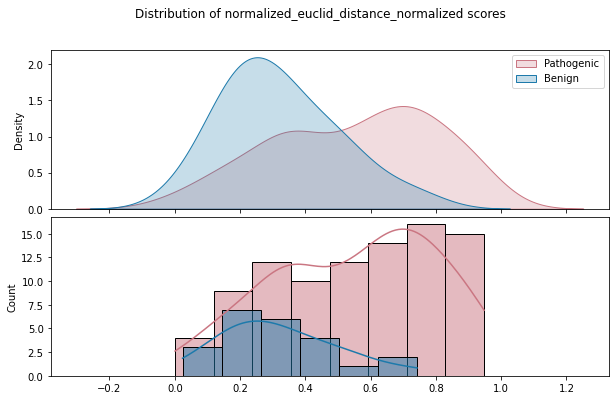

In [ ]:
path_ben_genes = []

for gene_tuple in orf_distances.group_by("symbol"):
    gene = gene_tuple[0][0]  # First element is the gene name
    df = gene_tuple[1]     # Second element is the dataframe
    
    clinvar_classes = df["clinvar_clnsig_clean_pp_strict"].unique()
    has_pathogenic = any(x in clinvar_classes for x in ["Pathogenic", "Likely pathogenic"])
    has_benign = any(x in clinvar_classes for x in ["Benign", "Likely benign"])
    
    if has_pathogenic and has_benign:
        path_ben_genes.append(gene)
        
orf_distances_path_ben = orf_distances.filter(
    pl.col("symbol").is_in(path_ben_genes)
)

plot_patho_benign(orf_distances_path_ben)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/630350873.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/630350873.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


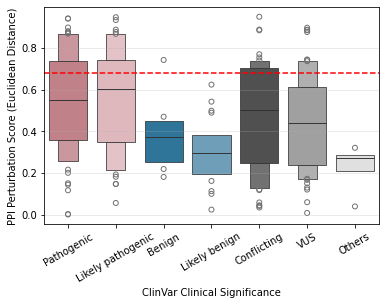

In [ ]:

order = ["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]

ax = sns.boxenplot(
    data=orf_distances_path_ben,
    x="clinvar_clnsig_clean_pp_strict",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
plt.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.620)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/546843212.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/546843212.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


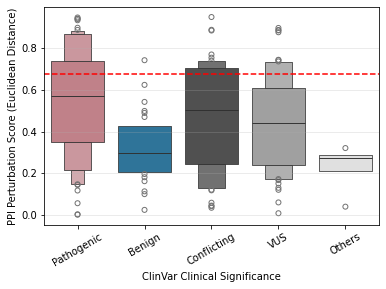

In [ ]:

order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

ax = sns.boxenplot(
    data=orf_distances_path_ben,
    x="clinvar_clnsig_clean",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
plt.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.620)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2798752247.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2798752247.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


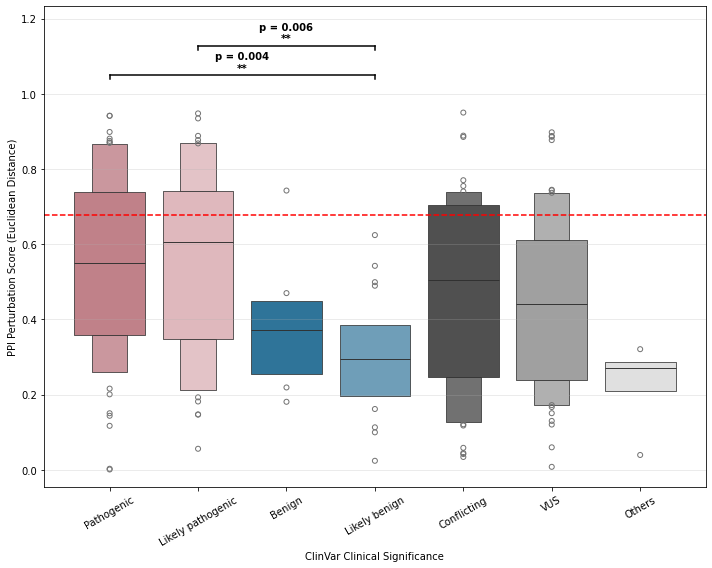


Significant Statistical Test Results (FDR-corrected, alpha=0.05)
Total comparisons: 21
Significant comparisons (FDR): 2
Significant comparisons (unadjusted): 8

Pathogenic vs Likely benign:
  Test: Mann-Whitney U
  Statistic: 722.0000
  P-value: 2.0590e-04
  P-value (FDR-adjusted): 4.3240e-03
  Reject null (FDR): True
  N1: 53, N2: 17
  Mean1: 0.5469, Mean2: 0.2960
  Median1: 0.5491, Median2: 0.2945
  Mean difference: 0.2509
  Significance: ** (very significant)

Likely pathogenic vs Likely benign:
  Test: Mann-Whitney U
  Statistic: 525.0000
  P-value: 5.8350e-04
  P-value (FDR-adjusted): 6.1267e-03
  Reject null (FDR): True
  N1: 39, N2: 17
  Mean1: 0.5526, Mean2: 0.2960
  Median1: 0.6053, Median2: 0.2945
  Mean difference: 0.2567
  Significance: ** (very significant)



In [ ]:
order = ["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]

fig, ax = plt.subplots(figsize=(10, 8))

sns.boxenplot(
    data=orf_distances_path_ben,
    x="clinvar_clnsig_clean_pp_strict",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
    ax=ax
)

# Test ALL possible combinations and show only significant ones
results = add_statistical_annotations(
    ax=ax,
    data=orf_distances_path_ben,
    x_col="clinvar_clnsig_clean_pp_strict",
    y_col="normalized_euclid_distance_normalized",
    order=order,
    test='mannwhitneyu',
    comparisons='all_significant',  # This tests all pairs and shows only significant
    alpha=0.05  # Can adjust significance threshold
)

ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.678)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.tight_layout()
plt.show()

# Print only significant results
print_statistical_summary(results, verbose=True, show_all=False)

# Or print all results
# print_statistical_summary(results, verbose=True, show_all=True)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/677254777.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/677254777.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


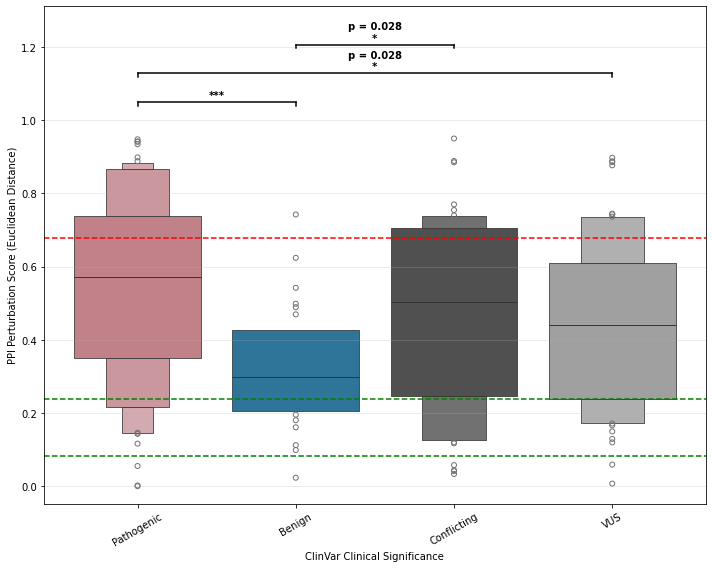


Significant Statistical Test Results (FDR-corrected, alpha=0.05)
Total comparisons: 6
Significant comparisons (FDR): 3
Significant comparisons (unadjusted): 4

Pathogenic vs Benign:
  Test: Mann-Whitney U
  Statistic: 1617.0000
  P-value: 9.4205e-05
  P-value (FDR-adjusted): 5.6523e-04
  Reject null (FDR): True
  N1: 92, N2: 23
  Mean1: 0.5493, Mean2: 0.3211
  Median1: 0.5709, Median2: 0.2991
  Mean difference: 0.2281
  Significance: *** (highly significant)

Pathogenic vs VUS:
  Test: Mann-Whitney U
  Statistic: 2875.0000
  P-value: 1.4137e-02
  P-value (FDR-adjusted): 2.8274e-02
  Reject null (FDR): True
  N1: 92, N2: 50
  Mean1: 0.5493, Mean2: 0.4443
  Median1: 0.5709, Median2: 0.4416
  Mean difference: 0.1050
  Significance: * (significant)

Benign vs Conflicting:
  Test: Mann-Whitney U
  Statistic: 310.0000
  P-value: 1.3282e-02
  P-value (FDR-adjusted): 2.8274e-02
  Reject null (FDR): True
  N1: 23, N2: 43
  Mean1: 0.3211, Mean2: 0.4778
  Median1: 0.2991, Median2: 0.5046
  Mean 

In [ ]:
order = ["Pathogenic", "Benign", "Conflicting", "VUS"]#, "Others"]

fig, ax = plt.subplots(figsize=(10, 8))

sns.boxenplot(
    data=orf_distances_path_ben,
    x="clinvar_clnsig_clean",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
    ax=ax
)

# Test ALL possible combinations and show only significant ones
results = add_statistical_annotations(
    ax=ax,
    data=orf_distances_path_ben,
    x_col="clinvar_clnsig_clean",
    y_col="normalized_euclid_distance_normalized",
    order=order,
    test='mannwhitneyu',
    comparisons='all_significant',  # This tests all pairs and shows only significant
    alpha=0.05,  # Can adjust significance threshold
    fdr_correction=True
)

ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.678)')
ax.axhline(y=0.083, color='green', linestyle='--', label='LLR Threshold (0.620)')
ax.axhline(y=0.238, color='green', linestyle='--', label='LLR Threshold (0.620)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.tight_layout()
plt.show()

# Print only significant results
print_statistical_summary(results, verbose=True, show_all=False)

# Or print all results
# print_statistical_summary(results, verbose=True, show_all=True)

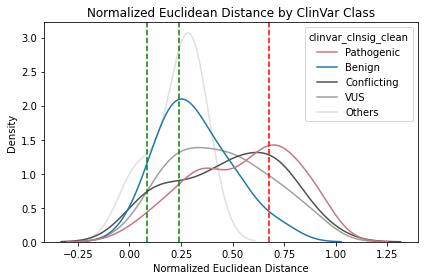

In [ ]:
hue_order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

sns.kdeplot(
    data=orf_distances_path_ben,
    x='normalized_euclid_distance_normalized',
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    # palette=[color_map.get(k, "gray") for k in hue_order],
    palette=palette_dict['clinvar_clnsig_clean'],
    common_norm=False
)

plt.axvline(x=0.678, color='red', linestyle='--', label='LLR Threshold (0.678)')
plt.axvline(x=0.083, color='green', linestyle='--', label='LLR Threshold (0.620)')
plt.axvline(x=0.238, color='green', linestyle='--', label='LLR Threshold (0.620)')
plt.title('Normalized Euclidean Distance by ClinVar Class')
plt.xlabel('Normalized Euclidean Distance')
plt.tight_layout()
plt.show()

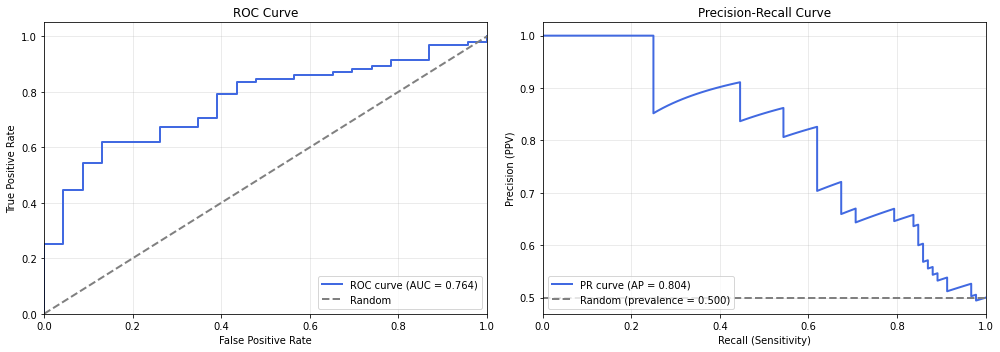

{'auroc': 0.7641776937618147,
 'auprc': 0.8035945588195634,
 'optimal_threshold': -0.5236399931898811,
 'sensitivity': 0.6195652173913043,
 'specificity': 0.8695652173913043,
 'precision': 0.8260869565217391,
 'npv': 0.6956521739130435,
 'accuracy': 0.7445652173913043,
 'n_variants': 184,
 'n_pathogenic': 92,
 'n_benign': 92,
 'fpr': array([0.        , 0.        , 0.        , 0.04347826, 0.04347826,
        0.08695652, 0.08695652, 0.13043478, 0.13043478, 0.26086957,
        0.26086957, 0.34782609, 0.34782609, 0.39130435, 0.39130435,
        0.43478261, 0.43478261, 0.47826087, 0.47826087, 0.56521739,
        0.56521739, 0.65217391, 0.65217391, 0.69565217, 0.69565217,
        0.73913043, 0.73913043, 0.7826087 , 0.7826087 , 0.86956522,
        0.86956522, 0.95652174, 0.95652174, 1.        , 1.        ]),
 'tpr': array([0.        , 0.01086957, 0.25      , 0.25      , 0.44565217,
        0.44565217, 0.54347826, 0.54347826, 0.61956522, 0.61956522,
        0.67391304, 0.67391304, 0.70652174, 

In [ ]:
evaluate_classification_performance(orf_distances_path_ben,
    clinvar_col="clinvar_clnsig_clean_pp_strict",
    metric_col="normalized_euclid_distance_normalized",
    balance_dataset=True
)

## LLR path ben

In [ ]:
orf_distances_path_ben.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Benign", "Likely pathogenic", "Likely benign"])
).with_columns(
    pl.when(
        pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
    )
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("gene_variant").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "normalized_euclid_distance_normalized", "gene_variant", "clinvar_clnsig_clean_pp_strict"])
).write_csv("../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_referenceSet.csv")

orf_distances_path_ben.with_columns(
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("gene_variant").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_allScores.csv")

In [ ]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_bcv.log" --bandwidth "bcv" --printTransitions  --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_default.log" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_nrd.log" --bandwidth "nrd" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_sj.log" --printTransitions --bandwidth "SJ" --kernel "gaussian" --outlierSuppression 0.1

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-12-16_14:39:21 INFO: Reading input 
2025-12-16_14:39:21 INFO: Calculating densties 


Warning messages:
1: In stats::bw.bcv(data) : minimum occurred at one end of the range
2: In stats::bw.bcv(data) : minimum occurred at one end of the range
3: In stats::bw.bcv(data) : minimum occurred at one end of the range


2025-12-16_14:39:22 INFO: Drawing LLR plot 
2025-12-16_14:39:22 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-16_14:39:23 INFO: Category transitions:  
0.291 : benign.support -> none
0.624 : none -> patho.support
0.743 : patho.support -> patho.moderate
0.932 : patho.moderate -> patho.strong
2025-12-16_14:39:23 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-12-16_14:39:23 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_score_bcv.csv 
2025-12-16_14:39:23 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


...

2025-12-16_14:39:26 INFO: Drawing LLR plot 
2025-12-16_14:39:26 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-16_14:39:26 INFO: Category transitions:  
0.018 : none -> benign.support
0.080 : benign.support -> benign.strong
0.095 : benign.strong -> benign.support
0.130 : benign.support -> none
0.161 : none -> benign.support
0.188 : benign.support -> none
0.216 : none -> benign.support
0.304 : benign.support -> none
0.438 : none -> benign.support
0.458 : benign.support -> benign.strong
0.497 : benign.strong -> benign.support
0.509 : benign.support -> none
0.525 : none -> patho.support
0.555 : patho.support -> none
0.648 : none -> patho.support
0.689 : patho.support -> patho.moderate
0.694 : patho.moderate -> patho.support
0.712 : patho.support -> patho.moderate
0.765 : patho.moderate -> patho.support
0.775 : patho.support -> none
0.809 : none -> benign.support
0.835 : benign.support -> none
0.843 : none -> patho.support
0.

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-12-16_14:39:27 INFO: Reading input 
2025-12-16_14:39:27 INFO: Calculating densties 
2025-12-16_14:39:28 INFO: Drawing LLR plot 
2025-12-16_14:39:28 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-16_14:39:28 INFO: Category transitions:  
0.297 : benign.support -> none
0.617 : none -> patho.support
0.734 : patho.support -> patho.moderate
0.904 : patho.moderate -> patho.strong
2025-12-16_14:39:28 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-12-16_14:39:28 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_score_nrd.csv 
2025-12-16_14:39:28 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-12-16_14:39:28 INFO: Reading input 
2025-12-16_14:39:29 INFO: Calculating densties 
2025-12-16_14:39:29 INFO: Drawing LLR plot 
2025-12-16_14:39:30 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-16_14:39:30 INFO: Category transitions:  
0.281 : benign.support -> none
0.618 : none -> patho.support
0.728 : patho.support -> patho.moderate
0.918 : patho.moderate -> patho.strong
2025-12-16_14:39:30 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-12-16_14:39:30 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_score_sj.csv 
2025-12-16_14:39:30 INFO: Done! 


In [ ]:
# 0.083 : none -> benign.support
# 0.328 : benign.support -> none
# 0.639 : none -> patho.support
# 0.731 : patho.support -> patho.moderate

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2817514769.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_89285/2817514769.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


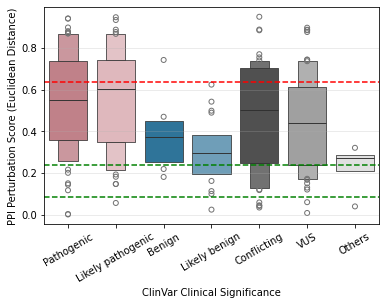

In [ ]:

order = ["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]

ax = sns.boxenplot(
    data=orf_distances_path_ben,
    x="clinvar_clnsig_clean_pp_strict",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
)

ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
plt.axhline(y=0.639, color='red', linestyle='--', label='LLR Threshold (0.620)')
plt.axhline(y=0.083, color='green', linestyle='--', label='LLR Threshold (0.620)')
plt.axhline(y=0.238, color='green', linestyle='--', label='LLR Threshold (0.620)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()


Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 212
Total unique db_orf_id: 13
Total Pathogenic variants: 92
Total Benign variants: 23
fixed_threshold: 0.639


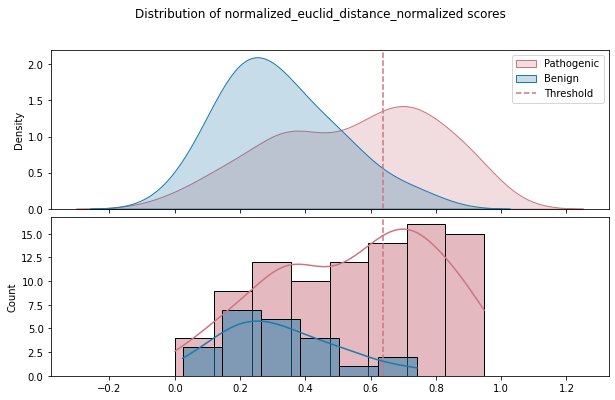

Benign: 1 (4.35%)
Pathogenic: 40 (43.48%)
VUS: 11 (22.00%)
Conflicting: 14 (32.56%)


In [ ]:
plot_patho_benign(orf_distances_path_ben, fixed_threshold=0.639)

In [ ]:
orf_distances_path_ben

db_orf_id,db_mut_id,num_edges,clinvar_clnsig_clean,euclid_distance,nan_euclid_distance,mean_signed_difference,mean_log2fc,max_perturbation,std_perturbation,cv_perturbation,gini_coefficient,edges_disrupted_pct,max_to_mean_ratio,top3_edges_contribution_pct,median_abs_deviation,normalized_euclid_distance,normalized_nan_euclid_distance,normalized_euclid_distance_normalized,normalized_nan_euclid_distance_normalized,max_perturbation_normalized,symbol,aa_change,gene_variant,spdi,nt_change,chr_num,nuc_loc,ref_allele,alt_allele,Chrom,ensembl_gene_id,ccsb_mutation_id,ccsb_allele_id,ensembl_protein_id,collection,entry_plate_orig,…,g2p_O-GlcNAc,g2p_Peptide (UniProt),g2p_Phi angle (degrees)*,g2p_Phosphorylation,g2p_Pocket number (fpocket)*,g2p_Propeptide (UniProt),g2p_Psi angle (degrees)*,g2p_Region (UniProt),g2p_Regulatory sites,g2p_Repeat (UniProt),g2p_SNP-associated PTMs,g2p_SUMOylation,g2p_Secondary structure (DSSP 3-state)*,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,ppi_hit
i64,i64,i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,i64,i64,str,str,str,str,str,str,str,str,str,…,str,str,f64,str,str,str,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,i64,str,bool,bool
11805,2150,2,"""Conflicting""",0.24452,0.24452,0.172902,0.63856,0.173324,0.000423,0.002444,0.001222,0.0,1.002444,100.0,0.000423,0.172902,0.172902,0.196267,0.196267,0.183043,"""SMAD3""","""Pro263Leu""","""SMAD3_Pro263Leu""","""NC_000015.10:67181370:C:T""","""788C>T""",15,67181370,"""C""","""T""","""15""","""ENSG00000166949""","""CCSBVarC004695""","""ALE00004695""","""ENSP00000332973.4""","""Edgotyping3""","""VUSMutGDEh005""",…,null,null,-86.7,null,null,null,-9.0,null,null,null,null,null,"""C (loop/coil)""","""S (bend)""",null,null,null,null,null,null,null,null,null,null,null,92.14,80.14706,""">90""","""10-90""","""613795""","""autosomal dominant""","""OMIM""","""Rare genetic vascular disease;…",2,"""LOEYS-DIETZ SYNDROME 3""",false,false
70497,3843,1,"""Conflicting""",0.326309,0.326309,0.326309,1.586849,0.326309,0.0,0.0,0.0,100.0,1.0,100.0,0.0,0.326309,0.326309,0.370405,0.370405,0.344607,"""AGXT""","""Asp201Asn""","""AGXT_Asp201Asn""","""NC_000002.12:240873983:G:A""","""601G>A""",2,240873983,"""G""","""A""","""2""","""ENSG00000172482""","""CCSBVarC008203""","""ALE00008189""","""ENSP00000302620.3""","""Edgotyping3""","""VUSMutGDEh004""",…,null,null,-88.2,null,null,null,-36.7,null,null,null,null,null,"""C (loop/coil)""","""S (bend)""","""Beta strand""",null,null,null,null,null,null,null,null,null,null,98.96,2.4539876,""">90""","""<10""","""259900""","""autosomal recessive""","""OMIM""","""Rare genetic eye disease; Rare…",3,"""HYPEROXALURIA, PRIMARY, TYPE I""",false,false
70497,3792,1,"""Pathogenic""",0.000696,0.000696,0.000696,0.002054,0.000696,0.0,0.0,0.0,0.0,1.0,100.0,0.0,0.000696,0.000696,0.00079,0.00079,0.000735,"""AGXT""","""Gly41Glu""","""AGXT_Gly41Glu""","""NC_000002.12:240868987:G:A""","""122G>A""",2,240868987,"""G""","""A""","""2""","""ENSG00000172482""","""CCSBVarC008165""","""ALE00008151""","""ENSP00000302620.3""","""Edgotyping3""","""VUSMutGDEh003""",…,null,null,-66.1,null,null,null,-18.0,null,null,null,null,null,"""C (loop/coil)""","""T (turn)""","""Helix""",null,null,null,null,null,null,null,null,null,null,98.26,51.19048,""">90""","""10-90""","""259900""","""autosomal recessive""","""OMIM""","""Rare genetic eye disease; Rare…",3,"""HYPEROXALURIA, PRIMARY, TYPE I""",false,false
52920,2677,15,"""Pathogenic""

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 24
Total unique db_orf_id: 4
Total Pathogenic variants: 0
Total Benign variants: 8


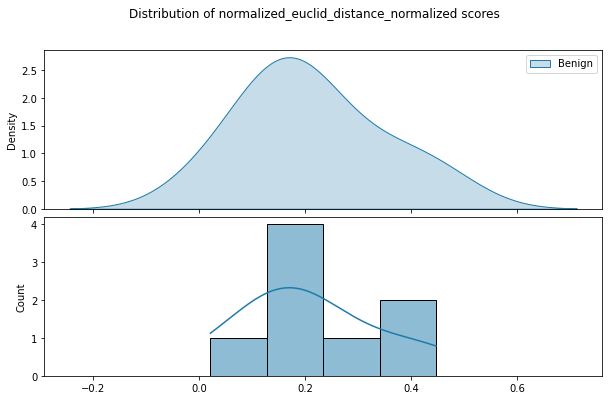

In [ ]:
# has benign and no pathogenic
# has benign and no pathogenic
benign_no_path_genes = []

for gene_tuple in orf_distances.group_by("symbol"):
    gene = gene_tuple[0][0]  # First element is the gene name
    df = gene_tuple[1]     # Second element is the dataframe
    
    clinvar_classes = df["clinvar_clnsig_clean_pp_strict"].unique()
    has_pathogenic = any(x in clinvar_classes for x in ["Pathogenic", "Likely pathogenic"])
    has_benign = any(x in clinvar_classes for x in ["Benign", "Likely benign"])
    
    if has_benign and not has_pathogenic:
        benign_no_path_genes.append(gene)
        
orf_distances_benign_no_path = orf_distances.filter(
    pl.col("symbol").is_in(benign_no_path_genes)
)

plot_patho_benign(orf_distances_benign_no_path)

In [ ]:
orf_distances_benign_no_path.to_pandas().db_orf_id.unique()

array([ 3980, 54308, 14966,  3438])